# Sunspots Forecasting with Dense, Simple RNN, LSTM and GRU Networks
**Course:** Advanced Machine Learning and Deep Learning, SUPSI  
**Student:** Mattia Loi  
**Date:** November 2026

---

**Goal.** Predict the monthly mean total sunspot number one month and six months ahead from the past values of the series, and compare a Dense network with three recurrent networks: Simple RNN, LSTM and GRU.

| Section | Content |
| :---: | :--- |
| 0 | setup and configuration |
| 1 | data loading and exploratory analysis |
| 2 | sliding windows, split in time and scaling |
| 3 | shared code: models, training, metrics and plots |
| 4 | one-step forecast: Simple RNN vs Dense network |
| 5 | six-step forecast: recursive vs direct approach |
| 6 | LSTM and GRU on both horizons |
| 7 | conclusions |

**Running the notebook.** It requires `torch`, `scikit-learn`, `umap-learn`, `scipy`, `pandas`, `matplotlib` and `seaborn`. The trained models are loaded from `saved_models/` when the folder is present; without it every model is trained from scratch (about 70 minutes on a CPU), with the same results thanks to the fixed seeds.

## INDEX
0. Setup, Reproducibility & Global Configuration
1. Dataset Acquisition & Exploratory Data Analysis (EDA)
   - 1.1 Data loading & continuity check
   - 1.2 Exploratory Data Analysis & Solar Cycle Periodicity
   - 1.3 Outliers
   - 1.4 Correlation with past months & lookback window
2. Temporal Windowing (Sliding Window) & Dataset Partitioning
   - 2.1 Sliding windows
   - 2.2 Split in time & scaling
   - 2.3 Windows for each split
   - 2.4 DataLoader
3. Shared Utilities
   - 3.1 Models
   - 3.2 Training
   - 3.3 Predictions, metrics & baselines
   - 3.4 Plots
4. One-Step-Ahead Forecasting: Simple RNN vs Dense Network
   - 4.1 Baselines
   - 4.2 Dense network
   - 4.3 Simple RNN: value or change
   - 4.4 Hyperparameter selection
   - 4.5 Evaluation on the test set
   - 4.6 Discussion
5. Multi-Step Forecasting (6 Months Ahead): Recursive vs Direct
   - 5.1 Two multi-step approaches
   - 5.2 Approach 1: Recursive
   - 5.3 Approach 2: Direct
   - 5.4 Comparison on the validation set
   - 5.5 Evaluation on the test set
   - 5.6 Discussion: which approach works better?
6. Gated Recurrent Networks: LSTM & GRU
   - 6.1 Theoretical background
   - 6.2 Configuration of LSTM and GRU
   - 6.3 One-step forecast with LSTM and GRU
   - 6.4 Six-step forecast with LSTM and GRU
   - 6.5 Comparative plots
   - 6.6 Hidden states: PCA and UMAP
   - 6.7 Parameter count & computational cost
7. Conclusions
   - 7.1 Final comparison on the test set
   - 7.2 Findings
   - 7.3 References

---
## 0. Setup, Reproducibility & Global Configuration

Libraries, random seed and all the settings of the notebook, in one place.
- **Reproducibility:** fixed seed (67) for NumPy and PyTorch, deterministic GPU operations.
- **Settings:** window length, split ratios, model sizes and training parameters are defined once in the configuration cell and used everywhere.
- **Saved models:** every trained model is stored in `saved_models/` and loaded at the next run instead of being trained again.

In [1]:
# Standard library
import copy        # copy of the best weights during early stopping 
import hashlib     # fingerprint of the settings in the names of the saved models 
import json        # settings written as text to compute the fingerprint 
import os          # folders and paths of the saved models 
import time        # training time of each model 
import warnings    # to hide library warnings that do not change the results

# Data and plots
import numpy as np                                # arrays and numerical computations
import pandas as pd                               # time series with the dates as index
import matplotlib.pyplot as plt                   # figures
import seaborn as sns                             # style of the figures
from scipy import stats                           # skewness and Q-Q plot of the transformed values
from sklearn.pipeline import make_pipeline        # square root followed by MinMax, as one scaler
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, StandardScaler   # square root; scaling
from sklearn.decomposition import PCA            # linear projection of the hidden states
import umap                                       # non-linear projection of the hidden states (pip install umap-learn)

# Neural networks
import torch
import torch.nn as nn                                    # layers (Linear, RNN, LSTM, GRU) and MSE loss
import torch.optim as optim                              # Adam optimizer
from torch.utils.data import DataLoader, TensorDataset  # mini-batches of the training windows 

warnings.filterwarnings('ignore')

# Reproducibility: the same random numbers at every run
SEED = 67 # six-seven
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True   # deterministic GPU operations
torch.backends.cudnn.benchmark = False

# GPU if available, otherwise CPU
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__}, device: {DEVICE}, seed: {SEED}')

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.15.0+cu132, device: cpu, seed: 67


In [2]:
# Data and input windows
LOOKBACK_CANDIDATES = [24, 48, 63, 125]   # from the correlation 
LOOKBACK = 48                             # default window length, used until the choice
FORECAST_HORIZON = 6                      # months predicted by the multi-step models

# Split of the months (boundaries fixed in time): train + validation = 80%, test = 20%
TRAIN_RATIO = 0.7
VAL_RATIO = 0.1
TEST_RATIO = 0.2
N_FOLDS = 3                               # validation periods of the chronological validation 
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1) < 1e-9, 'the three ratios must sum to 1'

# Models
HIDDEN_SIZE = 64                          # default number of hidden units of every model
HIDDEN_CANDIDATES = [32, 64]              # compared on the validation set 
NUM_LAYERS = 1                            # recurrent layers
DROPOUT = 0.0                             # default dropout, applied before the output head 
DROPOUT_CANDIDATES = [0.0, 0.2]           # 0.2-0.3 is suggested for recurrent networks 

# Training
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
GRAD_CLIP = 1.0                           # maximum gradient norm, against exploding gradients
MAX_EPOCHS = 300
PATIENCE = 20                             # early stopping: epochs without improvement on validation
SEEDS = [SEED, SEED + 1, SEED + 2]        # seeds used to check the final results 

# Saved models 
MODELS_DIR = 'saved_models'
FORCE_RETRAIN = False                     # True: train every model again and overwrite the saved files
MODEL_VERSION = 1                         # increase after changing the code of a model or of fit()

In [3]:
# Style of the plots and one color per model, the same in every figure
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({
    'figure.figsize': (14, 5),
    'figure.dpi': 120,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'lines.linewidth': 1.5,
})

MODEL_COLORS = {
    'Ground Truth': '#2c3e50',
    'Dense':        '#e74c3c',
    'SimpleRNN':    '#3498db',
    'LSTM':         '#2ecc71',
    'GRU':          '#9b59b6',
    'Persistence':  '#7f8c8d',
    'Mean':         '#e67e22',
}

ZOOM_PERIOD = ('1950', '1960')            # strongest cycle, inside the test set: zoom of the forecast plots

---
## 1. Dataset Acquisition & Exploratory Data Analysis (EDA)

In this section we load the dataset, check that it is complete and explore it: the solar cycle, the outliers and how strongly each month depends on the previous ones. These results guide the choices of the next sections, in particular the length of the input window.

### 1.1 Data loading & continuity check

Each row of the dataset is one month, from January 1749 to December 1983, with the monthly mean total sunspot number, a measure of the activity of the Sun. The months are turned into dates and used as the index of the table.

Completeness is checked before any analysis. In a time series a missing month does not appear as an empty cell: it simply has no row. The models read windows of consecutive months, so every month must be present exactly once.

In this section we:
- read the CSV and index it by date;
- check the size of the table, the period covered, the type of the values and the empty cells;
- check that every month between the first and the last one is present exactly once.

In [4]:
# Address of the dataset
DATA_URL = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-sunspots.csv'

# Read the CSV: two columns, the month and the monthly mean sunspot number
df = pd.read_csv(DATA_URL, header=0, names=['Month', 'Sunspots'])

**Description of the datasets**


- **Number of observations** 
> 2820 rows / samples

- **Number of variables per observation** 
> 2 columns / features

- **Description of variables**
  | Variable Name | Description | Data Type |
  |---------------|-------------|-----------|
  | `Month` | Specific month. | str |
  | `Sunspots` | Monthly mean total sunspot number. | float |

In [5]:
# Turn the months (text such as '1749-01') into dates and use them as index, in chronological order
df['Month'] = pd.to_datetime(df['Month'])
df = df.set_index('Month').sort_index()

display(df.head())

,Sunspots
Month,
1749-01-01,58.0
1749-02-01,62.6
1749-03-01,70.0
1749-04-01,55.7
1749-05-01,85.0


In [6]:
# Size of the table, period covered and type of the values
print(f'Rows: {len(df)}, columns: {df.shape[1]}')
print(f'Period: {df.index.min():%Y-%m} to {df.index.max():%Y-%m}')
print(f'Type of the values: {df["Sunspots"].dtype}')

# Empty cells (NaN) in the column of the values
print(f'Missing values (NaN): {df["Sunspots"].isnull().sum()}')

Rows: 2820, columns: 1
Period: 1749-01 to 1983-12
Type of the values: float64
Missing values (NaN): 0


In [7]:
# Complete list of the months between the first and the last observation.
# freq='MS' means "month start", because every date in the CSV is the first day of the month.
expected_months = pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

# Three possible problems of the index
missing_months = expected_months.difference(df.index)      # months of the period not present in the data
unexpected_months = df.index.difference(expected_months)   # dates in the data that are not a month start
n_duplicates = df.index.duplicated().sum()                 # months that appear more than once

print(f'Months expected in the period: {len(expected_months)}')
print(f'Rows in the dataset: {len(df)}')
print(f'Missing months: {len(missing_months)}')
print(f'Unexpected dates: {len(unexpected_months)}')
print(f'Duplicated months: {n_duplicates}')

# If some months are missing, show the first ones
if len(missing_months) > 0:
    print(f'First missing months: {list(missing_months[:5].strftime("%Y-%m"))}')

# The series is continuous only if all three counts are zero
is_continuous = len(missing_months) == 0 and len(unexpected_months) == 0 and n_duplicates == 0
print(f'Series is continuous: {is_continuous}')

Months expected in the period: 2820
Rows in the dataset: 2820
Missing months: 0
Unexpected dates: 0
Duplicated months: 0
Series is continuous: True


### 1.2 Exploratory Data Analysis & Solar Cycle Periodicity

The series is studied before building any model, to understand what a model has to learn and which simple predictions it has to beat.

In this section we:
- compute the main statistics and plot the whole series, with two solar cycles highlighted and a zoom on 1900-1940;
- look at the distribution of the values, at the lag plot x(t) vs x(t-1) and at the monthly changes;
- compare two simple predictors: the mean of the series and the previous month (persistence);
- check whether there is a yearly seasonality.

count       2820.00
mean          51.27
std           43.45
min            0.00
25%           15.70
50%           42.00
75%           74.93
max          253.80
skewness       1.10
kurtosis       0.98


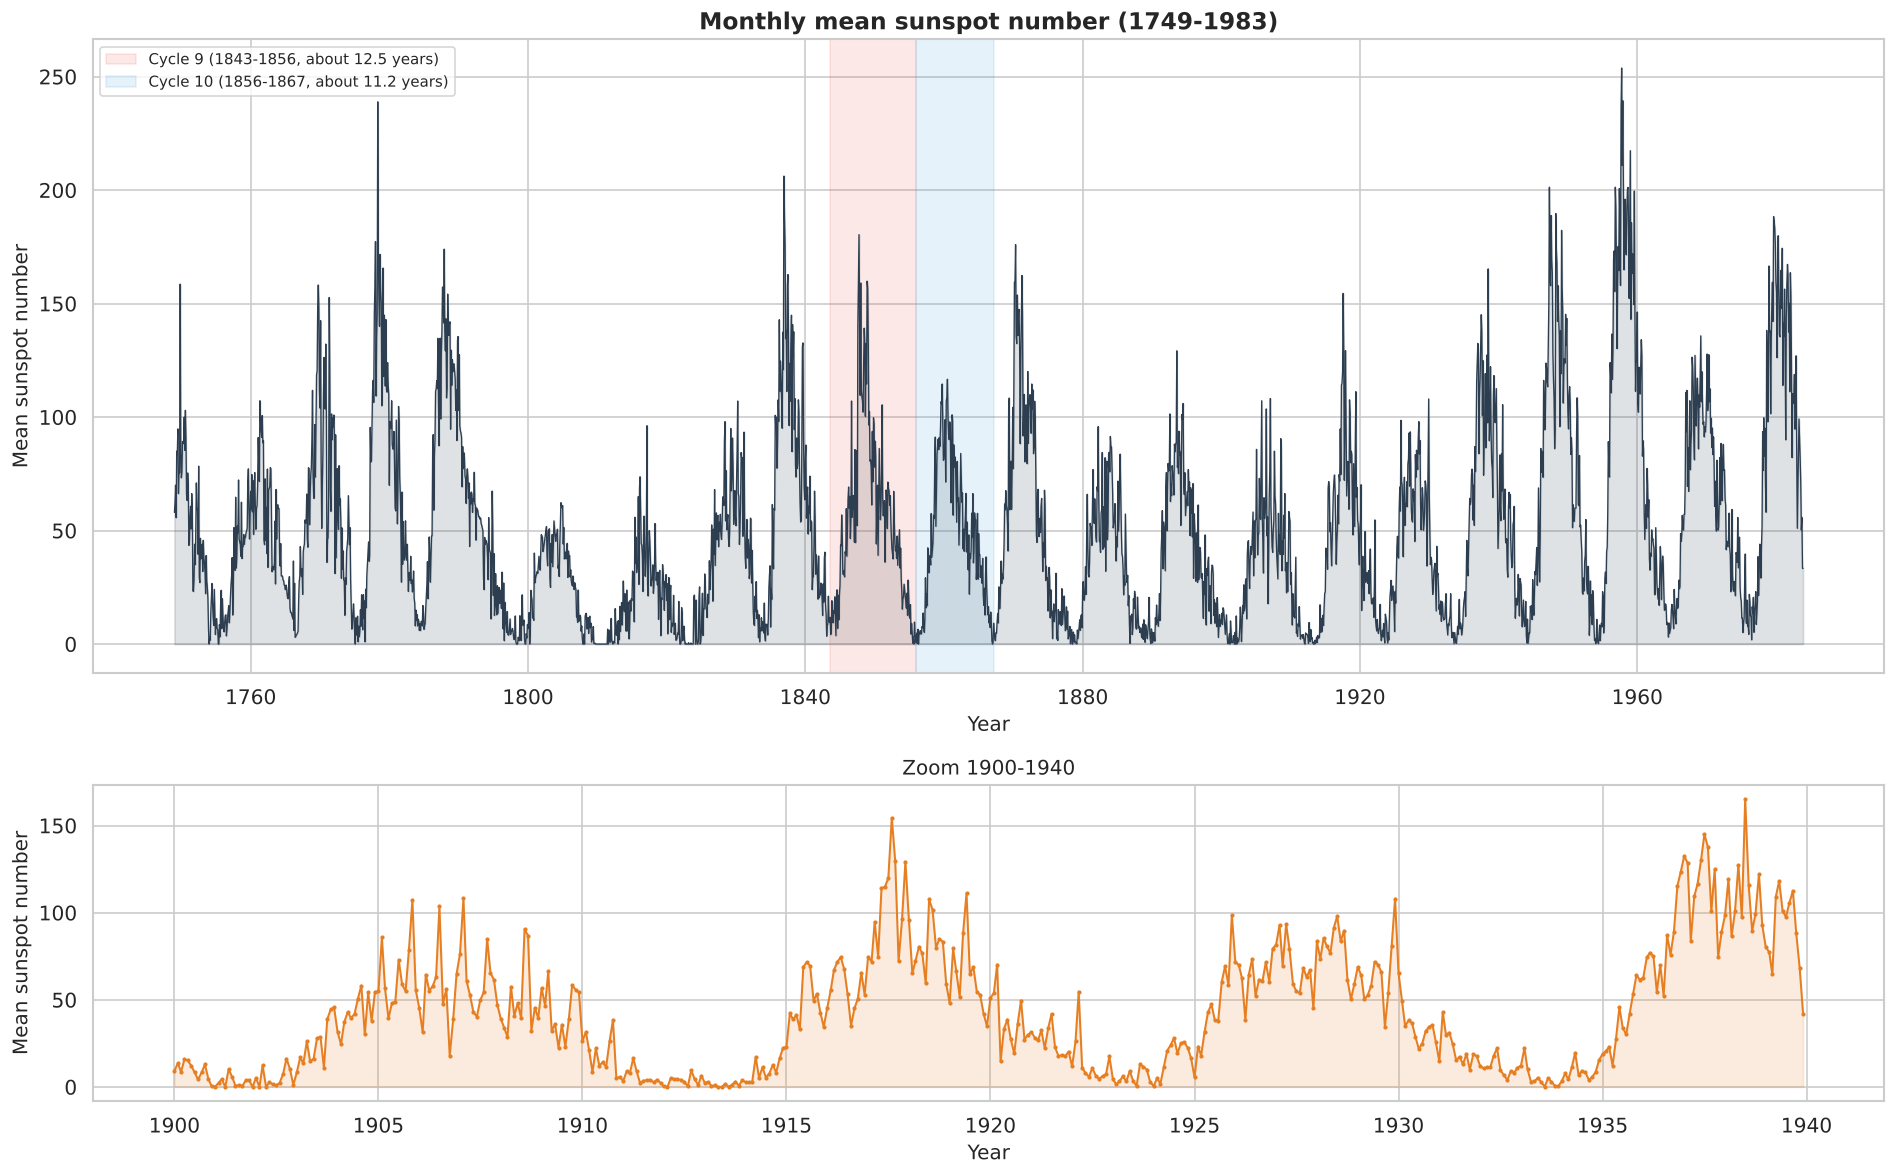

In [8]:
# The column of the values, used in all the analyses of this section
sunspots = df['Sunspots']

# Summary statistics: count, mean, standard deviation, quartiles, plus skewness and kurtosis
summary = sunspots.describe()
summary['skewness'] = sunspots.skew()     # > 0: long tail towards high values
summary['kurtosis'] = sunspots.kurtosis()
print(summary.round(2).to_string())

# Figure 1: whole series on top, 40-year zoom below
fig, axes = plt.subplots(2, 1, figsize=(16, 10), gridspec_kw={'height_ratios': [2, 1]})

# Top: whole series, with two consecutive cycles highlighted (from minimum to minimum)
ax = axes[0]
ax.plot(sunspots.index, sunspots, color=MODEL_COLORS['Ground Truth'], linewidth=0.8)
ax.fill_between(sunspots.index, sunspots, alpha=0.15, color=MODEL_COLORS['Ground Truth'])
ax.axvspan(pd.Timestamp('1843-07-01'), pd.Timestamp('1856-01-01'), alpha=0.12,
           color='#e74c3c', label='Cycle 9 (1843-1856, about 12.5 years)')
ax.axvspan(pd.Timestamp('1856-01-01'), pd.Timestamp('1867-03-01'), alpha=0.12,
           color='#3498db', label='Cycle 10 (1856-1867, about 11.2 years)')
ax.set_title('Monthly mean sunspot number (1749-1983)', fontsize=14, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Mean sunspot number')
ax.legend(loc='upper left', fontsize=9)

# Bottom: zoom on 1900-1939, about three and a half cycles, with every month as a dot
zoom = sunspots['1900':'1939']
axes[1].plot(zoom.index, zoom, color='#e67e22', linewidth=1.2, marker='o', markersize=1.5)
axes[1].fill_between(zoom.index, zoom, alpha=0.15, color='#e67e22')
axes[1].set_title('Zoom 1900-1940', fontsize=12)
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Mean sunspot number')

plt.tight_layout()
plt.show()

- Mean **51.3**, range **0-253.8**, skewness **1.10**: many low months and few very high ones.
- Cycle of about **11 years** with a variable length (the two highlighted cycles last 12.5 and 11.2 years) and a variable height; the highest value is in the late 1950s, close to the end of the series.
- Each cycle rises faster than it decays (zoom: minimum in 1913, maximum in 1917, minimum in 1923), and the values jump considerably from one month to the next.

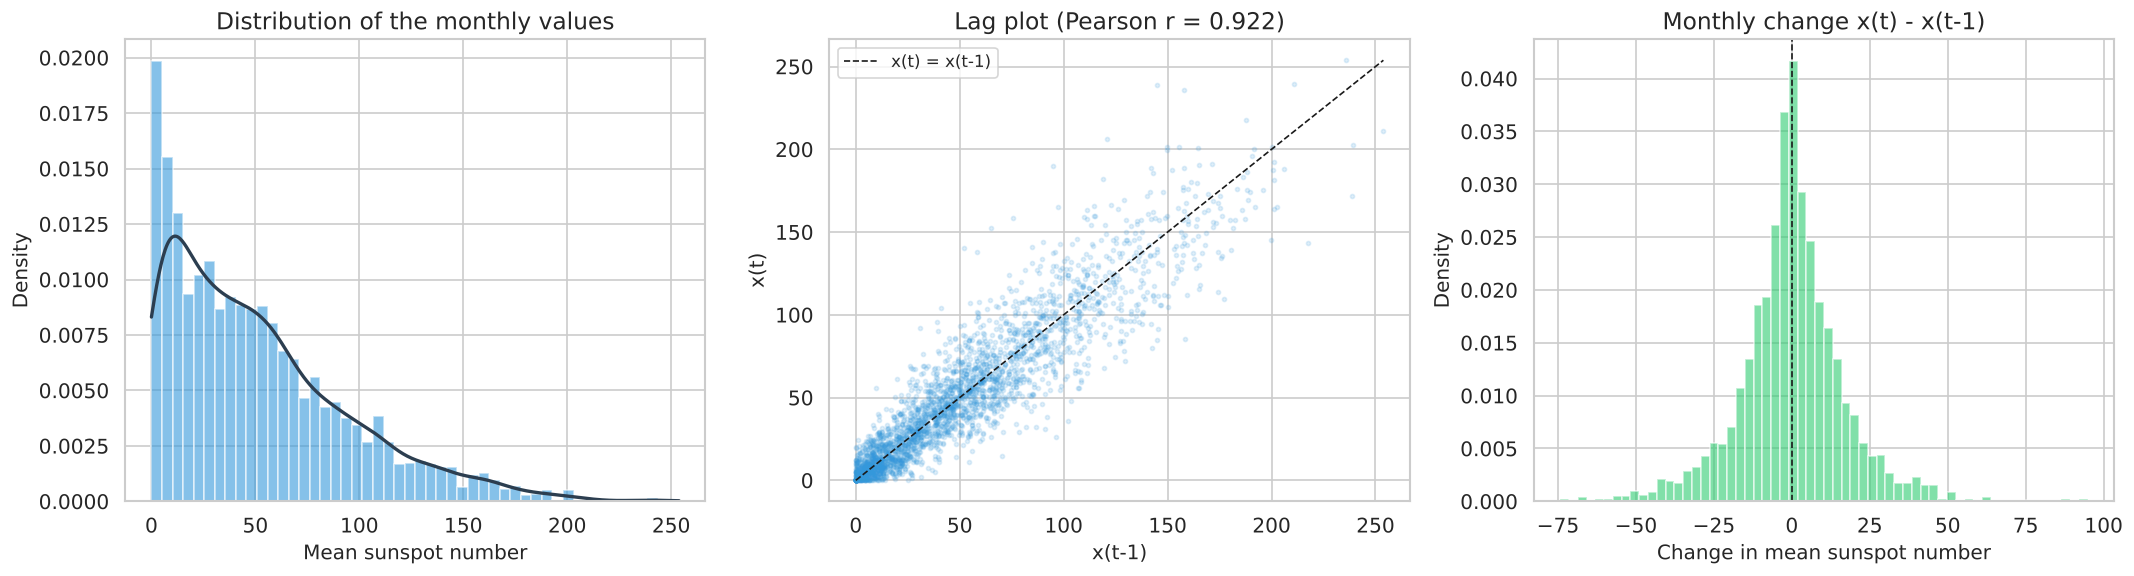

Correlation between consecutive months: 0.922
Monthly change, mean: -0.01, std: 17.2
Std of the change when the previous month is below 50: 11.1
Std of the change when the previous month is 100 or more: 26.3
Share of months with a value below 10: 17.6%


In [9]:
prev = sunspots.shift(1).dropna()      # value of the previous month, x(t-1)
curr = sunspots.loc[prev.index]        # value of the current month, x(t)
change = sunspots.diff().dropna()      # monthly change, x(t) - x(t-1)
r_lag1 = prev.corr(curr)               # Pearson correlation between consecutive months

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Left: distribution of the values. The density curve (KDE) is drawn only between 0 and the
# maximum, because a sunspot number cannot be negative
axes[0].hist(sunspots, bins=50, density=True, alpha=0.6,
             color=MODEL_COLORS['SimpleRNN'], edgecolor='white')
sunspots.plot.kde(ax=axes[0], ind=np.linspace(0, sunspots.max(), 500),
                  color=MODEL_COLORS['Ground Truth'], linewidth=2)
axes[0].set_title('Distribution of the monthly values')
axes[0].set_xlabel('Mean sunspot number')
axes[0].set_ylabel('Density')

# Centre: lag plot. If each month were equal to the previous one, all the points would lie on
# the dashed line x(t) = x(t-1)
axes[1].scatter(prev, curr, s=6, alpha=0.15, color=MODEL_COLORS['SimpleRNN'])
axes[1].plot([0, sunspots.max()], [0, sunspots.max()], 'k--', linewidth=1, label='x(t) = x(t-1)')
axes[1].set_title(f'Lag plot (Pearson r = {r_lag1:.3f})')
axes[1].set_xlabel('x(t-1)')
axes[1].set_ylabel('x(t)')
axes[1].legend(loc='upper left')

# Right: distribution of the monthly changes, with a line at zero
axes[2].hist(change, bins=60, density=True, alpha=0.6,
             color=MODEL_COLORS['LSTM'], edgecolor='white')
axes[2].axvline(0, color='k', linestyle='--', linewidth=1)
axes[2].set_title('Monthly change x(t) - x(t-1)')
axes[2].set_xlabel('Change in mean sunspot number')
axes[2].set_ylabel('Density')

plt.tight_layout()
plt.show()

# Numbers behind the three panels
print(f'Correlation between consecutive months: {r_lag1:.3f}')
print(f'Monthly change, mean: {change.mean():.2f}, std: {change.std():.1f}')
# Size of the changes when the previous month is low or high
print(f'Std of the change when the previous month is below 50: {change[prev < 50].std():.1f}')
print(f'Std of the change when the previous month is 100 or more: {change[prev >= 100].std():.1f}')
print(f'Share of months with a value below 10: {(sunspots < 10).mean():.1%}')

- **17.6%** of the months are below 10: the distribution is skewed.
- Consecutive months are strongly correlated (**r = 0.92**): in the lag plot the points stay close to the line x(t) = x(t-1).
- The monthly changes have mean -0.01 and standard deviation **17.2**, much smaller than that of the values (43.4): a model can predict the change instead of the value.
- The changes grow with the level: standard deviation **26.3** above 100 and **11.1** below 50, so most of the errors are expected at the peaks.

Mean:        RMSE = 43.4, MAE = 34.5
Persistence: RMSE = 17.2, MAE = 12.0
RMSE reduction of persistence compared to the mean: 60%


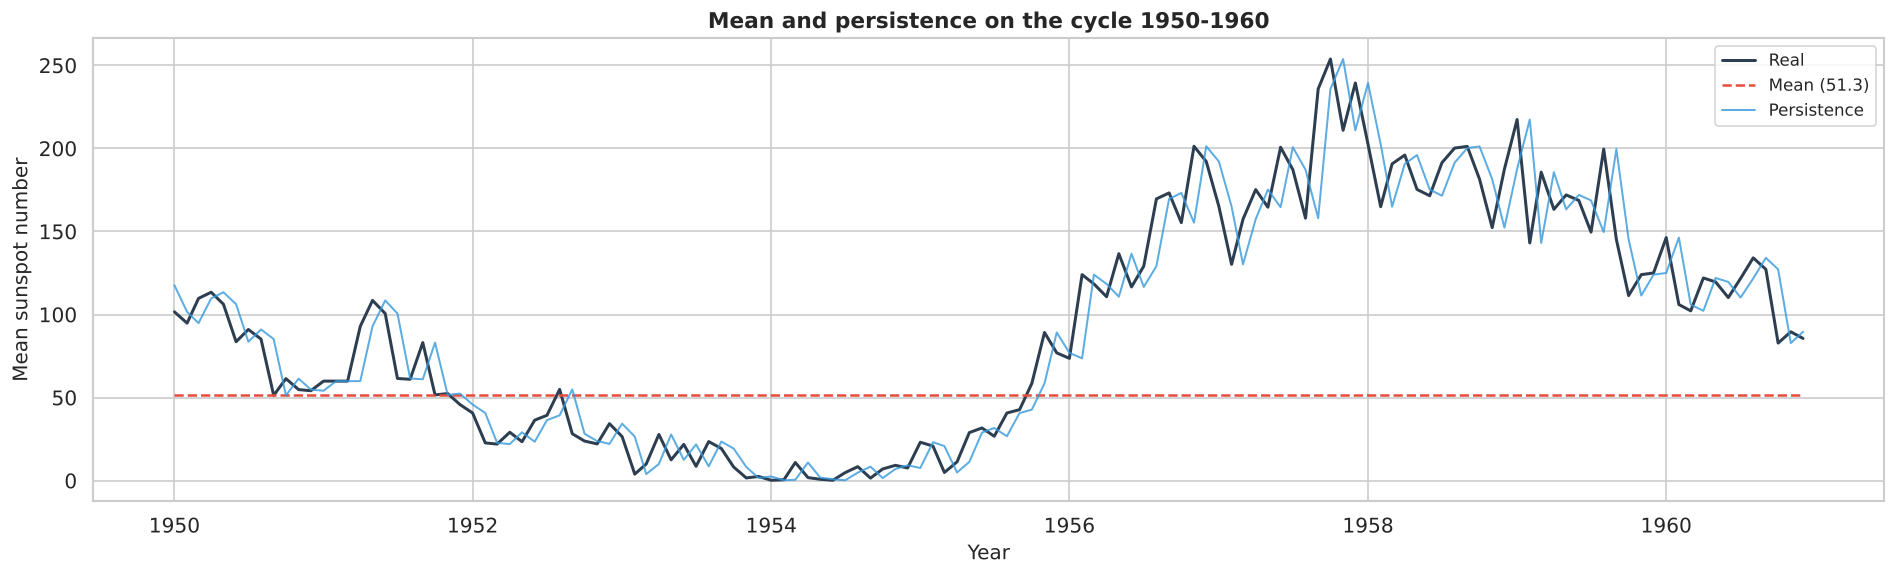

In [10]:
# Both predictors are evaluated on the same months (from the second one, which has a previous month)
target = sunspots.iloc[1:]
pred_mean = pd.Series(sunspots.mean(), index=target.index)   # always the mean of the series
pred_persistence = sunspots.shift(1).iloc[1:]                # the value of the previous month

# Errors of the two predictors
rmse_mean = np.sqrt(((target - pred_mean) ** 2).mean())
rmse_persistence = np.sqrt(((target - pred_persistence) ** 2).mean())
mae_mean = (target - pred_mean).abs().mean()
mae_persistence = (target - pred_persistence).abs().mean()

print(f'Mean:        RMSE = {rmse_mean:.1f}, MAE = {mae_mean:.1f}')
print(f'Persistence: RMSE = {rmse_persistence:.1f}, MAE = {mae_persistence:.1f}')
print(f'RMSE reduction of persistence compared to the mean: {1 - rmse_persistence / rmse_mean:.0%}')

# The two predictors on the strongest cycle of the series (ZOOM_PERIOD, set in the setup)
period = slice(*ZOOM_PERIOD)
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(target[period], color=MODEL_COLORS['Ground Truth'], linewidth=1.8, label='Real')
ax.plot(pred_mean[period], color=MODEL_COLORS['Dense'], linestyle='--', linewidth=1.5,
        label=f'Mean ({sunspots.mean():.1f})')
ax.plot(pred_persistence[period], color=MODEL_COLORS['SimpleRNN'], linewidth=1.2, alpha=0.8,
        label='Persistence')
ax.set_title(f'Mean and persistence on the cycle {ZOOM_PERIOD[0]}-{ZOOM_PERIOD[1]}', fontsize=13, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Mean sunspot number')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

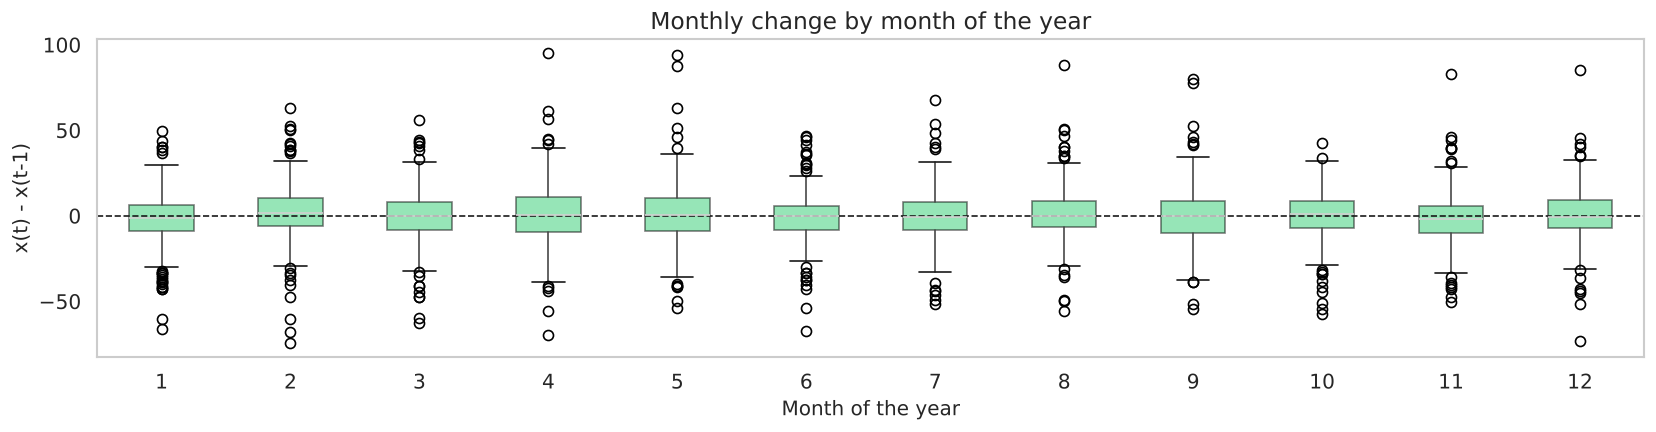

Lag 1: RMSE = 17.1
Lag 11: RMSE = 30.2
Lag 12: RMSE = 31.6
Lag 13: RMSE = 33.0


In [11]:
# Monthly changes with the month of the year (1 = January, ..., 12 = December)
by_month = pd.DataFrame({'change': change, 'month': change.index.month})

# One box for every month of the year
fig, ax = plt.subplots(figsize=(14, 4))
by_month.boxplot(column='change', by='month', ax=ax, grid=False, patch_artist=True,
                 boxprops=dict(facecolor=MODEL_COLORS['LSTM'], alpha=0.5))
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.set_title('Monthly change by month of the year')
ax.set_xlabel('Month of the year')
ax.set_ylabel('x(t) - x(t-1)')
fig.suptitle('')   # pandas adds an extra title by default
plt.tight_layout()
plt.show()

# Error when we copy the value of k months ago, computed on the same months for every k
target_lags = sunspots.iloc[13:]
for k in [1, 11, 12, 13]:
    rmse = np.sqrt(((target_lags - sunspots.shift(k).iloc[13:]) ** 2).mean())
    print(f'Lag {k}: RMSE = {rmse:.1f}')

- All the months of the year have changes centred around zero.
- Copying the value of 12 months ago (RMSE **31.6**) is not better than copying 11 or 13 months ago (30.2 and 33.0): the error simply grows with the distance, with no dip at lag 12, so there is **no annual seasonality**.

#### Summary of 1.2
| Finding | Consequence for the models |
| :--- | :--- |
| Each month is very close to the previous one | persistence is the baseline to beat |
| The monthly changes are small and centred on zero | also try models that predict the change |
| The changes grow with the level | errors expected at the peaks; the forecast plots zoom on them |
| Skewed distribution | the MAE is reported together with the RMSE |
| Cycle of about 11 years with a variable length | guides the choice of the input window |
| No annual seasonality | the models only receive the past values of the series |
| The strongest cycles are at the end of the series | the test set will be harder than the validation set |

### 1.3 Outliers

Extreme values can be measurement errors, to be removed, or real values, to be kept.

In this section we:
- check that there are no impossible values (negative sunspot numbers);
- find the outliers with the rule of the boxplot, above Q3 + 1.5 (Q3 - Q1), where Q1 and Q3 are the first and third quartiles, and show where they are in time;
- check whether the outliers and the months equal to 0 are isolated values or part of longer periods;
- decide whether to keep them.

Negative values: 0
Missing values: 0

Q1 = 15.7, Q3 = 74.9, upper limit = 163.8
Outliers: 59 months (2.1%)
Years with outliers: [1778, 1779, 1787, 1836, 1837, 1847, 1870, 1938, 1947, 1948, 1949, 1956, 1957, 1958, 1959, 1979, 1980, 1981]


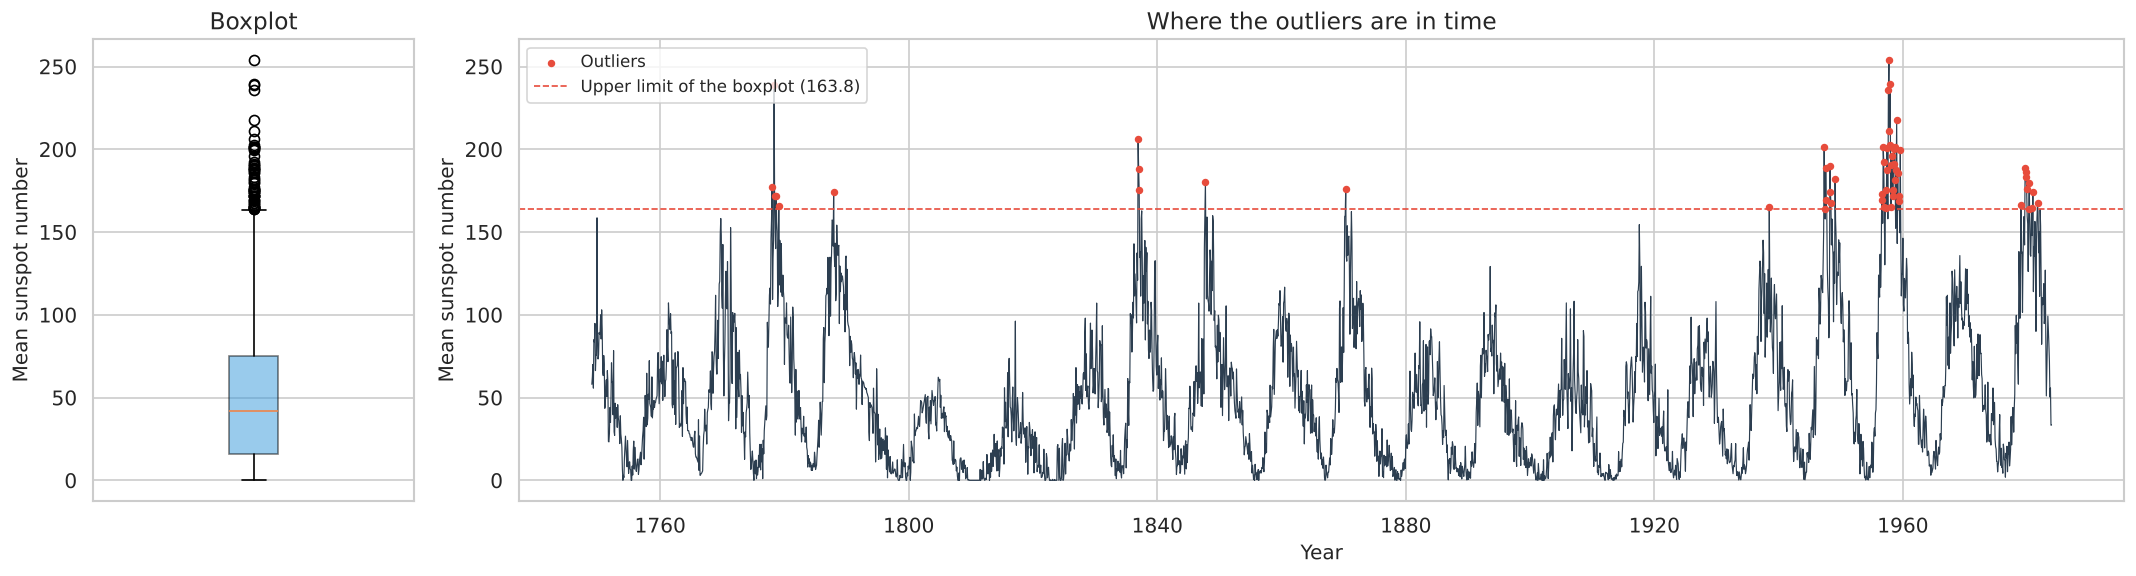

In [12]:
# Impossible values: a sunspot number cannot be negative
print(f'Negative values: {(sunspots < 0).sum()}')
print(f'Missing values: {sunspots.isnull().sum()}')

# Outliers as the boxplot defines them: values above Q3 + 1.5 * (Q3 - Q1)
q1, q3 = sunspots.quantile([0.25, 0.75])
upper_limit = q3 + 1.5 * (q3 - q1)
outliers = sunspots[sunspots > upper_limit]
print(f'\nQ1 = {q1:.1f}, Q3 = {q3:.1f}, upper limit = {upper_limit:.1f}')
print(f'Outliers: {len(outliers)} months ({len(outliers) / len(sunspots):.1%})')
print(f'Years with outliers: {list(outliers.index.year.unique())}')

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 5]})

# Left: boxplot of all the values (the circles are the outliers)
axes[0].boxplot(sunspots, patch_artist=True,
                boxprops=dict(facecolor=MODEL_COLORS['SimpleRNN'], alpha=0.5))
axes[0].set_title('Boxplot')
axes[0].set_ylabel('Mean sunspot number')
axes[0].set_xticks([])

# Right: the series with the outliers in red and the upper limit of the boxplot
axes[1].plot(sunspots, color=MODEL_COLORS['Ground Truth'], linewidth=0.7)
axes[1].scatter(outliers.index, outliers, color='#e74c3c', s=12, zorder=3, label='Outliers')
axes[1].axhline(upper_limit, color='#e74c3c', linestyle='--', linewidth=1,
                label=f'Upper limit of the boxplot ({upper_limit:.1f})')
axes[1].set_title('Where the outliers are in time')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Mean sunspot number')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

- No negative and no missing values.
- Q1 = 15.7 and Q3 = 74.9, so the upper limit of the boxplot is **163.8**: **59 months (2.1%)** are above it.
- They are concentrated in a few groups of years (for example 1778, 1837 and 1956-1959), each at the maximum of one of the strongest cycles.

In [13]:
# Value of the month before and of the month after every outlier
before = sunspots.shift(1)[outliers.index]
after = sunspots.shift(-1)[outliers.index]
# Share of outliers whose two neighbours are both high months (above Q3)
both_high = ((before > q3) & (after > q3)).mean()
print(f'Outliers with the previous and the next month both above Q3 ({q3:.1f}): {both_high:.0%}')
print(f'Average value of the previous and next months: {before.mean():.1f} and {after.mean():.1f}')

# Same check for the months equal to 0: their neighbours should be low months (below Q1)
zeros = sunspots[sunspots == 0]
before_zero = sunspots.shift(1)[zeros.index]
after_zero = sunspots.shift(-1)[zeros.index]
both_low = ((before_zero < q1) & (after_zero < q1)).mean()
print(f'\nMonths equal to 0: {len(zeros)}')
print(f'Zeros with the previous and the next month both below Q1 ({q1:.1f}): {both_low:.0%}')

Outliers with the previous and the next month both above Q3 (74.9): 100%
Average value of the previous and next months: 169.9 and 167.5

Months equal to 0: 67
Zeros with the previous and the next month both below Q1 (15.7): 96%


- A measurement error would be a single extreme month with normal months around it. Instead, every outlier has both neighbours above Q3 (about 170 on average): the outliers are the highest months of strong cycles.
- The 67 months equal to 0 could be missing values written as 0, but 96% of them are surrounded by months below Q1: they belong to long solar minima.

#### Summary of 1.3
Outliers and zeros are real values and are **kept**:
1. they are exactly the values to predict, and removing or clipping them would make the problem look easier than it is;
2. removing rows would leave holes in the series, so the windows would contain months that are not consecutive;
3. their only effect is on the evaluation: the RMSE is more sensitive to large errors than the MAE, so both are reported.

Their distribution over training, validation and test is checked after the split.

### 1.4 Correlation with past months & lookback window

The models predict the next months from a window of past months, and its length (`LOOKBACK`) has to be chosen. A common way to see which features are useful before training is their correlation with the target; in a time series the features are the past months.

In this section we:
- compute the Pearson correlation between x(t) and x(t-k) for every lag k from 1 to 300 months (25 years), the autocorrelation;
- find the key points of the curve and check what a correlation below 0.5 means for a prediction;
- choose the candidates for `LOOKBACK`.

Correlation at lag 1, 12, 24: 0.92, 0.74, 0.39
First lag with correlation below 0.5: 21 months
First lag with correlation below 0: 37 months
Minimum: -0.39 at 63 months
Maximum after the minimum: 0.58 at 125 months

RMSE of the mean: 43.4
RMSE when copying the value of 21 months ago: 44.2


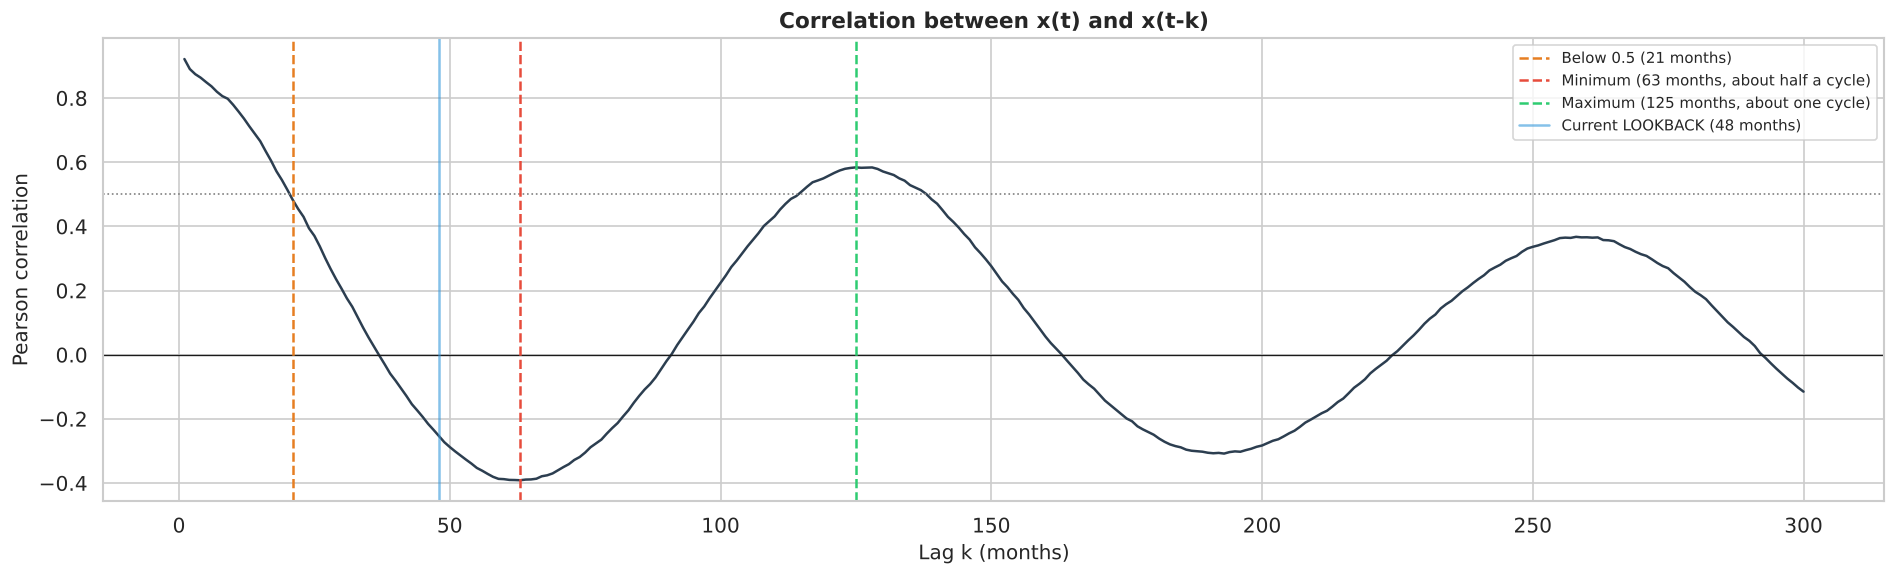

In [14]:
# Pearson correlation between x(t) and x(t-k) for every lag k from 1 to 300 months
max_lag = 300
lags = np.arange(1, max_lag + 1)
corr_by_lag = pd.Series([sunspots.corr(sunspots.shift(k)) for k in lags], index=lags)

# Key points of the curve
first_below_half = corr_by_lag[corr_by_lag < 0.5].index[0]   # correlation drops below 0.5
first_below_zero = corr_by_lag[corr_by_lag < 0].index[0]     # correlation becomes negative
lag_min = corr_by_lag.idxmin()                               # lowest correlation (about half a cycle)
lag_max = corr_by_lag.loc[lag_min:].idxmax()                 # highest correlation after the minimum (one cycle)

print(f'Correlation at lag 1, 12, 24: {corr_by_lag[1]:.2f}, {corr_by_lag[12]:.2f}, {corr_by_lag[24]:.2f}')
print(f'First lag with correlation below 0.5: {first_below_half} months')
print(f'First lag with correlation below 0: {first_below_zero} months')
print(f'Minimum: {corr_by_lag[lag_min]:.2f} at {lag_min} months')
print(f'Maximum after the minimum: {corr_by_lag[lag_max]:.2f} at {lag_max} months')

# Below 0.5, copying the value of k months ago is about as bad as predicting the mean
rmse_mean = np.sqrt(((sunspots - sunspots.mean()) ** 2).mean())
rmse_copy = np.sqrt(((sunspots - sunspots.shift(first_below_half)) ** 2).mean())
print(f'\nRMSE of the mean: {rmse_mean:.1f}')
print(f'RMSE when copying the value of {first_below_half} months ago: {rmse_copy:.1f}')

# Correlation as a function of the lag, with the key points and the current LOOKBACK
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(corr_by_lag, color=MODEL_COLORS['Ground Truth'], linewidth=1.5)
ax.axhline(0, color='k', linewidth=0.8)
ax.axhline(0.5, color='grey', linestyle=':', linewidth=1)
ax.axvline(first_below_half, color='#e67e22', linestyle='--', label=f'Below 0.5 ({first_below_half} months)')
ax.axvline(lag_min, color='#e74c3c', linestyle='--', label=f'Minimum ({lag_min} months, about half a cycle)')
ax.axvline(lag_max, color='#2ecc71', linestyle='--', label=f'Maximum ({lag_max} months, about one cycle)')
ax.axvline(LOOKBACK, color=MODEL_COLORS['SimpleRNN'], linestyle='-', alpha=0.6,
           label=f'Current LOOKBACK ({LOOKBACK} months)')
ax.set_title('Correlation between x(t) and x(t-k)', fontsize=13, fontweight='bold')
ax.set_xlabel('Lag k (months)')
ax.set_ylabel('Pearson correlation')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

#### Summary of 1.4
Key points of the autocorrelation:

| Lag | Correlation | Meaning |
| :---: | :---: | :--- |
| 1 month | 0.92 | the previous month is the best single predictor |
| 21 months | below 0.5 | copying it (RMSE 44.2) is no better than the mean (43.4) |
| 37 months | below 0 | about a quarter of a cycle |
| 63 months | -0.39 (minimum) | half a cycle: a maximum is followed by a minimum and the other way round |
| 125 months | 0.58 | one full cycle, about 10.4 years |

Candidates for `LOOKBACK`:
- **24 months**: only the strongly correlated months; with a window that is too short the model tends to copy the last value;
- **48 months** (default) and **63 months** (half a cycle): the window contains a whole rise or a whole decay, so the model can recognise the phase of the cycle;
- **125 months** (one cycle): the most information, but long sequences are harder to learn for a Simple RNN, and the Dense network would have 125 inputs.

The correlation looks at each lag on its own, not at how many months a model needs together: inside a window the recent months repeat almost the same information, while the older ones add the phase of the cycle. The final value is therefore chosen on the validation set, in the hyperparameter selection. Until then `LOOKBACK` = 48.

---
## 2. Temporal Windowing (Sliding Window) & Dataset Partitioning

In this section we turn the series into examples for the networks: windows of past months, each with the months that follow it as target. The series is split in time into training, validation and test, scaled to [0, 1], and the training windows are grouped in mini-batches.

### 2.1 Sliding windows

A network learns from pairs (input, target), so the series is cut into overlapping **sliding windows** that move forward one month at a time.

| Symbol | Meaning | Values used |
| :---: | :--- | :--- |
| L (`LOOKBACK`) | months in each input | 24, 48, 63, 125 |
| H (`horizon`) | months to predict after the input | 1 or 6 |
| N = T - L - H + 1 | number of windows from a series of T months | e.g. 2820 - 48 - 1 + 1 = 2772 |

Example with the values 0, 1, ..., 9, L = 3 and H = 2, which gives 10 - 3 - 2 + 1 = 6 windows:

| Window | Input | Target |
| :---: | :---: | :---: |
| 1 | 0, 1, 2 | 3, 4 |
| 2 | 1, 2, 3 | 4, 5 |
| ... | ... | ... |
| 6 | 5, 6, 7 | 8, 9 |

`make_windows` returns:
- `X`, shape (N, L, 1) = (windows, time steps, features): the format read by the recurrent layers with `batch_first=True`;
- `y`, shape (N, H): the targets;
- `first_target`: the position of the first target of each window, used to split the windows in time and to put dates on the predictions.

In [15]:
def make_windows(series, lookback, horizon=1):
    """
    Turns a 1D series into input windows and targets.
      X[i] = series[i : i + lookback]                         -> shape (lookback, 1)
      y[i] = series[i + lookback : i + lookback + horizon]    -> shape (horizon,)
    It also returns the index of the first target of each window, used to split the
    windows in time and to put dates on the plots.
    """
    # Number of windows that fit in the series: each needs lookback inputs and horizon targets
    n_windows = len(series) - lookback - horizon + 1

    # Window i starts at position i: inputs first, then the targets right after them
    X = np.array([series[i:i + lookback] for i in range(n_windows)])
    y = np.array([series[i + lookback:i + lookback + horizon] for i in range(n_windows)])

    # Position in the series of the first target of each window
    first_target = np.arange(n_windows) + lookback

    # Inputs as (windows, time steps, features = 1), the shape expected by the recurrent layers
    return X.reshape(-1, lookback, 1).astype(np.float32), y.astype(np.float32), first_target

### 2.2 Split in time & scaling

The series is split **in time**, because in forecasting the unseen data are the future:

| Period | Share | Months | Use |
| :--- | :---: | :--- | :--- |
| Training | 70% | 1749-01 to 1913-06 (1974) | learn the weights and fit the scaler |
| Validation | 10% | 1913-07 to 1936-12 (282) | choose the settings, early stopping |
| Test | 20% | 1937-01 to 1983-12 (564) | final evaluation, used only once |

Training and validation together are 80% of the months. The boundaries are fixed on the **months**, not on the number of windows, so windows of any length and horizon are evaluated on exactly the same months.

The values are then scaled to [0, 1] with `MinMaxScaler`, x' = (x - min) / (max - min), where min and max are computed on the **training months only**: using later months would give the model information about the future (data leakage).

In this section we:
- fix the three periods;
- scale the series and check the range of the scaled values and the outliers of each period;
- check whether a square root or a logarithm before the scaling makes the series more regular.

In [16]:
# Values of the series as a NumPy array of real numbers
raw_values = df['Sunspots'].values.astype(np.float32)

# Boundaries fixed on the months, so they are the same for every LOOKBACK and every horizon
n_months = len(raw_values)
n_test = int(n_months * TEST_RATIO)
n_val = int(n_months * VAL_RATIO)
train_end = n_months - n_val - n_test   # first month of the validation period
val_end = n_months - n_test             # first month of the test period

# The three periods as ranges of positions in the series
periods = {
    'train': slice(0, train_end),
    'validation': slice(train_end, val_end),
    'test': slice(val_end, n_months),
}
for name, period in periods.items():
    months = df.index[period]
    print(f'{name}: {months[0]:%Y-%m} to {months[-1]:%Y-%m}, {len(months)} months ({len(months) / n_months:.0%})')

train: 1749-01 to 1913-06, 1974 months (70%)
validation: 1913-07 to 1936-12, 282 months (10%)
test: 1937-01 to 1983-12, 564 months (20%)


Scaler fitted on the training months: min = 0.0, max = 238.9

train: max scaled value = 1.00, outliers = 11
validation: max scaled value = 0.65, outliers = 0
test: max scaled value = 1.06, outliers = 48


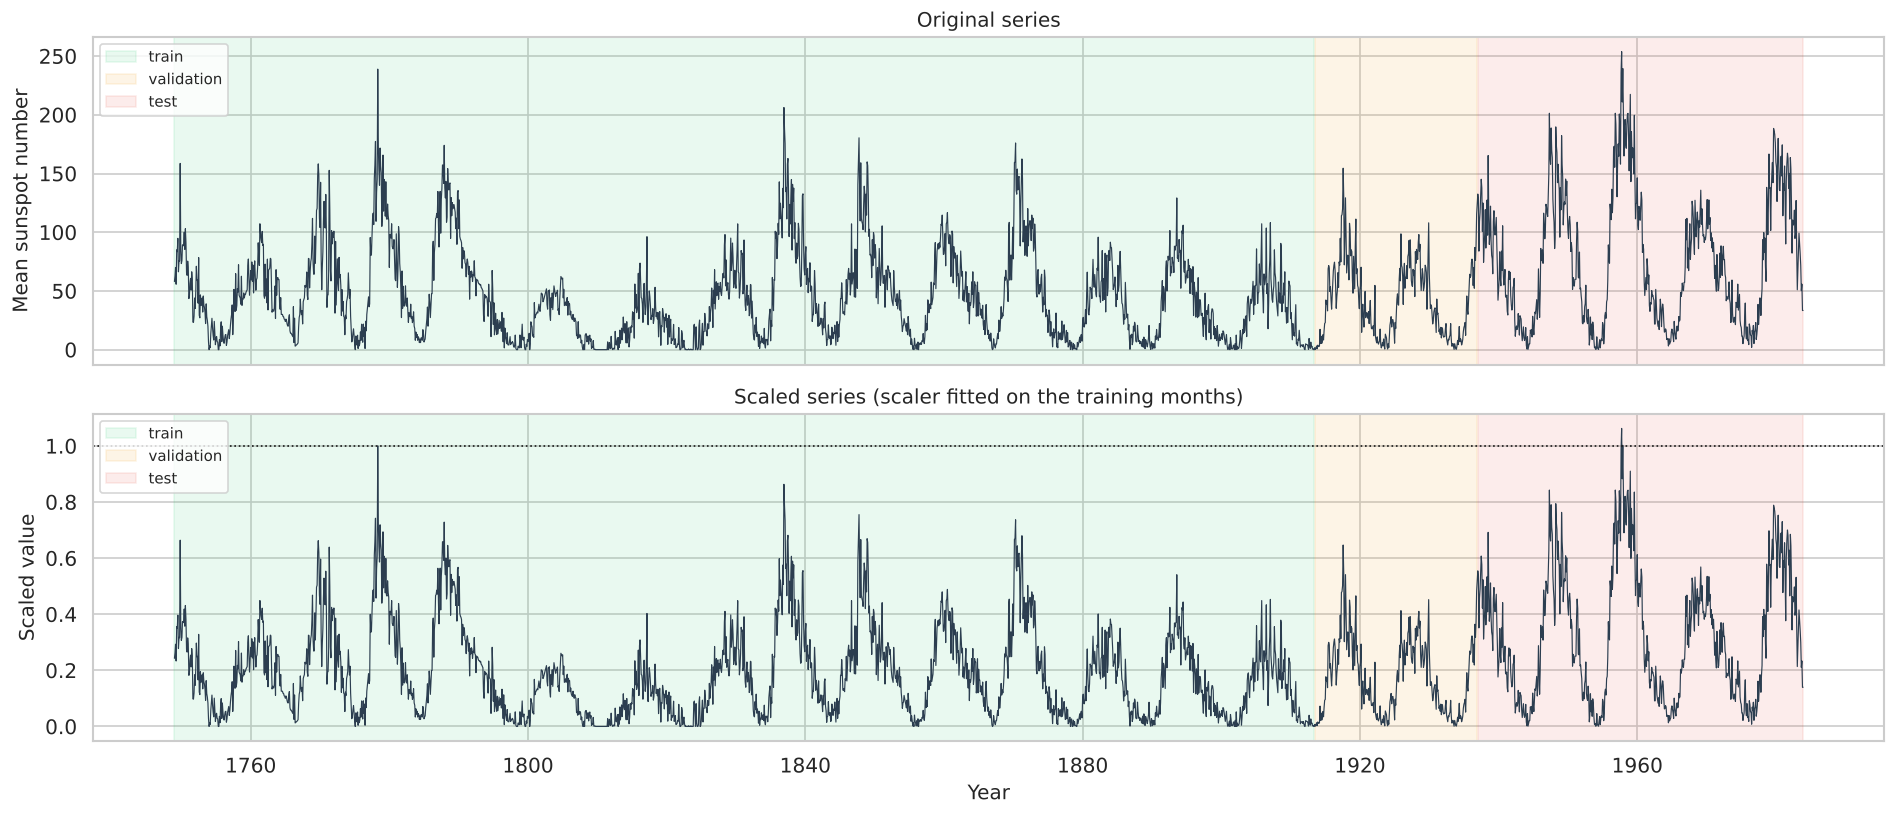

In [17]:
# The scaler learns the minimum and the maximum from the training months only:
# using validation or test would give the model information about the future (data leakage)
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(raw_values[:train_end].reshape(-1, 1))

# The same transformation is applied to the whole series
scaled_values = scaler.transform(raw_values.reshape(-1, 1)).flatten()
print(f'Scaler fitted on the training months: min = {scaler.data_min_[0]:.1f}, max = {scaler.data_max_[0]:.1f}\n')

# Maximum scaled value and number of outliers (upper limit of the boxplot) in each period
for name, period in periods.items():
    print(f'{name}: max scaled value = {scaled_values[period].max():.2f}, '
          f'outliers = {(raw_values[period] > upper_limit).sum()}')

# Original and scaled series with the three periods
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
colors = {'train': '#2ecc71', 'validation': '#f39c12', 'test': '#e74c3c'}
for ax, data, title in [(axes[0], raw_values, 'Original series'),
                        (axes[1], scaled_values, 'Scaled series (scaler fitted on the training months)')]:
    ax.plot(df.index, data, color=MODEL_COLORS['Ground Truth'], linewidth=0.7)
    for name, period in periods.items():
        months = df.index[period]
        ax.axvspan(months[0], months[-1], alpha=0.1, color=colors[name], label=name)
    ax.set_title(title, fontsize=12)
    ax.legend(loc='upper left', fontsize=9)
axes[0].set_ylabel('Mean sunspot number')
axes[1].axhline(1, color='k', linestyle=':', linewidth=1)    # maximum of the training months
axes[1].set_ylabel('Scaled value')
axes[1].set_xlabel('Year')
plt.tight_layout()
plt.show()

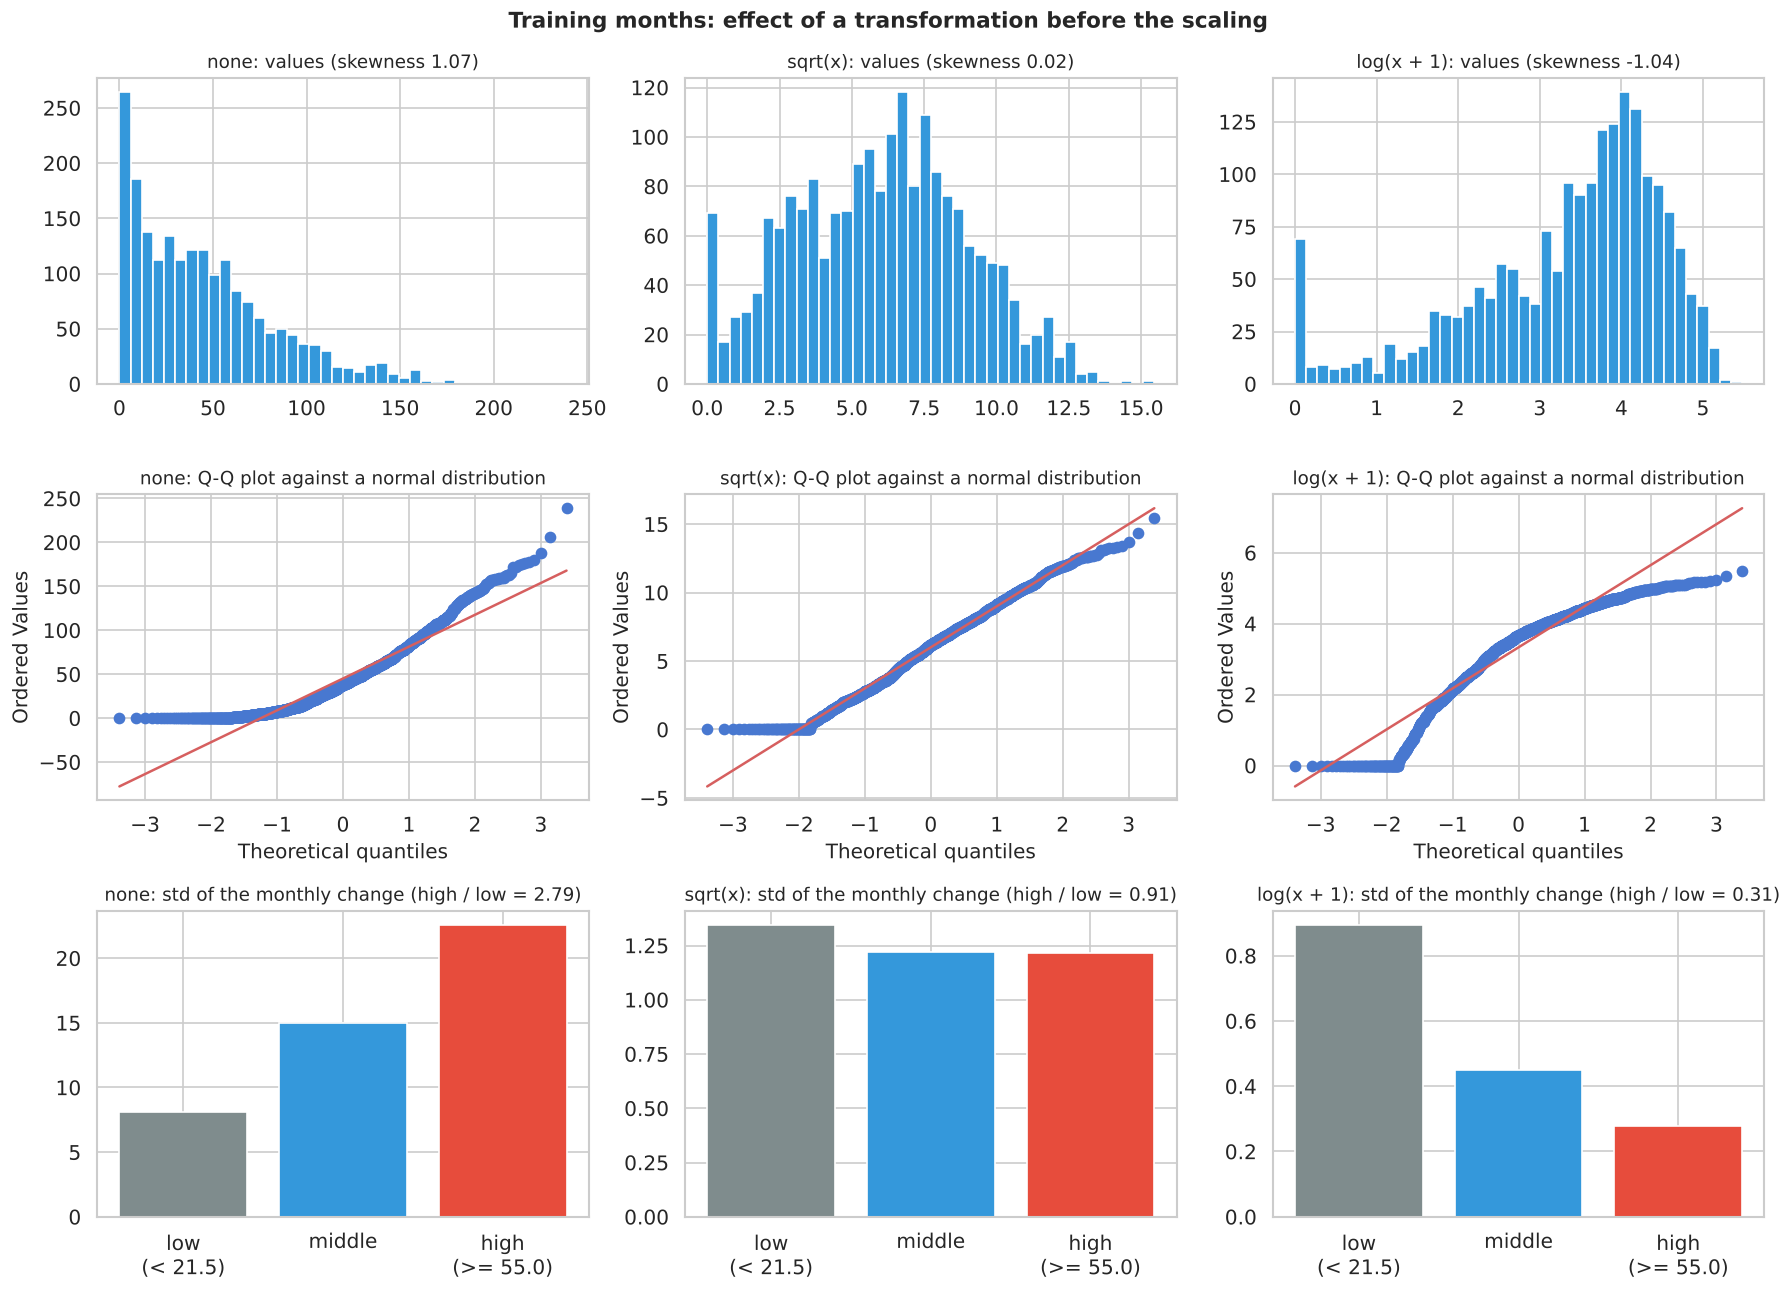

,skewness,"std of change, low months",middle,high,high / low
transformation,,,,,
none,1.07,8.09,14.97,22.55,2.79
sqrt(x),0.02,1.34,1.22,1.22,0.91
log(x + 1),-1.04,0.89,0.45,0.28,0.31


Months with value 0 in the training period: 67


In [18]:
# Square root and logarithm before the scaling, checked on the training months only
transforms = {'none': lambda x: x, 'sqrt(x)': np.sqrt, 'log(x + 1)': np.log1p}
train_values = raw_values[:train_end].astype(np.float64)
level = train_values[:-1]                                   # value of the month before each change
low_limit, high_limit = np.quantile(train_values, [1 / 3, 2 / 3])   # three levels with the same number of months

rows = []
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for col, (name, f) in enumerate(transforms.items()):
    values = f(train_values)
    change = np.diff(values)                                # monthly change on the transformed scale
    # Spread of the monthly change in low, middle and high months
    spread = [change[level < low_limit].std(),
              change[(level >= low_limit) & (level < high_limit)].std(),
              change[level >= high_limit].std()]
    rows.append({'transformation': name, 'skewness': stats.skew(values),
                 'std of change, low months': spread[0], 'middle': spread[1], 'high': spread[2],
                 'high / low': spread[2] / spread[0]})

    # Distribution of the values, Q-Q plot against a normal distribution, spread by level
    axes[0, col].hist(values, bins=40, color=MODEL_COLORS['SimpleRNN'])
    axes[0, col].set_title(f'{name}: values (skewness {stats.skew(values):.2f})', fontsize=11)
    stats.probplot(values, dist='norm', plot=axes[1, col])
    axes[1, col].set_title(f'{name}: Q-Q plot against a normal distribution', fontsize=11)
    axes[2, col].bar([f'low\n(< {low_limit:.1f})', 'middle', f'high\n(>= {high_limit:.1f})'], spread,
                     color=[MODEL_COLORS['Persistence'], MODEL_COLORS['SimpleRNN'], MODEL_COLORS['Dense']])
    axes[2, col].set_title(f'{name}: std of the monthly change (high / low = {spread[2] / spread[0]:.2f})', fontsize=11)
fig.suptitle('Training months: effect of a transformation before the scaling', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

display(pd.DataFrame(rows).set_index('transformation').round(2))
print(f'Months with value 0 in the training period: {(train_values == 0).sum()}')

Comparison on the training months:

| | none | square root | log(x + 1) |
| :--- | :---: | :---: | :---: |
| Skewness | 1.07 | **0.02** | -1.04 |
| Q-Q plot against a normal distribution | curved | **almost straight** | curved the other way |
| Std of the monthly change, high / low months | 2.79 | **0.91** | 0.31 |

- The **square root** makes the distribution almost symmetric and gives the monthly change the same spread at all levels, which is the problem seen in the EDA.
- The **logarithm** goes too far: it compresses the peaks and amplifies the noise of the months close to zero, partly because of the 67 months equal to 0.
- The square root is the only candidate. Whether it also improves the forecasts is tested on the validation set in the hyperparameter selection.

### 2.3 Windows for each split

Each window is assigned to the period that contains **all its targets**:
- with one target, the window belongs to the period of its target month;
- with six targets, the 5 windows at each boundary have targets in two periods and are **dropped**: otherwise the training would use validation months, or a test window would mix validation and test months;
- the inputs may start in the previous period, because they are past values, known at the time of the prediction.

In this section we:
- write `split_windows`, which assigns the windows to the three periods, and `make_dataset`, which builds the windows of the scaled series and splits them;
- build the default datasets with `LOOKBACK` = 48, one month (`data_1`) and six months ahead (`data_6`).

**Used later by:**
- `make_dataset`: every model trained with `run_experiment`, and the windows of the recursive forecasts;
- `split_windows`: the earlier validation periods of the chronological validation (`make_fold`);
- `data_1`: the baselines of the one-step forecast, on validation and test;
- `data_6`: the baselines of the six-step forecast and the common targets of all the six-step methods.

In [19]:
def split_windows(X, y, first_target, horizon, val_start=None, test_start=None):
    """
    Puts each window in the period that contains all its targets.
    The windows whose targets fall across a boundary are dropped.
    val_start and test_start move the boundaries, for the chronological validation;
    by default they are the boundaries fixed above.
    """
    val_start = train_end if val_start is None else val_start
    test_start = val_end if test_start is None else test_start

    # Position of the last target of each window
    last_target = first_target + horizon - 1

    # A window is kept in a period only if its first and last targets are both inside it
    masks = {
        'train': last_target < val_start,
        'validation': (first_target >= val_start) & (last_target < test_start),
        'test': first_target >= test_start,
    }
    return {name: (X[mask], y[mask], first_target[mask]) for name, mask in masks.items()}


def make_dataset(lookback, horizon):
    """Windows of the scaled series, already split in train, validation and test."""
    X, y, first_target = make_windows(scaled_values, lookback, horizon)
    return split_windows(X, y, first_target, horizon)


# Default datasets, one month ahead and six months ahead
data_1 = make_dataset(LOOKBACK, horizon=1)
data_6 = make_dataset(LOOKBACK, horizon=FORECAST_HORIZON)

# Shapes of each split: (windows, time steps, 1) for the inputs, (windows, horizon) for the targets
for title, data in [('1-step', data_1), (f'{FORECAST_HORIZON}-step', data_6)]:
    print(f'{title} windows (LOOKBACK = {LOOKBACK}):')
    for name, (X, y, first_target) in data.items():
        print(f'  {name}: X {X.shape}, y {y.shape}, first target {df.index[first_target[0]]:%Y-%m}')

1-step windows (LOOKBACK = 48):
  train: X (1926, 48, 1), y (1926, 1), first target 1753-01
  validation: X (282, 48, 1), y (282, 1), first target 1913-07
  test: X (564, 48, 1), y (564, 1), first target 1937-01
6-step windows (LOOKBACK = 48):
  train: X (1921, 48, 1), y (1921, 6), first target 1753-01
  validation: X (277, 48, 1), y (277, 6), first target 1913-07
  test: X (559, 48, 1), y (559, 6), first target 1937-01


### 2.4 DataLoader

During training the windows are read in **mini-batches** of 64 (`BATCH_SIZE`): the weights are updated after each batch, and one pass over all the batches is an epoch. The order of the windows is shuffled at every epoch, so that consecutive batches do not always come from the same period of the series; this is allowed because the order in time is kept inside each window. Validation and test are small and are evaluated in a single pass, without batches.

In this section we write `make_loader`, which turns the training windows into shuffled mini-batches.

**Used later by:** `run_experiment`, every time a model is trained.

In [20]:
def make_loader(X, y, batch_size=BATCH_SIZE, shuffle=True):
    """Wraps the windows into a DataLoader that returns shuffled mini-batches."""
    dataset = TensorDataset(torch.as_tensor(X), torch.as_tensor(y))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


# Only the training sets need batches: validation and test are small and are evaluated in one pass.
# Number of batches per epoch of the two default training sets
for name, data in [('1 step', data_1), (f'{FORECAST_HORIZON} steps', data_6)]:
    print(f'Batches per epoch, {name}: {len(make_loader(data["train"][0], data["train"][1]))}')

Batches per epoch, 1 step: 31
Batches per epoch, 6 steps: 31


---
## 3. Shared Utilities

The forecasting sections train and evaluate many models in the same way. The models, the training, the metrics and the plots are written once here, so that every model is trained and evaluated under the same conditions and only the model changes in the comparisons.

### 3.1 Models

The two model classes of the notebook. Both read a window of shape (batch, L, 1) and return one value for each month to predict, shape (batch, H), so they are trained and evaluated with the same code. The theory of each model is given before its first use.

| Class | Structure | Parameters depend on L? |
| :--- | :--- | :---: |
| `DenseForecaster` | Flatten, Linear(L, hidden), ReLU, Dropout, Linear(hidden, H) | yes: one weight for every month and hidden unit |
| `RecurrentForecaster` | RNN / LSTM / GRU cell over the L months, last hidden state, Dropout, Linear(hidden, H) | no: the same weights at every month |

Two options are shared by both classes:
- `dropout`: switches off a random share of the hidden units during training, a regularisation against overfitting;
- `predict_delta`: the network predicts the change with respect to the last month instead of the value (explained with the Simple RNN).

In this section we:
- write the two classes, with a single recurrent class for the three cells, so that LSTM and GRU only change one argument;
- write `count_params`, which counts the trainable parameters.

In [21]:
# The three recurrent cells, chosen by name
RECURRENT_CELLS = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}


class DenseForecaster(nn.Module):
    """Dense network: the window is flattened and goes through one hidden layer with ReLU."""

    def __init__(self, lookback, hidden=HIDDEN_SIZE, horizon=1, dropout=DROPOUT, predict_delta=False):
        super().__init__()
        self.predict_delta = predict_delta
        self.net = nn.Sequential(
            nn.Flatten(),                  # (batch, lookback, 1) -> (batch, lookback): one input per month
            nn.Linear(lookback, hidden),   # one weight for every month of the window and every hidden unit
            nn.ReLU(),
            nn.Dropout(dropout),           # switches off some hidden units during training
            nn.Linear(hidden, horizon),    # one output for every month to predict
        )

    def forward(self, x):
        prediction = self.net(x)
        if self.predict_delta:
            prediction = x[:, -1, :] + prediction   # last month of the window + predicted change
        return prediction


class RecurrentForecaster(nn.Module):
    """
    Recurrent network for the three cells: the cell reads the window one month at a time,
    and a linear head maps its last hidden state to the next `horizon` values.
    """

    def __init__(self, cell='RNN', hidden=HIDDEN_SIZE, num_layers=NUM_LAYERS, horizon=1,
                 dropout=DROPOUT, predict_delta=False):
        super().__init__()
        self.predict_delta = predict_delta
        # The dropout argument of the recurrent layer only acts between stacked layers,
        # so with a single layer it is switched off and dropout is applied before the head instead
        self.rnn = RECURRENT_CELLS[cell](1, hidden, num_layers=num_layers, batch_first=True,
                                         dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, horizon)

    def forward(self, x):
        out, _ = self.rnn(x)                 # hidden state at every month: (batch, lookback, hidden)
        last_state = out[:, -1, :]           # state after the last month of the window
        prediction = self.head(self.dropout(last_state))
        if self.predict_delta:
            prediction = x[:, -1, :] + prediction   # last month of the window + predicted change
        return prediction


def count_params(model):
    """Number of trainable parameters of a model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

#### Summary of 3.1
- Every model has the same input and output format, so one training and evaluation code serves all of them.
- The Dense network weighs every position of the window independently; the recurrent network reads the months in order and summarises them in a state.

### 3.2 Training

All the models are trained with the same procedure:

| Element | Choice | Role |
| :--- | :--- | :--- |
| Loss | MSE, the mean of (y - ŷ)² | the error minimised during training |
| Optimizer | Adam, learning rate 0.001 | updates the weights from the gradient of the loss |
| Mini-batches | 64 windows, shuffled | one update per batch, one epoch per pass over the batches |
| Gradient clipping | maximum norm 1 | in a recurrent network the gradient goes back through all the months and can become very large; it is scaled down so that a single batch cannot destroy what has been learned |
| Early stopping | patience 20, best weights restored | stops when the validation error has not improved for 20 epochs |

Example of early stopping with a patience of 3 and validation errors 0.010, 0.008, **0.007**, 0.0072, 0.0071, 0.0075: the best epoch is the third, the training stops at epoch 6 and the weights of epoch 3 are kept.

In this section we write `train_one_epoch` (one pass over the batches), `evaluate_loss` (error on a whole set, without changing the weights) and `fit` (the epochs with early stopping; it returns the history of the errors).

In [22]:
# Mean squared error, the loss minimised during training
loss_fn = nn.MSELoss()


def train_one_epoch(model, loader, optimizer):
    """One pass over the training batches, with gradient clipping. Returns the mean training loss."""
    model.train()                                   # training mode: dropout active
    total_loss = 0.0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        optimizer.zero_grad()                       # gradients accumulate, so reset them for every batch
        loss = loss_fn(model(X_batch), y_batch)     # prediction and error on this batch
        loss.backward()                             # gradient of the error with respect to every weight
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)   # limit the norm of the gradient
        optimizer.step()                            # update the weights
        total_loss += loss.item() * len(X_batch)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate_loss(model, X, y):
    """MSE on a whole set in one pass, without updating the weights."""
    model.eval()                                    # evaluation mode: dropout off
    X, y = torch.as_tensor(X, device=DEVICE), torch.as_tensor(y, device=DEVICE)
    return loss_fn(model(X), y).item()


def fit(model, train_loader, X_val, y_val, epochs=MAX_EPOCHS, patience=PATIENCE, lr=LEARNING_RATE):
    """
    Trains with Adam and early stopping on the validation loss: the training stops after
    `patience` epochs without improvement and the weights of the best epoch are restored.
    Returns the training and validation loss of every epoch.
    """
    model.to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'loss': [], 'val_loss': []}
    best_val_loss, best_weights, wait = np.inf, None, 0

    for epoch in range(epochs):
        history['loss'].append(train_one_epoch(model, train_loader, optimizer))
        history['val_loss'].append(evaluate_loss(model, X_val, y_val))

        if history['val_loss'][-1] < best_val_loss:
            # New best epoch: keep a copy of its weights and reset the counter
            best_val_loss, best_weights, wait = history['val_loss'][-1], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:                    # no improvement for `patience` epochs: stop
                break

    model.load_state_dict(best_weights)             # back to the weights of the best epoch
    return history

#### Summary of 3.2
- Every model uses the same optimizer, loss, clipping and early stopping, so the differences in the results come from the models and not from the training.
- The validation set only decides when to stop; the test set is never used during training.

### 3.3 Predictions, metrics & baselines

The models work on scaled values, but all the metrics are computed **after bringing the predictions back to sunspots**.

| Metric | Definition | Example: errors 5, -10, 20 | Use |
| :--- | :--- | :--- | :--- |
| MSE | mean of the squared errors | (25 + 100 + 400) / 3 = 175 | the training loss |
| RMSE | square root of the MSE | √175 ≈ 13.2 | main metric, in sunspots, sensitive to large errors |
| MAE | mean of the absolute errors | (5 + 10 + 20) / 3 ≈ 11.7 | average error, less sensitive to large ones |

For the six-step forecasts the RMSE is also computed for each step, to see how the error grows with the horizon.

Baselines, which need no training:
- **Persistence**: repeats the last month of the window for every step (last month 80: forecast 80, 80, 80, 80, 80, 80);
- **Mean**: always predicts the mean of the training months.

In this section we write `predict`, `to_sunspots` (the inverse of the scaling), `evaluate` (the metrics) and the two baselines.

In [23]:
@torch.no_grad()
def predict(model, X):
    """Predictions of a model as a NumPy array, in evaluation mode (dropout off)."""
    model.eval()
    return model(torch.as_tensor(X, device=DEVICE)).cpu().numpy()


def to_sunspots(y_scaled, fitted_scaler=None):
    """
    Back to sunspot units; works for (N, 1) and (N, horizon) arrays.
    By default it uses the scaler of the main split; the folds of the chronological validation pass their own scaler.
    """
    fitted_scaler = fitted_scaler or scaler
    y_scaled = np.asarray(y_scaled)
    # The scaler expects one column, so the values are put in a column and then back in their shape
    return fitted_scaler.inverse_transform(y_scaled.reshape(-1, 1)).reshape(y_scaled.shape)


def evaluate(y_true, y_pred, fitted_scaler=None):
    """MSE, RMSE and MAE in sunspot units, plus the RMSE of every forecast step."""
    error = to_sunspots(y_pred, fitted_scaler) - to_sunspots(y_true, fitted_scaler)
    return {
        'MSE': np.mean(error ** 2),
        'RMSE': np.sqrt(np.mean(error ** 2)),
        'MAE': np.mean(np.abs(error)),
        'RMSE per step': np.sqrt(np.mean(error ** 2, axis=0)),   # one value for each month ahead
    }


def persistence_forecast(X, horizon=1):
    """Repeats the last month of each window for all the forecast steps."""
    return np.repeat(X[:, -1, :], horizon, axis=1)


def mean_forecast(X, horizon=1):
    """Always predicts the mean of the training months (computed on the training period only)."""
    return np.full((len(X), horizon), scaled_values[:train_end].mean(), dtype=np.float32)

#### Summary of 3.3
- Models and baselines are evaluated with the same function and in the same unit, so their errors can be compared directly.
- The RMSE is the main metric; comparing it with the MAE shows whether a difference comes from a few large errors at the peaks or from all the months.

### 3.4 Plots

Two plots are used everywhere:
- `plot_forecast`: the real series and the predictions of one or more models, with a vertical line where the test set begins and a zoom on the strongest cycle (`ZOOM_PERIOD`, 1950-1960). Every prediction is placed on the month it refers to, so models with different windows can be drawn together.
- `plot_learning_curves`: training (dashed) and validation (solid) loss on a logarithmic scale, with a dot on the epoch kept by early stopping.

In [24]:
def plot_forecast(predictions, title, step=0):
    """
    Real series and the predictions of one or more models.
    predictions: {model name: (target_idx, predictions in scaled units)}, where target_idx is the
                 index of the first target of each window. Each model has its own index, so models
                 with a different LOOKBACK can be shown together.
    step: forecast step to show (0 = one month ahead, 5 = six months ahead)
    Top: the whole series with the start of the test set. Bottom: zoom on ZOOM_PERIOD.
    """
    test_start = df.index[val_end]
    fig, axes = plt.subplots(2, 1, figsize=(16, 9))

    for ax, (start, end) in [(axes[0], (df.index[0], df.index[-1])),
                             (axes[1], (pd.Timestamp(ZOOM_PERIOD[0]), pd.Timestamp(ZOOM_PERIOD[1])))]:
        # Real series in the period of this panel
        visible = (df.index >= start) & (df.index <= end)
        ax.plot(df.index[visible], df['Sunspots'][visible], color=MODEL_COLORS['Ground Truth'],
                linewidth=1, label='Real')

        # Predictions of each model, placed on the month they refer to
        for name, (target_idx, y_pred) in predictions.items():
            dates = df.index[target_idx + step]
            values = to_sunspots(y_pred)[:, step]
            shown = (dates >= start) & (dates <= end)
            # Colour of the model ('SimpleRNN direct' -> SimpleRNN); recursive forecasts are dashed
            color = MODEL_COLORS.get(name.split()[0])
            linestyle = '--' if name.endswith('recursive') else '-'
            ax.plot(dates[shown], values[shown], color=color, linestyle=linestyle, linewidth=1, label=name)

        # Vertical line at the start of the test set, if it is inside the panel
        if start <= test_start <= end:
            ax.axvline(test_start, color='k', linestyle='--', linewidth=1.2, label='Start of the test set')
        ax.set_ylabel('Mean sunspot number')
        ax.legend(loc='upper left', fontsize=9)

    axes[0].set_title(title, fontsize=13, fontweight='bold')
    axes[1].set_title(f'Zoom {ZOOM_PERIOD[0]}-{ZOOM_PERIOD[1]}', fontsize=12)
    axes[1].set_xlabel('Year')
    plt.tight_layout()
    plt.show()


def plot_learning_curves(histories, title='Learning curves'):
    """Training (dashed) and validation (solid) loss of one or more models: {name: history}."""
    fig, ax = plt.subplots(figsize=(12, 5))
    for name, history in histories.items():
        epochs = np.arange(1, len(history['loss']) + 1)
        line, = ax.plot(epochs, history['val_loss'], color=MODEL_COLORS.get(name), linewidth=1.5,
                        label=f'{name} validation')
        ax.plot(epochs, history['loss'], color=line.get_color(), linestyle='--', linewidth=1,
                label=f'{name} training')
        best = int(np.argmin(history['val_loss']))
        ax.scatter(epochs[best], history['val_loss'][best], color=line.get_color(), zorder=3)   # best epoch
    ax.set_yscale('log')                            # the loss decreases quickly in the first epochs
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE (scaled units, log scale)')
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

#### Summary of 3.4
All the figures use the same colours, the same zoom and the same mark for the start of the test set, so different models can be compared at a glance.

---
## 4. One-Step-Ahead Forecasting: Simple RNN vs Dense Network

In this section we predict the next month with a Simple RNN and compare it with a Dense network and with two baselines. The settings of both networks are chosen on the validation set; the chosen models are then evaluated once on the test set, with a plot of the real and predicted series that marks where the test set begins.

### 4.1 Baselines

A network is useful only if it predicts better than a simple rule that needs no training. Before training any model we therefore compute, on the validation set, the two baselines already used in the EDA:
- **Mean**: always predicts the mean of the training months;
- **Persistence**: predicts that the next month is equal to the last one of the window, ŷ(t) = x(t-1).

All the choices of this section are made on the validation set. The test set is used only once, at the end, to measure the error of the chosen models.

In [25]:
# Validation windows of the one-step forecast (LOOKBACK = 48)
X_val_1, y_val_1, idx_val_1 = data_1['validation']


def results_table(results):
    """Table with MSE, RMSE and MAE in sunspot units, from {name: scores of evaluate()}."""
    # One row per model, one column per metric
    return pd.DataFrame({name: {metric: scores[metric] for metric in ['MSE', 'RMSE', 'MAE']}
                         for name, scores in results.items()}).T.round(2)


# Validation scores; the networks are added to this dictionary in the next sections
val_results_1 = {
    'Mean': evaluate(y_val_1, mean_forecast(X_val_1)),                # mean of the training months
    'Persistence': evaluate(y_val_1, persistence_forecast(X_val_1)),  # last month of the window
}
display(results_table(val_results_1))

,MSE,RMSE,MAE
Mean,1028.359985,32.07,27.540001
Persistence,217.520004,14.75,10.490000


- Validation RMSE: persistence **14.75**, mean **32.07**.
- The last month tells much more about the next one than the average level of the series: persistence is the reference that every network has to beat.

### 4.2 Dense network

**Dense network: theory.** The window x = (x₁, ..., x_L) is treated as a vector of L independent features:

$$\hat{y} = W_2 \, \mathrm{ReLU}(W_1 x + b_1) + b_2$$

- Every month has its own weight in every hidden unit: the network can learn which positions matter, but it has **no notion of order**, because the months are not read as a sequence.
- Parameters: L·h + h in the hidden layer and h·H + H in the output layer, with h hidden units; they grow with the window.

Example: window [10, 20, 30, 40] and one hidden unit with weights [0.1, 0.2, 0.3, 0.4] and bias 0. The unit computes 10·0.1 + 20·0.2 + 30·0.3 + 40·0.4 = 30, the ReLU keeps it (30 > 0), and an output layer 1.1·30 + 2 gives the prediction 35.

**Training many models.** Every model of the notebook is built, trained and scored by `run_experiment`. The weights of each trained model are saved with `torch.save` in `saved_models/<model>/<horizon>-step/` and loaded with `load_state_dict` at the next run. The seed is fixed before the model is built, so a loaded model is the same one that would be obtained by training it again. The file name describes the model, for example `L48_do0.0_h64_delta0_seed67_main_<fingerprint>.pt`:

| Part | Meaning |
| :--- | :--- |
| `L48` | window of 48 months |
| `do0.0` | no dropout |
| `h64` | 64 hidden units |
| `delta0` | predicts the value (`delta1`: the change) |
| `seed67` | random seed |
| `main` | main validation period (`val1890`, `val1866`: earlier periods of the chronological validation) |
| `sqrt` (optional) | square root before the scaling |
| fingerprint | 8 characters computed from all the training settings: if any setting changes, the model is trained again |

Without the folder every model is trained from scratch; `FORCE_RETRAIN = True` does the same on purpose.

In this section we:
- write `build_model`, `model_path` and `run_experiment`;
- train the Dense network with the default settings (`LOOKBACK` = 48, 64 hidden units, no dropout).

In [26]:
def build_model(kind, lookback, horizon=1, **options):
    """kind is 'Dense', 'SimpleRNN', 'LSTM' or 'GRU'; options are passed to the model class."""
    if kind == 'Dense':
        return DenseForecaster(lookback, horizon=horizon, **options)
    # The three recurrent networks share the same class and differ only in the cell
    cell = 'RNN' if kind == 'SimpleRNN' else kind
    return RecurrentForecaster(cell, horizon=horizon, **options)


# Short names of the options, used in the file names
SHORT_NAMES = {'hidden': 'h', 'dropout': 'do', 'predict_delta': 'delta', 'num_layers': 'layers'}

# How many models are trained and how many are loaded in this run
cache_counts = {'trained': 0, 'loaded': 0}


def model_path(kind, lookback, horizon, seed, val_start, options, transform='none'):
    """
    File of a trained model: saved_models/<model>/<horizon>-step/<configuration>_<fingerprint>.pt
    The fingerprint is computed from every setting that changes the training, so a model trained
    with different settings is never loaded by mistake.
    """
    # Every setting that changes the trained weights
    settings = {'kind': kind, 'lookback': lookback, 'horizon': horizon, 'seed': seed, 'val_start': val_start,
                'options': options, 'learning_rate': LEARNING_RATE, 'max_epochs': MAX_EPOCHS,
                'patience': PATIENCE, 'batch_size': BATCH_SIZE, 'grad_clip': GRAD_CLIP,
                'ratios': [TRAIN_RATIO, VAL_RATIO, TEST_RATIO], 'version': MODEL_VERSION}
    if transform != 'none':
        settings['transform'] = transform    # only when used, so the other models keep their files
    # Short code of 8 characters: it changes as soon as one of the settings changes
    fingerprint = hashlib.md5(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:8]

    # Readable part of the name: validation period and options (e.g. 'do0.0_h64_delta0')
    period = 'main' if val_start is None else f'val{df.index[val_start]:%Y}'
    config = '_'.join(f'{SHORT_NAMES[key]}{int(value) if isinstance(value, bool) else value}'
                      for key, value in sorted(options.items()))
    suffix = '' if transform == 'none' else f'_{transform}'
    name = f'L{lookback}_{config}_seed{seed}_{period}{suffix}_{fingerprint}.pt'
    return os.path.join(MODELS_DIR, kind, f'{horizon}-step', name)

In [27]:
def run_experiment(kind, lookback=LOOKBACK, horizon=1, seed=SEED, val_start=None, transform='none', **options):
    """
    Builds the dataset, trains one model with early stopping and scores it on the validation set.
    val_start moves the validation period for the chronological validation (None = main split).
    transform = 'sqrt' takes the square root before the scaling (checked in the hyperparameter selection).
    If the same model has already been trained, its weights are loaded from saved_models instead of
    training it again; FORCE_RETRAIN = True trains everything.
    Returns a dict with the model, its training history, the validation scores, the data, the scaler,
    the training time in seconds and the path of the file.
    """
    # Default values written explicitly, so that the same model always has the same file
    options = {'hidden': HIDDEN_SIZE, 'dropout': DROPOUT, 'predict_delta': False, **options}
    if kind != 'Dense':
        options.setdefault('num_layers', NUM_LAYERS)

    # Windows of the main split, or of a fold (or of a transformed series) with its own scaler
    if val_start is None and transform == 'none':
        data, fitted_scaler = make_dataset(lookback, horizon), scaler
    else:
        data, fitted_scaler = make_fold(lookback, horizon, val_start, transform)
    X_val, y_val = data['validation'][0], data['validation'][1]

    torch.manual_seed(seed)                  # same initial weights and batch order for every model
    model = build_model(kind, lookback, horizon, **options).to(DEVICE)
    path = model_path(kind, lookback, horizon, seed, val_start, options, transform)

    if os.path.exists(path) and not FORCE_RETRAIN:
        # Already trained: load the weights, the history and the training time
        saved = torch.load(path, map_location=DEVICE)
        model.load_state_dict(saved['state_dict'])
        history, train_time = saved['history'], saved['train_time']
        cache_counts['loaded'] += 1
    else:
        # Not trained yet: train with early stopping, measure the time and save everything
        loader = make_loader(data['train'][0], data['train'][1])
        start = time.perf_counter()
        history = fit(model, loader, X_val, y_val)
        train_time = time.perf_counter() - start
        os.makedirs(os.path.dirname(path), exist_ok=True)
        torch.save({'state_dict': model.state_dict(), 'history': history, 'train_time': train_time}, path)
        cache_counts['trained'] += 1

    # Validation scores in sunspot units, with the scaler of the split used
    scores = evaluate(y_val, predict(model, X_val), fitted_scaler)
    return {'model': model, 'history': history, 'val': scores, 'data': data, 'scaler': fitted_scaler,
            'train_time': train_time, 'path': path}

Dense: 3201 parameters, best epoch 31 of 51


,MSE,RMSE,MAE
Mean,1028.359985,32.07,27.540001
Persistence,217.520004,14.75,10.490000
Dense,194.339996,13.94,10.190000


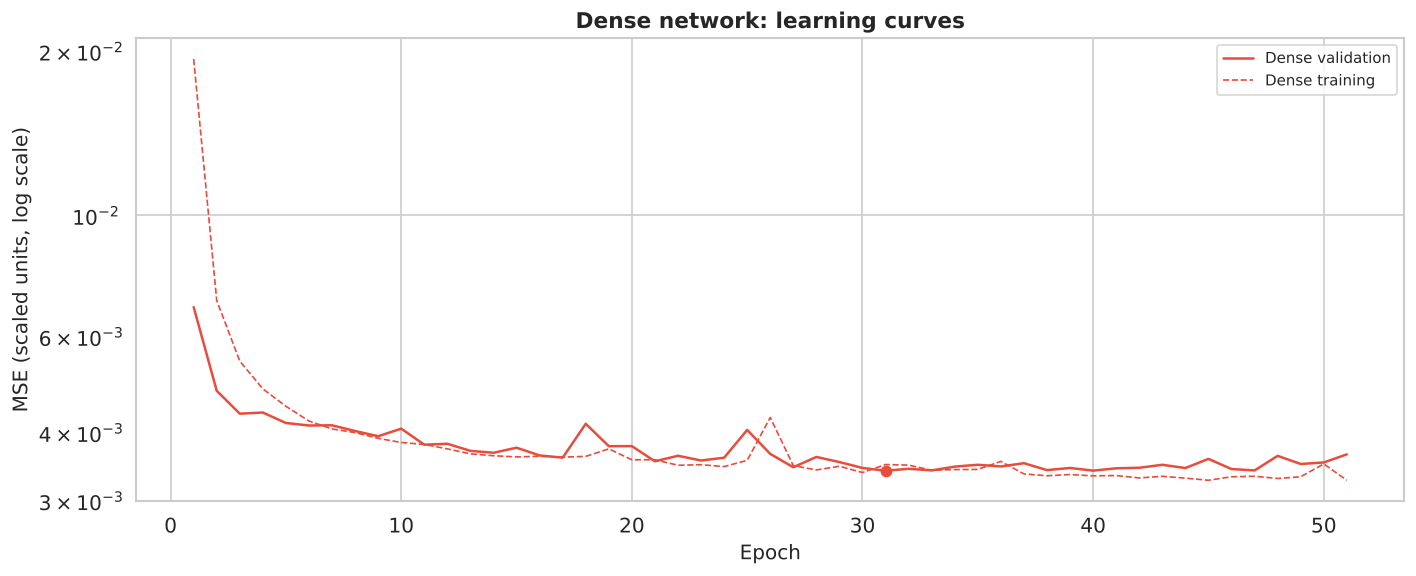

In [28]:
# Dense network with the default settings
dense_run = run_experiment('Dense')
val_results_1['Dense'] = dense_run['val']

# Size of the model and epoch whose weights are kept by early stopping
print(f'Dense: {count_params(dense_run["model"])} parameters, '
      f'best epoch {np.argmin(dense_run["history"]["val_loss"]) + 1} of {len(dense_run["history"]["loss"])}')
display(results_table(val_results_1))
plot_learning_curves({'Dense': dense_run['history']}, 'Dense network: learning curves')

- **3201** parameters: 48·64 + 64 in the hidden layer, 64 + 1 in the output layer.
- Validation RMSE **13.94**, about 5% below persistence (14.75), already with the default settings.
- The best epoch is the 31st; early stopping ends the training 20 epochs later.
- The validation loss is below the training loss: the validation period has no strong cycles, so it is easier to predict.

### 4.3 Simple RNN: value or change

**Simple RNN: theory.** The window is read one month at a time, and a hidden state h carries what has been seen so far, with the same weights at every step:

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b), \qquad \hat{y} = W_o h_L + b_o$$

- The order of the months is part of the model, and the number of parameters does not depend on L.
- Only the last state h_L is used for the prediction.

Example with the scaled inputs [0.1, 0.2, 0.3, 0.4], one unit, w_x = 1, w_h = 0.5 and b = 0:

| Step | Input x(t) | w_x·x(t) + w_h·h(t-1) | h(t) = tanh(·) |
| :---: | :---: | :---: | :---: |
| 1 | 0.1 | 0.1 + 0.5·0 = 0.100 | 0.100 |
| 2 | 0.2 | 0.2 + 0.5·0.100 = 0.250 | 0.245 |
| 3 | 0.3 | 0.3 + 0.5·0.245 = 0.422 | 0.399 |
| 4 | 0.4 | 0.4 + 0.5·0.399 = 0.599 | 0.537 |

The last state, 0.537, summarises the window. The first month reaches it only through three multiplications by w_h = 0.5 (and three tanh), so its effect is reduced to about 0.5³ ≈ 0.13: **the older months fade**. This is the limit that LSTM and GRU are designed to overcome.

**Value or change (`predict_delta`).** The scaling is the one fitted on the training months during the data preparation; it is not repeated here. With that scaling the largest training value (238.9, May 1778) becomes 1, while two test months are higher: October 1957 (253.8, which becomes **1.06**) and December 1957 (239.4). The output of a model can therefore be defined in two ways:

| Option | The network outputs | Prediction | Range of the target |
| :--- | :--- | :--- | :--- |
| value (`predict_delta=False`) | the next month | ŷ(t) = f(x) | some test values are above 1, never seen as a target |
| change (`predict_delta=True`) | the change from the last month | ŷ(t) = x(t-1) + f(x) | the same in all periods: -73.4 to +93.9 (training), -74.3 to +94.9 (test) |

Example: last month 0.98 and next month 1.04. The "value" model has to output 1.04, above every training target; the "change" model only has to output +0.06, a change like many others in the training set. In practice a "change" model starts from persistence and learns a correction to it.

In this section we train the Dense network and the Simple RNN in both versions, with the default settings, and keep for each model the version with the lower validation RMSE.

In [29]:
# The same model predicting the value itself or the change with respect to the last month
variant_runs = {}
for kind in ['Dense', 'SimpleRNN']:
    for delta in [False, True]:
        variant_runs[(kind, delta)] = run_experiment(kind, predict_delta=delta)

# One row per combination: validation scores and number of epochs before early stopping
variants = pd.DataFrame([
    {'model': kind, 'predicts': 'change' if delta else 'value',
     'val RMSE': run['val']['RMSE'], 'val MAE': run['val']['MAE'],
     'epochs': len(run['history']['loss'])}
    for (kind, delta), run in variant_runs.items()
]).round(2)
display(variants)

# For each model we keep the option with the lower validation RMSE
best_delta = {kind: min([False, True], key=lambda d: variant_runs[(kind, d)]['val']['RMSE'])
              for kind in ['Dense', 'SimpleRNN']}
print('Chosen option:', {kind: 'change' if d else 'value' for kind, d in best_delta.items()})

,model,predicts,val RMSE,val MAE,epochs
0,Dense,value,13.94,10.19,51
1,Dense,change,13.68,9.92,34
2,SimpleRNN,value,13.78,10.17,72
3,SimpleRNN,change,13.71,9.90,78


Chosen option: {'Dense': 'change', 'SimpleRNN': 'change'}


| Model | Value | Change |
| :--- | :---: | :---: |
| Dense | 13.94 | **13.68** |
| Simple RNN | 13.78 | **13.71** |

- Predicting the change is slightly better for both models.
- The gain is small because in the validation period all the values stay inside the training range (maximum scaled value 0.65); the advantage is expected on the test set, which goes beyond it.

#### Summary of 4.3
**Kept:** both models predict the **change** with respect to the last month.

### 4.4 Hyperparameter selection

Some settings are not learned during training and have to be chosen before it: the length of the window, the number of hidden units and the dropout. They are chosen on the validation RMSE, with the same grid for the Dense network and the Simple RNN, so that both models get the same chance. This also answers the question left open in the EDA: how many past months the models really need.

In this section we:
- train every `LOOKBACK` candidate of the correlation analysis (24, 48, 63, 125) with two hidden sizes (32 and 64), for both models;
- repeat the comparison of the windows on two earlier validation periods, to check that the choice does not depend on a single period;
- test dropout on the chosen configuration;
- check whether the square root before the scaling, suggested by the data preparation, improves the models.

lookback            24     48     63     125
model     hidden                            
Dense     32      13.74  13.50  13.73  13.87
          64      13.66  13.68  13.91  13.82
SimpleRNN 32      13.85  13.90  13.87  13.85
          64      13.82  13.71  13.90  13.73

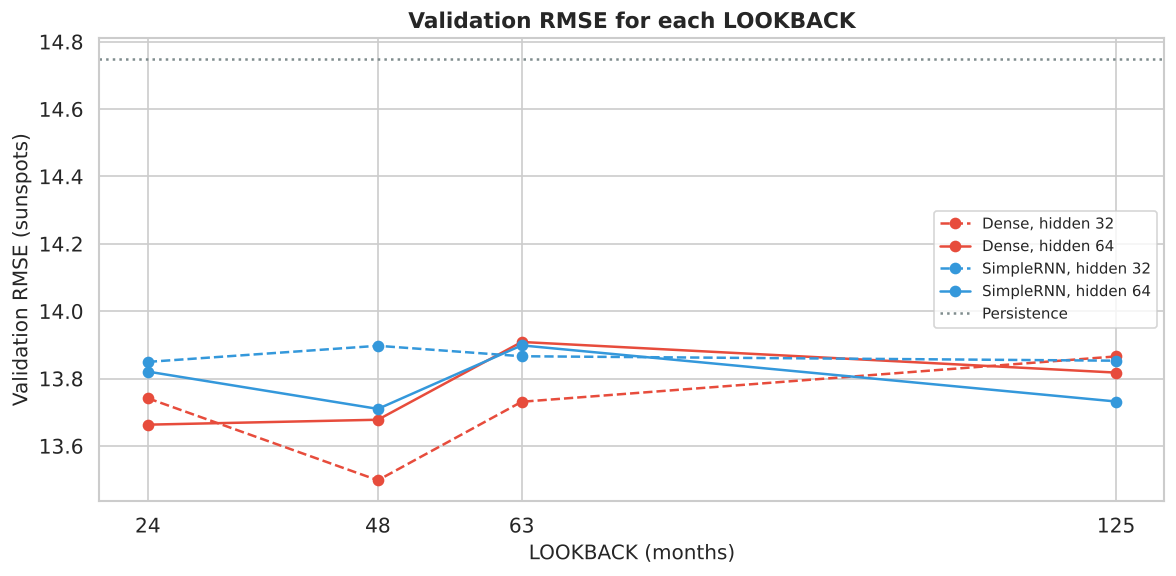

Hidden size with the lower average validation RMSE: {'Dense': 32, 'SimpleRNN': 64}


In [30]:
# Every LOOKBACK candidate with every hidden size, for both models
grid_runs = {}
for kind in ['Dense', 'SimpleRNN']:
    for lookback in LOOKBACK_CANDIDATES:
        for hidden in HIDDEN_CANDIDATES:
            grid_runs[(kind, lookback, hidden)] = run_experiment(
                kind, lookback, hidden=hidden, predict_delta=best_delta[kind])

# Validation RMSE of each configuration: one row per model and hidden size, one column per window
grid = pd.DataFrame([{'model': kind, 'lookback': lookback, 'hidden': hidden,
                      'val RMSE': run['val']['RMSE'], 'params': count_params(run['model'])}
                     for (kind, lookback, hidden), run in grid_runs.items()])
display(grid.pivot_table(index=['model', 'hidden'], columns='lookback', values='val RMSE').round(2))

# Same values as a plot: solid lines for 64 hidden units, dashed for 32
fig, ax = plt.subplots(figsize=(10, 5))
for (kind, hidden), rows in grid.groupby(['model', 'hidden']):
    ax.plot(rows['lookback'], rows['val RMSE'], marker='o', color=MODEL_COLORS[kind],
            linestyle='-' if hidden == max(HIDDEN_CANDIDATES) else '--', label=f'{kind}, hidden {hidden}')
ax.axhline(val_results_1['Persistence']['RMSE'], color=MODEL_COLORS['Persistence'], linestyle=':',
           label='Persistence')
ax.set_xticks(LOOKBACK_CANDIDATES)
ax.set_title('Validation RMSE for each LOOKBACK', fontsize=13, fontweight='bold')
ax.set_xlabel('LOOKBACK (months)')
ax.set_ylabel('Validation RMSE (sunspots)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Best hidden size of each model: lowest average validation RMSE over the four windows
best_hidden = {kind: int(grid[grid['model'] == kind].groupby('hidden')['val RMSE'].mean().idxmin())
               for kind in ['Dense', 'SimpleRNN']}
print('Hidden size with the lower average validation RMSE:', best_hidden)

- All 16 configurations beat persistence (14.75), but the RMSE only goes from **13.50 to 13.91**, with no clear trend with the length of the window.
- Hidden size with the lower average RMSE over the four windows: **32** for the Dense network and **64** for the Simple RNN.

**Chronological validation.** A single validation period of 23 years is a small sample, and the main one is quiet. To check the choice of `LOOKBACK`, the validation is repeated on earlier periods of the same length (282 months). In every fold the model is trained on the months before the validation period, so it never sees the future:

```
fold 2:  [ train 1749-1866 ][ val 1866-1889 ]
fold 1:  [ train 1749-1889             ][ val 1890-1913 ]
fold 0:  [ train 1749-1913                          ][ val 1913-1936 ]   <- main split
```

The scaler is fitted again on the training months of each fold, and the `LOOKBACK` with the lowest average validation RMSE over the three folds is chosen.

In [31]:
def square_positive(values):
    """Inverse of the square root; negative predictions are set to 0 before squaring."""
    return np.square(np.clip(values, 0, None))


def make_fold(lookback, horizon, val_start=None, transform='none'):
    """
    Same as make_dataset, but the validation period starts at month val_start (None = main split)
    and has the same length as the main one. The scaler is fitted again on the months before it,
    because every fold has to repeat the whole preprocessing. With transform = 'sqrt' the scaler is
    a square root followed by MinMax, and its inverse_transform squares the values back.
    """
    val_start = train_end if val_start is None else val_start
    sqrt_step = [FunctionTransformer(np.sqrt, inverse_func=square_positive)] if transform == 'sqrt' else []
    fold_scaler = make_pipeline(*sqrt_step, MinMaxScaler(feature_range=(0, 1)))

    # Scaler fitted only on the training months of this fold
    fold_scaler.fit(raw_values[:val_start].reshape(-1, 1))
    fold_scaled = fold_scaler.transform(raw_values.reshape(-1, 1)).flatten().astype(np.float32)
    X, y, first_target = make_windows(fold_scaled, lookback, horizon)
    return split_windows(X, y, first_target, horizon, val_start, val_start + n_val), fold_scaler


# Three validation periods of the same length, each one just before the previous one
fold_starts = [train_end - k * n_val for k in range(N_FOLDS)]
for k, start in enumerate(fold_starts):
    print(f'Fold {k}: train {df.index[0]:%Y-%m} to {df.index[start - 1]:%Y-%m}, '
          f'validation {df.index[start]:%Y-%m} to {df.index[start + n_val - 1]:%Y-%m}')

Fold 0: train 1749-01 to 1913-06, validation 1913-07 to 1936-12
Fold 1: train 1749-01 to 1889-12, validation 1890-01 to 1913-06
Fold 2: train 1749-01 to 1866-06, validation 1866-07 to 1889-12


- Fold 0 is the main split; each earlier validation period ends right before the next one.
- The training set becomes shorter going back in time: from 1974 months (fold 0) to 1410 (fold 2).

In [32]:
# Validation RMSE of every LOOKBACK on every fold (fold 0 is the grid above, already trained)
cv = []
for kind in ['Dense', 'SimpleRNN']:
    for lookback in LOOKBACK_CANDIDATES:
        for k, start in enumerate(fold_starts):
            if k == 0:
                rmse = grid_runs[(kind, lookback, best_hidden[kind])]['val']['RMSE']
            else:
                rmse = run_experiment(kind, lookback, val_start=start, hidden=best_hidden[kind],
                                      predict_delta=best_delta[kind])['val']['RMSE']
            cv.append({'model': kind, 'lookback': lookback, 'fold': k, 'val RMSE': rmse})
cv = pd.DataFrame(cv)

# One row per model and window: RMSE in each fold, average, and rank of the window in each fold
cv_table = cv.pivot_table(index=['model', 'lookback'], columns='fold', values='val RMSE')
cv_table['mean'] = cv_table.mean(axis=1)
cv_table['rank in each fold'] = (cv.assign(rank=cv.groupby(['model', 'fold'])['val RMSE'].rank())
                                   .pivot_table(index=['model', 'lookback'], columns='fold', values='rank')
                                   .astype(int).astype(str).agg(' '.join, axis=1))
display(cv_table.round(2))

# LOOKBACK with the lowest average validation RMSE over the folds
best_lookback = {kind: int(cv_table.loc[kind, 'mean'].idxmin()) for kind in ['Dense', 'SimpleRNN']}
print('Chosen LOOKBACK:', best_lookback)

fold                    0      1      2   mean rank in each fold
model     lookback                                              
Dense     24        13.74  13.60  13.98  13.78             3 3 1
          48        13.50  13.74  14.16  13.80             1 4 3
          63        13.73  13.44  14.00  13.72             2 1 2
          125       13.87  13.45  14.37  13.89             4 2 4
SimpleRNN 24        13.82  13.51  13.83  13.72             3 1 1
          48        13.71  13.68  14.14  13.84             1 4 2
          63        13.90  13.67  14.15  13.91             4 3 3
          125       13.73  13.57  14.16  13.82             2 2 4

Chosen LOOKBACK: {'Dense': 63, 'SimpleRNN': 24}


- The folds do not agree on the best window (see the ranks), and the average RMSE of the four candidates differs by **less than 0.2** for both models.
- **Kept:** the lowest average, **63 months** for the Dense network and **24 months** for the Simple RNN.
- Main result: one month ahead the length of the window has almost no effect. The last months already contain most of the information, as the autocorrelation showed; the older months add the phase of the cycle, which can matter at longer horizons.

In [33]:
# Dropout on the chosen configuration (0.2-0.3 is the range suggested for recurrent networks)
dropout_runs = {}
for kind in ['Dense', 'SimpleRNN']:
    for dropout in DROPOUT_CANDIDATES:
        dropout_runs[(kind, dropout)] = run_experiment(kind, best_lookback[kind], hidden=best_hidden[kind],
                                                       predict_delta=best_delta[kind], dropout=dropout)

display(pd.DataFrame([{'model': kind, 'dropout': dropout, 'val RMSE': run['val']['RMSE'],
                       'epochs': len(run['history']['loss'])}
                      for (kind, dropout), run in dropout_runs.items()]).round(2))

# Dropout with the lower validation RMSE for each model
best_dropout = {kind: min(DROPOUT_CANDIDATES, key=lambda p: dropout_runs[(kind, p)]['val']['RMSE'])
                for kind in ['Dense', 'SimpleRNN']}

# Final configuration of each one-step model
best_config_1 = {kind: {'lookback': best_lookback[kind], 'hidden': best_hidden[kind],
                        'predict_delta': best_delta[kind], 'dropout': best_dropout[kind]}
                 for kind in ['Dense', 'SimpleRNN']}
display(pd.DataFrame(best_config_1).T)

,model,dropout,val RMSE,epochs
0,Dense,0.0,13.73,39
1,Dense,0.2,13.96,36
2,SimpleRNN,0.0,13.82,42
3,SimpleRNN,0.2,13.82,44


,lookback,hidden,predict_delta,dropout
Dense,63,32,True,0.0
SimpleRNN,24,64,True,0.2


| Model | No dropout | Dropout 0.2 |
| :--- | :---: | :---: |
| Dense | **13.73** | 13.96 |
| Simple RNN | 13.82 | **13.82** (lower at the third decimal) |

- Dropout gives no real gain: the training and validation losses stay close, so the models are not overfitting and early stopping is already enough.
- Batch normalization is not used: it is placed between the hidden layers of deeper feed-forward networks, while these models have a single hidden or recurrent layer.

In [34]:
# Square root before the scaling (see the data preparation): the default model of every cell, with and without it.
# It is a choice of the preprocessing, so it is checked once for all the models and both horizons.
sqrt_check = []
for kind in ['Dense', 'SimpleRNN', 'LSTM', 'GRU']:
    for horizon in [1, FORECAST_HORIZON]:
        row = {'model': kind, 'horizon': horizon}
        for transform in ['none', 'sqrt']:
            run = run_experiment(kind, LOOKBACK, horizon, transform=transform)
            row[f'val RMSE, {transform}'] = run['val']['RMSE']
        row['difference'] = row['val RMSE, sqrt'] - row['val RMSE, none']
        sqrt_check.append(row)
sqrt_check = pd.DataFrame(sqrt_check).set_index(['model', 'horizon'])
display(sqrt_check.astype(float).round(2))
print(f'Better with the square root in {(sqrt_check["difference"] < 0).sum()} cases out of {len(sqrt_check)}, '
      f'average difference {sqrt_check["difference"].mean():+.2f}')

val RMSE, none  val RMSE, sqrt  difference
model     horizon                                            
Dense     1                 13.94           14.14        0.19
          6                 17.20           16.52       -0.68
SimpleRNN 1                 13.78           13.85        0.07
          6                 17.13           17.32        0.19
LSTM      1                 13.68           13.80        0.12
          6                 16.56           16.94        0.39
GRU       1                 13.52           13.47       -0.05
          6                 16.95           16.66       -0.29

Better with the square root in 3 cases out of 8, average difference -0.01


- The square root is better in **3 cases out of 8**, with an average difference of **-0.01**; the differences (-0.68 to +0.39) have the same size as the effect of the seed.
- A possible reason: the networks minimise the MSE on the transformed scale, where the errors on the peaks weigh less than in sunspots.
- The square root is **not used**: all the models keep the MinMax scaling.

#### Summary of 4.4
| Choice | Dense | Simple RNN | Evidence |
| :--- | :---: | :---: | :--- |
| Window (`LOOKBACK`) | 63 | 24 | lowest average RMSE over the three folds; differences below 0.2 |
| Hidden units | 32 | 64 | lowest average RMSE over the four windows |
| Output | change | change | lower validation RMSE than the value |
| Dropout | 0 | 0.2 | no overfitting; a tie for the Simple RNN |
| Square root before the scaling | no | no | better in 3 of 8 cases, average -0.01 |

One month ahead the settings matter little: all the configurations are within about 0.4 of RMSE from each other, and about 1 below persistence.

### 4.5 Evaluation on the test set

The chosen models are evaluated once on the test set, together with the two baselines. The test period (1937-1983) contains the most active cycles of the series, including its highest value (October 1957), so the errors are expected to be higher than on the validation set.

In this section we:
- compute the scores of the baselines and of the two networks on the test set, next to the validation ones;
- plot the real series and the predictions, with a vertical line where the test set begins;
- plot the learning curves of the chosen models.

validation                           test                  
                     MSE   RMSE        MAE          MSE       RMSE    MAE
Mean         1028.359985  32.07  27.540001  4087.310059  63.930000  49.66
Persistence   217.520004  14.75  10.490000   403.640015  20.090000  14.84
Dense         188.539993  13.73  10.020000   332.329987  18.230000  13.06
SimpleRNN     190.929993  13.82   9.890000   334.369995  18.290001  13.40

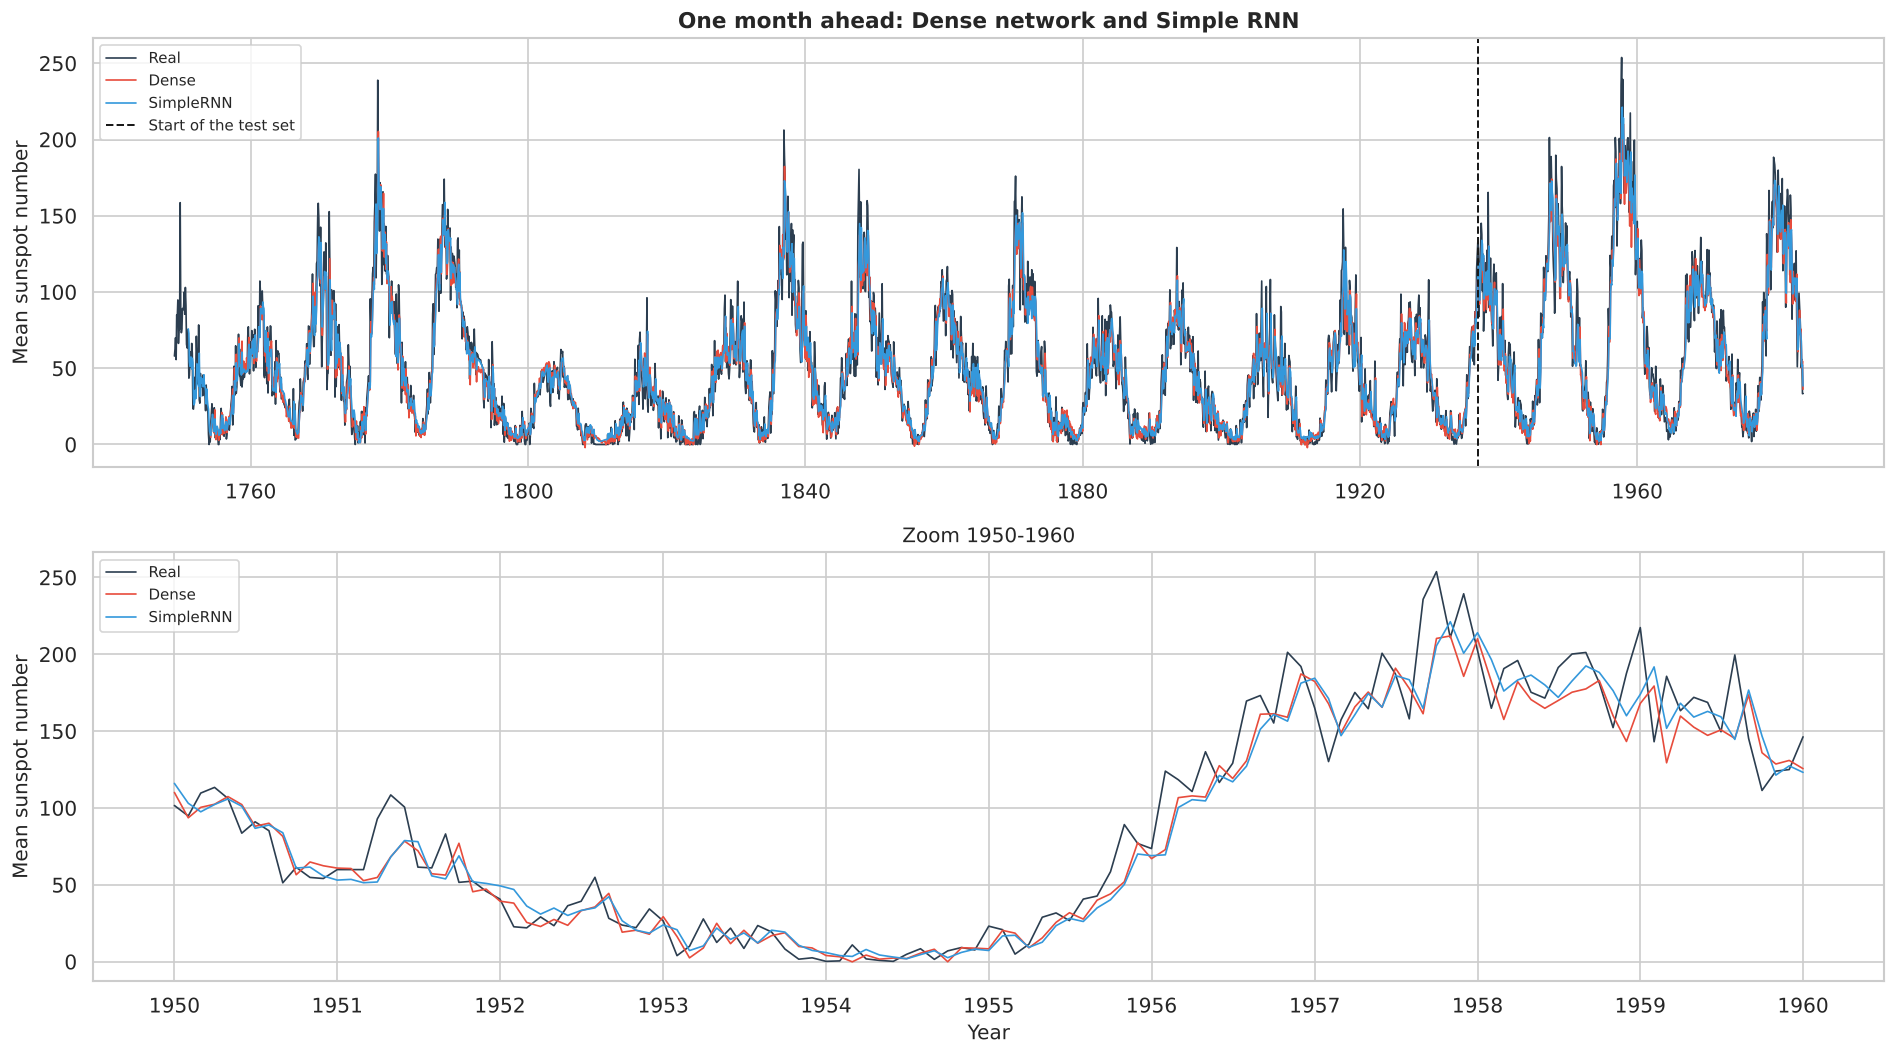

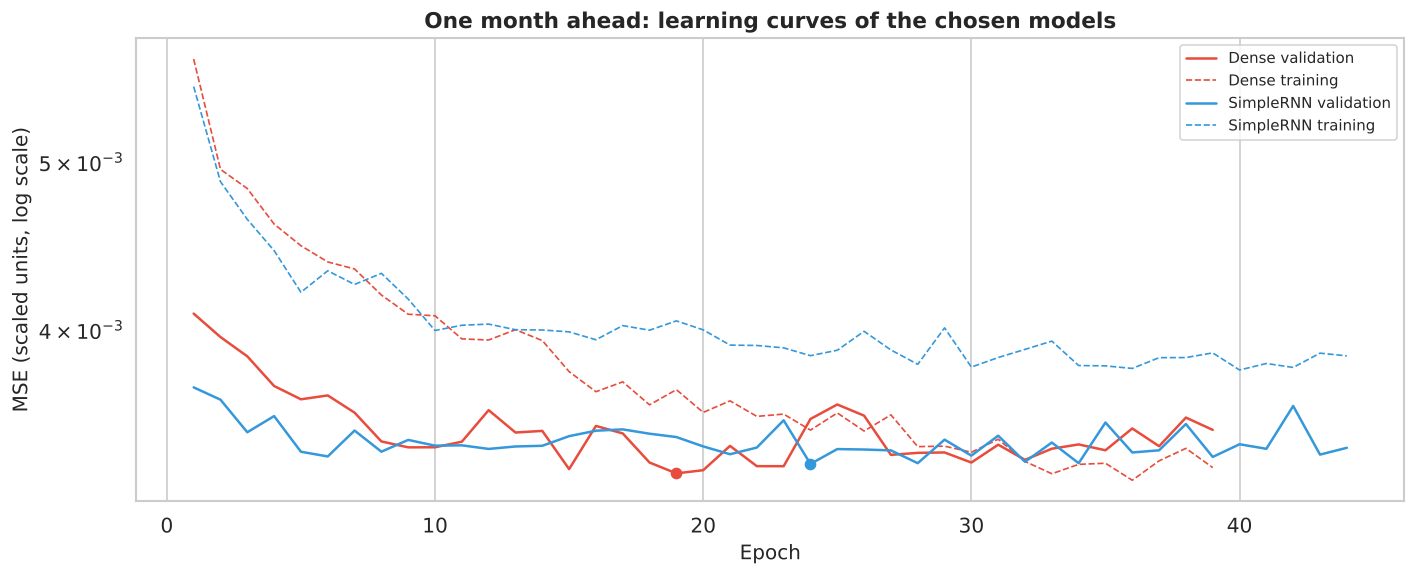

In [35]:
# The chosen models (already trained in the hyperparameter selection, with SEED)
final_runs_1 = {kind: dropout_runs[(kind, cfg['dropout'])] for kind, cfg in best_config_1.items()}

# Baselines and networks evaluated once on the test set
X_test_1, y_test_1, idx_test_1 = data_1['test']
test_results_1 = {
    'Mean': evaluate(y_test_1, mean_forecast(X_test_1)),
    'Persistence': evaluate(y_test_1, persistence_forecast(X_test_1)),
}
for kind, run in final_runs_1.items():
    X_test, y_test, _ = run['data']['test']          # each model uses the windows of its own LOOKBACK
    test_results_1[kind] = evaluate(y_test, predict(run['model'], X_test))

# Validation and test scores side by side
display(pd.concat({'validation': results_table({name: val_results_1[name] for name in ['Mean', 'Persistence']}
                                               | {kind: run['val'] for kind, run in final_runs_1.items()}),
                   'test': results_table(test_results_1)}, axis=1))

# Real series and predictions on training, validation and test, with the start of the test set
predictions = {}
for kind, run in final_runs_1.items():
    idx = np.concatenate([run['data'][split][2] for split in ['train', 'validation', 'test']])
    X = np.concatenate([run['data'][split][0] for split in ['train', 'validation', 'test']])
    predictions[kind] = (idx, predict(run['model'], X))
plot_forecast(predictions, 'One month ahead: Dense network and Simple RNN')
plot_learning_curves({kind: run['history'] for kind, run in final_runs_1.items()},
                     'One month ahead: learning curves of the chosen models')

| | Validation RMSE | Test RMSE | Test MAE |
| :--- | :---: | :---: | :---: |
| Mean | 32.07 | 63.93 | 49.66 |
| Persistence | 14.75 | 20.09 | 14.84 |
| Dense | 13.73 | **18.23** | **13.06** |
| Simple RNN | 13.82 | 18.29 | 13.40 |

- On the test set both networks beat persistence by about **9%**, and they reach almost the same error.
- All the errors are higher than on validation, as expected for the most active period; the mean is very poor (63.93) because the test period is much more active than the training one.
- In the zoom both models follow the real series closely, but they stay below the highest peaks of 1957-1958 and, like persistence, react to changes with some delay.

### 4.6 Discussion

The test results raise three questions:
- **Is the difference between the two networks real?** Each model depends on its random initial weights, so the chosen configurations are trained again with two more seeds. If the difference between the models is smaller than the variation due to the seed, it is not meaningful.
- **Do the models only copy the last month?** A model that copies the last value looks like the real series shifted by one month. The predictions are compared with the month to predict, x(t), and with the last month of the window, x(t-1). Example: with the months 60, 70 and 80, persistence predicts 80; if the real value is 88 and a model predicts 86, the model is 2 away from x(t) and 6 away from x(t-1), while a model that copies the last month is 0 away from x(t-1).
- **Where are the errors?** The variability grows with the level of the series, so the error is split between low months (below 50) and high months (100 or more).

In this section we:
- train the chosen configurations with three seeds and compare the spread of the results;
- compare the predictions with x(t) and with x(t-1), and split the error by level.

In [36]:
# The chosen configurations trained again with different seeds
seed_results = []
for kind, cfg in best_config_1.items():
    for seed in SEEDS:
        # The model with SEED is already trained; the other two seeds are trained (or loaded) here
        run = final_runs_1[kind] if seed == SEED else run_experiment(
            kind, cfg['lookback'], seed=seed, hidden=cfg['hidden'],
            predict_delta=cfg['predict_delta'], dropout=cfg['dropout'])
        X_test, y_test, _ = run['data']['test']
        seed_results.append({'model': kind, 'seed': seed, 'val RMSE': run['val']['RMSE'],
                             'test RMSE': evaluate(y_test, predict(run['model'], X_test))['RMSE']})
seed_results = pd.DataFrame(seed_results)

# Mean and standard deviation over the three seeds
display(seed_results.groupby('model')[['val RMSE', 'test RMSE']].agg(['mean', 'std']).round(2))
print(f'Persistence test RMSE: {test_results_1["Persistence"]["RMSE"]:.2f}')

val RMSE        test RMSE      
              mean   std       mean   std
model                                    
Dense        13.72  0.01  18.360001  0.24
SimpleRNN    13.80  0.02  18.510000  0.21

Persistence test RMSE: 20.09


| Model | Test RMSE over 3 seeds |
| :--- | :---: |
| Dense | 18.36 ± 0.24 |
| Simple RNN | 18.51 ± 0.21 |

- The difference between the two models (0.15) is smaller than the variation due to the seed: one month ahead **the Simple RNN is not better than the Dense network**.
- Both are clearly better than persistence (20.09), by about 1.6-1.7, seven to eight times the standard deviation.

In [37]:
# Does the model only copy the last month? Distance of the predictions from x(t) and from x(t-1)
real = raw_values[idx_test_1]                    # x(t), the month to predict
previous = raw_values[idx_test_1 - 1]            # x(t-1), the last month of the window
low, high = real < 50, real >= 100               # quiet months and active months

rows = []
for name in ['Persistence', 'Dense', 'SimpleRNN']:
    if name == 'Persistence':
        pred = previous                          # persistence is exactly x(t-1)
    else:
        run = final_runs_1[name]
        pred = to_sunspots(predict(run['model'], run['data']['test'][0])).ravel()
    rows.append({'model': name,
                 'RMSE vs x(t)': np.sqrt(np.mean((pred - real) ** 2)),
                 'RMSE vs x(t-1)': np.sqrt(np.mean((pred - previous) ** 2)),
                 'RMSE months < 50': np.sqrt(np.mean((pred - real)[low] ** 2)),
                 'RMSE months >= 100': np.sqrt(np.mean((pred - real)[high] ** 2))})
display(pd.DataFrame(rows).set_index('model').round(2))
print(f'Test months below 50: {low.sum()}, at 100 or more: {high.sum()}')

,RMSE vs x(t),RMSE vs x(t-1),RMSE months < 50,RMSE months >= 100
model,,,,
Persistence,20.090000,0.00,10.64,27.270000
Dense,18.230000,9.88,9.34,25.190001
SimpleRNN,18.290001,8.99,9.62,24.910000


Test months below 50: 217, at 100 or more: 193


- The predictions are much closer to the last month of the window (RMSE about 9-10) than to the month to predict (about 18): both models stay close to persistence and only add a correction to it.
- The largest errors are in the high months: about **25** when the real value is 100 or more, against 9-10 below 50.
- In absolute terms the networks improve persistence more at the peaks (from 27.27 to about 25) than in the quiet months (from 10.64 to about 9.5).
- One month ahead the recurrent structure gives no advantage: the forecast mostly needs the last few values, not a long memory. The six-step forecast tests whether this changes further ahead.

---
## 5. Multi-Step Forecasting (6 Months Ahead): Recursive vs Direct

In this section we predict the next six months with the two approaches seen in class, recursive and direct, for both the Simple RNN and the Dense network, and we answer the question of which approach works better.

### 5.1 Two multi-step approaches

Two approaches predict H > 1 months.

**Recursive.** The one-step model is applied H times: each prediction is appended to the window and the oldest month is dropped, so the window keeps the same length. Example with a window that ends with the months 80 and 90:

| Step | Last months of the input | Prediction |
| :---: | :---: | :---: |
| 1 | ..., 80, 90 | 95 |
| 2 | ..., 90, **95** | 99 |
| 3 | ..., 95, **99** | 102 |

- No new model has to be trained.
- From the second step on the input contains predictions (in bold) instead of real values: if the first prediction is wrong, for example 95 instead of a real 98, the second step starts from a wrong value, and the errors can **accumulate** along the horizon.

**Direct.** A model with six outputs, `Linear(hidden, 6)`, predicts the six months at once from the real values of the window, for example [95, 99, 102, 104, 105, 105].
- There is no accumulation of errors.
- The model is trained for this horizon only.

**Persistence six months ahead** is a flat line. After a last value of 90, if the cycle rises by 5 sunspots per month (95, 100, ..., 120), persistence is too low by 5 at the first step and by **30** at the sixth; in a decaying phase it is too high in the same way. To do better a model has to recognise the phase of the cycle, which is contained in the older months of the window, so the length of the window is checked again.

All the methods are evaluated on the same **559** test windows, with the same six targets.

In this section we:
- apply the one-step models recursively;
- train direct models with six outputs, choosing their settings with the same procedure as the one-step models;
- compare the two approaches, the Dense network and the Simple RNN on the validation and test sets;
- check whether the differences are larger than the effect of the seed, and how the models behave in the different phases of the cycle.

### 5.2 Approach 1: Recursive

The recursive forecast does not need new models: the one-step models chosen in the hyperparameter selection are applied to the six-step windows, each with its own `LOOKBACK`. The split is fixed on the months, so the six-step windows contain the same months for every window length and all the methods are compared on the same targets.

In this section we:
- write `recursive_forecast`, which uses a one-step model six times;
- compute the validation RMSE of every step for the Dense network and the Simple RNN.

In [38]:
@torch.no_grad()
def recursive_forecast(model, X, horizon=FORECAST_HORIZON):
    """
    Uses a 1-step model `horizon` times: each prediction is appended to the window and the oldest
    value is dropped, so the window length stays the same. Returns (N, horizon).
    """
    model.eval()
    window = torch.as_tensor(X, device=DEVICE).clone()       # copy, so X is not modified
    predictions = []
    for _ in range(horizon):
        next_value = model(window)                                          # (N, 1)
        predictions.append(next_value)
        # Drop the oldest month and append the prediction: (N, lookback, 1) -> same shape
        window = torch.cat([window[:, 1:, :], next_value.unsqueeze(1)], dim=1)
    return torch.cat(predictions, dim=1).cpu().numpy()      # one column per step


MODELS = ['Dense', 'SimpleRNN']

# The chosen 1-step models, applied to the 6-step windows (each with its own LOOKBACK)
recursive_data = {kind: make_dataset(best_config_1[kind]['lookback'], FORECAST_HORIZON) for kind in MODELS}
recursive_val = {}
for kind in MODELS:
    X_val, y_val, _ = recursive_data[kind]['validation']
    recursive_val[kind] = evaluate(y_val, recursive_forecast(final_runs_1[kind]['model'], X_val))

for kind in MODELS:
    print(f'{kind} recursive, validation RMSE per step: {np.round(recursive_val[kind]["RMSE per step"], 2)}')

Dense recursive, validation RMSE per step: [13.66 16.05 16.77 17.34 18.2  18.68]
SimpleRNN recursive, validation RMSE per step: [13.71 16.34 17.3  18.19 19.43 20.09]


- The validation RMSE grows from **13.7** at the first step to **18.7** (Dense) and **20.1** (Simple RNN) at the sixth; persistence reaches 23.7 at the sixth step.

#### Summary of 5.2
The recursive approach needs no new training and beats persistence at every step, but its error grows quickly along the horizon, faster for the Simple RNN than for the Dense network.

### 5.3 Approach 2: Direct

The direct models are the same classes with `horizon = 6`, trained with the MSE averaged over the six outputs. Their settings are chosen with the same steps as the one-step models. The hidden size of the one-step models is kept, so that the main question is the length of the window: six months ahead the older months could be needed to recognise the phase of the cycle.

In this section we:
- choose between predicting the value and predicting the change;
- choose `LOOKBACK` on the three validation periods of the chronological validation;
- test dropout on the chosen configuration.

In [39]:
# Value or change, with the default LOOKBACK and the hidden size of the 1-step models
variant_runs_6 = {(kind, delta): run_experiment(kind, LOOKBACK, horizon=FORECAST_HORIZON,
                                                hidden=best_hidden[kind], predict_delta=delta)
                  for kind in MODELS for delta in [False, True]}

# Validation RMSE over the six steps and at the sixth step
display(pd.DataFrame([{'model': kind, 'predicts': 'change' if delta else 'value',
                       'val RMSE': run['val']['RMSE'], 'val RMSE step 6': run['val']['RMSE per step'][-1]}
                      for (kind, delta), run in variant_runs_6.items()]).round(2))

# For each model we keep the option with the lower validation RMSE
best_delta_6 = {kind: min([False, True], key=lambda d: variant_runs_6[(kind, d)]['val']['RMSE'])
                for kind in MODELS}
print('Chosen option:', {kind: 'change' if d else 'value' for kind, d in best_delta_6.items()})

,model,predicts,val RMSE,val RMSE step 6
0,Dense,value,17.049999,17.980000
1,Dense,change,17.090000,18.959999
2,SimpleRNN,value,17.129999,19.200001
3,SimpleRNN,change,17.260000,19.760000


Chosen option: {'Dense': 'value', 'SimpleRNN': 'value'}


| Model | Value | Change |
| :--- | :---: | :---: |
| Dense | **17.05** | 17.09 |
| Simple RNN | **17.13** | 17.26 |

- The two options are very close (0.13 at most), and this time predicting the **value** is slightly better for both models.
- A possible reason: over six months the change is no longer small, since the cycle can move by tens of sunspots, so starting from the last month helps less than one month ahead.

fold                        0      1          2       mean rank in each fold
model     lookback                                                          
Dense     24        17.590000  14.43  17.350000  16.450001             4 4 3
          48        17.049999  14.29  17.320000  16.219999             3 2 2
          63        16.990000  14.37  17.290001  16.219999             2 3 1
          125       16.690001  13.79  18.559999  16.350000             1 1 4
SimpleRNN 24        17.180000  14.16  17.480000  16.280001             4 1 4
          48        17.129999  14.26  17.280001  16.230000             3 3 3
          63        17.030001  14.31  17.080000  16.139999             1 4 1
          125       17.090000  14.23  17.180000  16.170000             2 2 2

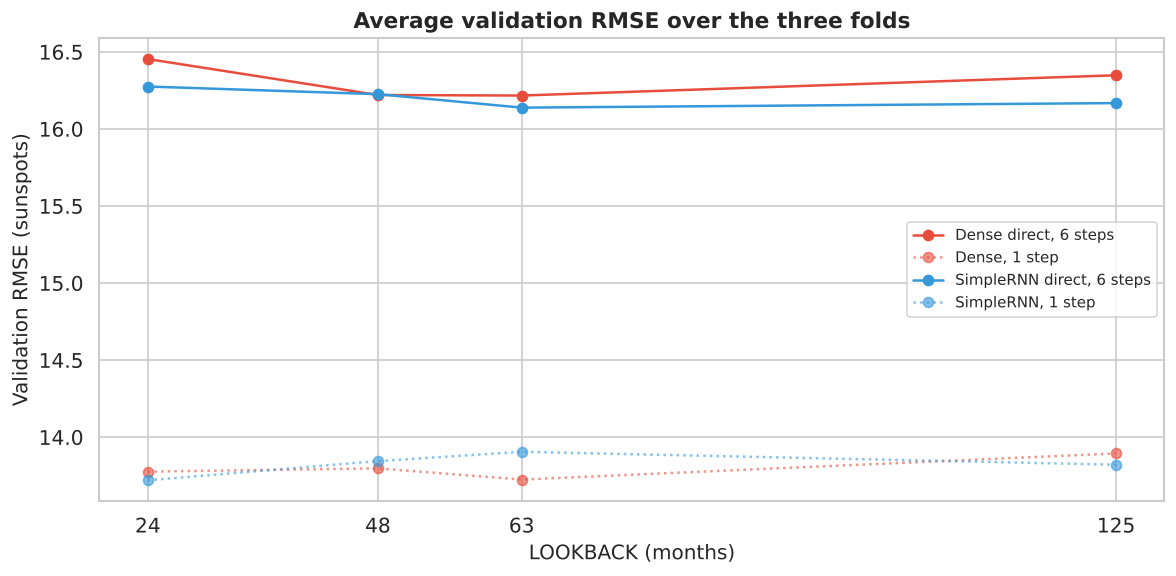

Chosen LOOKBACK: {'Dense': 63, 'SimpleRNN': 63}


In [40]:
# Every LOOKBACK candidate on the three validation periods (fold 0 is the main split)
direct_runs = {}
cv_6 = []
for kind in MODELS:
    for lookback in LOOKBACK_CANDIDATES:
        for k, start in enumerate(fold_starts):
            run = run_experiment(kind, lookback, horizon=FORECAST_HORIZON, val_start=None if k == 0 else start,
                                 hidden=best_hidden[kind], predict_delta=best_delta_6[kind])
            if k == 0:
                direct_runs[(kind, lookback)] = run
            cv_6.append({'model': kind, 'lookback': lookback, 'fold': k, 'val RMSE': run['val']['RMSE']})
cv_6 = pd.DataFrame(cv_6)

# One row per model and window: RMSE in each fold, average, and rank of the window in each fold
cv_table_6 = cv_6.pivot_table(index=['model', 'lookback'], columns='fold', values='val RMSE')
cv_table_6['mean'] = cv_table_6.mean(axis=1)
cv_table_6['rank in each fold'] = (cv_6.assign(rank=cv_6.groupby(['model', 'fold'])['val RMSE'].rank())
                                     .pivot_table(index=['model', 'lookback'], columns='fold', values='rank')
                                     .astype(int).astype(str).agg(' '.join, axis=1))
display(cv_table_6.round(2))

# Average over the folds: six months ahead (solid) and one month ahead (dotted)
fig, ax = plt.subplots(figsize=(10, 5))
for kind in MODELS:
    ax.plot(LOOKBACK_CANDIDATES, cv_table_6.loc[kind, 'mean'], marker='o', color=MODEL_COLORS[kind],
            label=f'{kind} direct, 6 steps')
    ax.plot(LOOKBACK_CANDIDATES, cv_table.loc[kind, 'mean'], marker='o', color=MODEL_COLORS[kind],
            linestyle=':', alpha=0.6, label=f'{kind}, 1 step')
ax.set_xticks(LOOKBACK_CANDIDATES)
ax.set_title('Average validation RMSE over the three folds', fontsize=13, fontweight='bold')
ax.set_xlabel('LOOKBACK (months)')
ax.set_ylabel('Validation RMSE (sunspots)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# LOOKBACK with the lowest average validation RMSE over the folds
best_lookback_6 = {kind: int(cv_table_6.loc[kind, 'mean'].idxmin()) for kind in MODELS}
print('Chosen LOOKBACK:', best_lookback_6)

- The folds do not agree on the best window (see the ranks), and the average RMSE of the four candidates differs by **less than 0.25** for both models.
- The errors are higher than one month ahead, but both curves are **flat**: against the expectation, a longer window does not help here either.
- A possible explanation: two years of history already show whether the cycle is rising or decaying, and the monthly noise limits what the older months can add.
- **Kept:** **63 months** for both models, the lowest average (for the Dense network tied with 48 months at two decimals).

In [41]:
# Dropout on the chosen configuration, as for the 1-step models
dropout_runs_6 = {(kind, p): run_experiment(kind, best_lookback_6[kind], horizon=FORECAST_HORIZON,
                                            hidden=best_hidden[kind], predict_delta=best_delta_6[kind], dropout=p)
                  for kind in MODELS for p in DROPOUT_CANDIDATES}
display(pd.DataFrame([{'model': kind, 'dropout': p, 'val RMSE': run['val']['RMSE']}
                      for (kind, p), run in dropout_runs_6.items()]).round(2))

# Final configuration of the two direct models and their trained runs
best_config_6 = {kind: {'lookback': best_lookback_6[kind], 'hidden': best_hidden[kind],
                        'predict_delta': best_delta_6[kind],
                        'dropout': min(DROPOUT_CANDIDATES, key=lambda p: dropout_runs_6[(kind, p)]['val']['RMSE'])}
                 for kind in MODELS}
direct_final = {kind: dropout_runs_6[(kind, cfg['dropout'])] for kind, cfg in best_config_6.items()}
display(pd.DataFrame(best_config_6).T)

,model,dropout,val RMSE
0,Dense,0.0,16.990000
1,Dense,0.2,16.680000
2,SimpleRNN,0.0,17.030001
3,SimpleRNN,0.2,17.299999


,lookback,hidden,predict_delta,dropout
Dense,63,32,False,0.2
SimpleRNN,63,64,False,0.0


- Dropout helps the Dense network (from 16.99 to **16.68**) but not the Simple RNN (from 17.03 to 17.30), so it is used only in the Dense network.

#### Summary of 5.3
| Choice | Dense | Simple RNN |
| :--- | :---: | :---: |
| Window (`LOOKBACK`) | 63 | 63 |
| Hidden units | 32 | 64 |
| Output | value | value |
| Dropout | 0.2 | 0 |

As one month ahead, the length of the window has little effect on the error.

### 5.4 Comparison on the validation set

Before using the test set, the six methods (two baselines, two models with two approaches each) are compared on the validation set, with the RMSE of every step.

In this section we:
- write a function that shows the RMSE of every step in one table;
- compare the six methods on the validation set.

In [42]:
def per_step_table(results):
    """RMSE of every forecast step, overall RMSE and MAE in sunspot units, from {name: scores}."""
    table = pd.DataFrame({name: scores['RMSE per step'] for name, scores in results.items()}).T
    table.columns = [f'step {k + 1}' for k in table.columns]
    table['RMSE'] = [scores['RMSE'] for scores in results.values()]
    table['MAE'] = [scores['MAE'] for scores in results.values()]
    return table.round(2)


# Baselines on the 6-step validation windows (LOOKBACK = 48; the targets are the same for every LOOKBACK)
X_val_6, y_val_6, idx_val_6 = data_6['validation']
val_results_6 = {
    'Mean': evaluate(y_val_6, mean_forecast(X_val_6, FORECAST_HORIZON)),
    'Persistence': evaluate(y_val_6, persistence_forecast(X_val_6, FORECAST_HORIZON)),
}
# Networks: recursive (chosen 1-step models) and direct
for kind in MODELS:
    val_results_6[f'{kind} recursive'] = recursive_val[kind]
    val_results_6[f'{kind} direct'] = direct_final[kind]['val']
display(per_step_table(val_results_6))

,step 1,step 2,step 3,step 4,step 5,step 6,RMSE,MAE
Mean,31.469999,31.459999,31.400000,31.400000,31.580000,31.820000,31.520000,27.10
Persistence,14.610000,18.290001,19.270000,20.010000,22.410000,23.709999,19.930000,14.36
Dense recursive,13.660000,16.049999,16.770000,17.340000,18.200001,18.680000,16.860001,12.37
Dense direct,14.490000,15.830000,16.459999,17.020000,17.840000,18.160000,16.680000,12.32
SimpleRNN recursive,13.710000,16.340000,17.299999,18.190001,19.430000,20.090000,17.639999,12.75
SimpleRNN direct,13.710000,15.970000,16.809999,17.600000,18.530001,19.010000,17.030001,12.50


- All four networks beat persistence at every step, and the gap grows with the horizon: at the sixth step the RMSE goes from **23.71** for persistence to 18.2-20.1 for the networks.
- First step: the recursive approach is better or equal, because there it is exactly the one-step model.
- From the second step on the direct approach is better; at the sixth step it beats the recursive one by 0.5 (Dense) and 1.1 (Simple RNN): the recursive errors accumulate.

#### Summary of 5.4
On the validation set the **recursive approach is the best at the first step and the direct approach at every following step**, for both models.

### 5.5 Evaluation on the test set

The test set is used once, for all the methods at the same time.

In this section we:
- compute the RMSE of every step on the test set;
- plot the RMSE as a function of the forecast step;
- plot the real series and the forecasts six months ahead, with the start of the test set;
- look at three example windows: a rising phase, a peak and a decaying phase.

In [43]:
# All the 6-step forecasts on the test set (same 559 windows and targets for every method)
X_test_6, y_test_6, idx_test_6 = data_6['test']
test_forecasts_6 = {
    'Mean': (idx_test_6, mean_forecast(X_test_6, FORECAST_HORIZON)),
    'Persistence': (idx_test_6, persistence_forecast(X_test_6, FORECAST_HORIZON)),
}
for kind in MODELS:
    # Recursive: the chosen 1-step model, on the windows of its own LOOKBACK
    X, _, idx = recursive_data[kind]['test']
    test_forecasts_6[f'{kind} recursive'] = (idx, recursive_forecast(final_runs_1[kind]['model'], X))
    # Direct: the 6-output model, on the windows of its own LOOKBACK
    X, _, idx = direct_final[kind]['data']['test']
    test_forecasts_6[f'{kind} direct'] = (idx, predict(direct_final[kind]['model'], X))

test_results_6 = {name: evaluate(y_test_6, pred) for name, (idx, pred) in test_forecasts_6.items()}
display(per_step_table(test_results_6))

,step 1,step 2,step 3,step 4,step 5,step 6,RMSE,MAE
Mean,64.199997,64.110001,64.010002,63.990002,63.930000,63.860001,64.019997,49.730000
Persistence,20.129999,24.490000,26.020000,27.520000,29.309999,31.230000,26.690001,20.020000
Dense recursive,18.280001,21.240000,22.410000,23.350000,24.330000,25.240000,22.590000,16.780001
Dense direct,19.520000,21.910000,22.230000,22.340000,23.650000,25.080000,22.520000,16.870001
SimpleRNN recursive,18.330000,21.240000,22.459999,23.620001,24.770000,25.850000,22.850000,17.070000
SimpleRNN direct,19.400000,22.110001,23.150000,23.400000,24.200001,24.790001,22.910000,17.080000


- Persistence: RMSE **26.69** over the six steps and **31.23** at the sixth.
- Networks: about 22.5-22.9 over the six steps (**about 15% lower**, against 9% one month ahead) and about 25 at the sixth step (**20% lower**).
- The mean of the training months stays far from all the other methods (about 64).

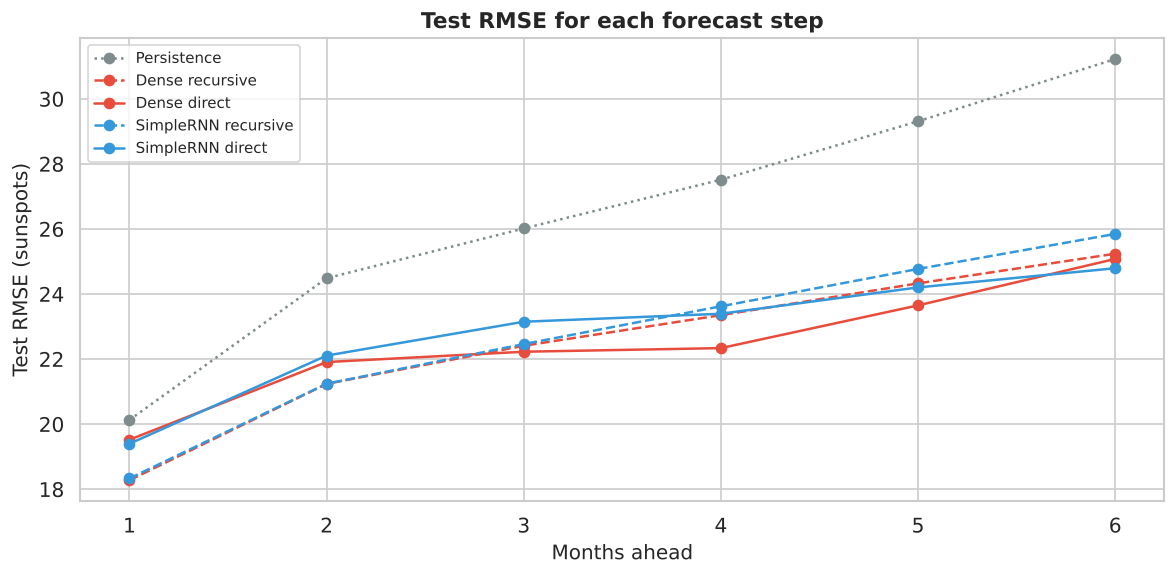

In [44]:
# RMSE as a function of the forecast step: one colour per model, dashed = recursive, solid = direct
styles = {'Mean': ('Mean', ':'), 'Persistence': ('Persistence', ':')}
styles.update({f'{kind} {approach}': (kind, '--' if approach == 'recursive' else '-')
               for kind in MODELS for approach in ['recursive', 'direct']})
fig, ax = plt.subplots(figsize=(10, 5))
steps = np.arange(1, FORECAST_HORIZON + 1)
for name, scores in test_results_6.items():
    if name == 'Mean':
        continue                                   # far above the others (see the table)
    color_key, linestyle = styles[name]
    ax.plot(steps, scores['RMSE per step'], marker='o', color=MODEL_COLORS[color_key],
            linestyle=linestyle, label=name)
ax.set_title('Test RMSE for each forecast step', fontsize=13, fontweight='bold')
ax.set_xlabel('Months ahead')
ax.set_ylabel('Test RMSE (sunspots)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

- First step: the recursive approach is the best (18.3 against 19.4-19.5), but its error grows faster.
- The direct approach catches up after three to four months, and at the sixth step the direct Simple RNN is the best method (**24.79** against 25.85 for the recursive one).
- For the Dense network the two approaches are very close; over the six steps the four methods are within 0.4 of each other.

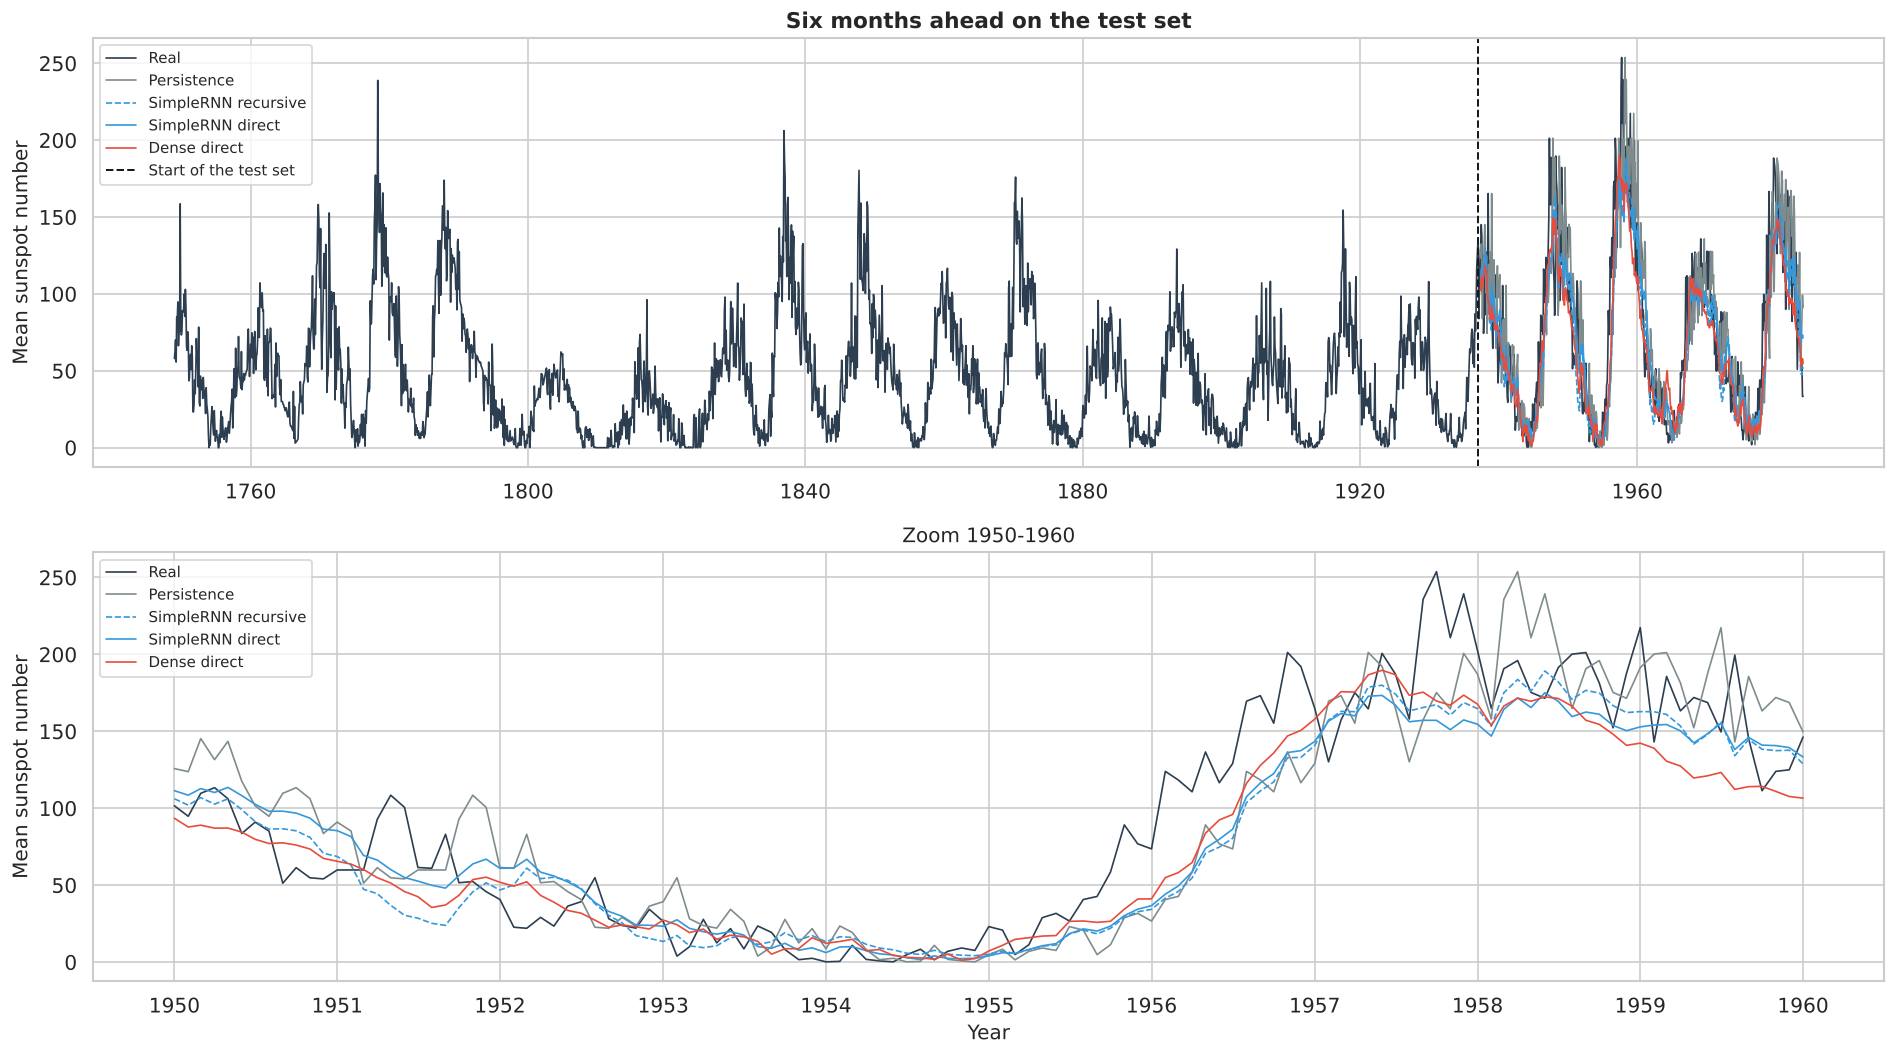

In [45]:
# Six months ahead on the test set: the same plot as one month ahead, with the last forecast step
plot_forecast({name: test_forecasts_6[name] for name in ['Persistence', 'SimpleRNN recursive', 'SimpleRNN direct', 'Dense direct']},
              'Six months ahead on the test set', step=FORECAST_HORIZON - 1)

- Each model has its colour, and the recursive forecast is dashed.
- Compared with one month ahead the forecasts are further from the real series and lag more behind it, because every point is predicted half a year in advance.

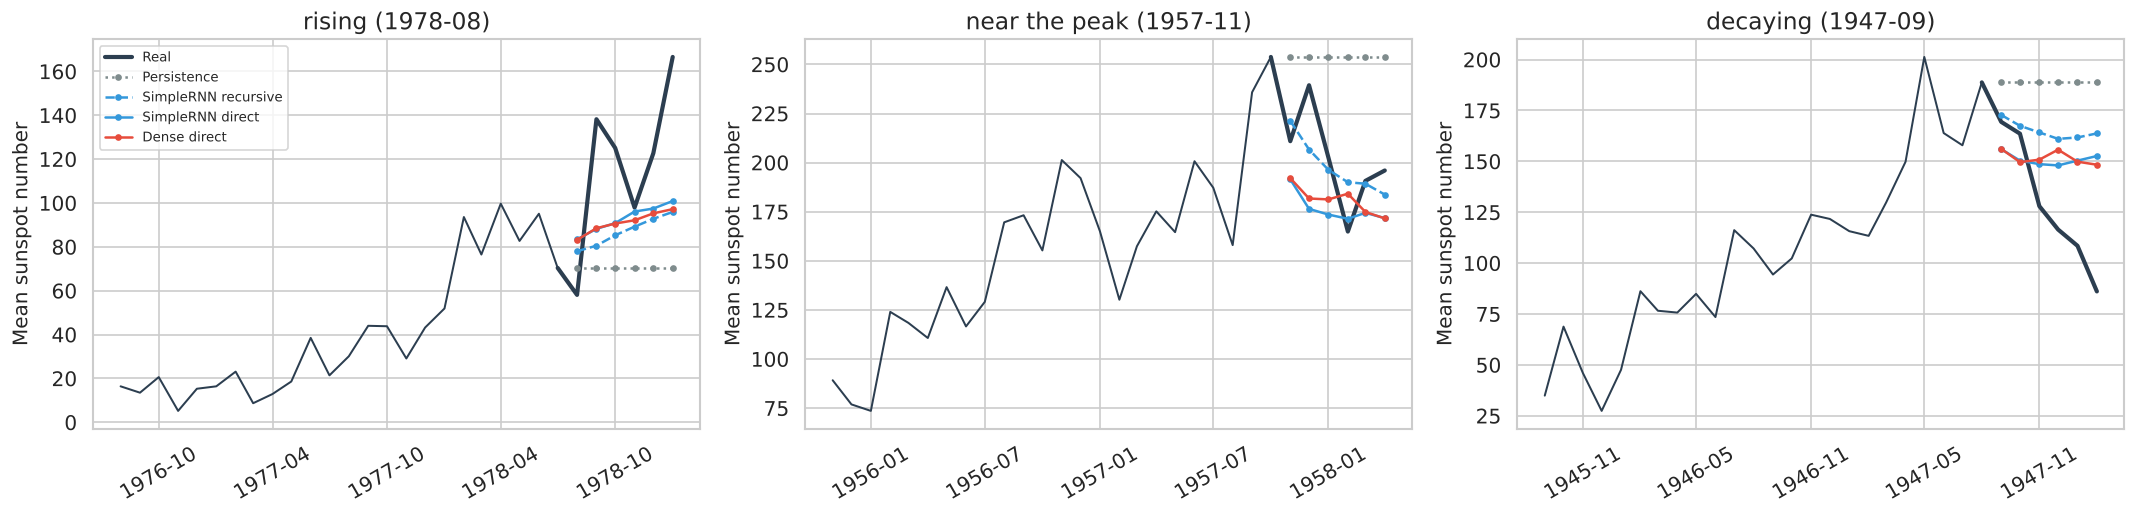

In [46]:
from matplotlib.dates import DateFormatter, MonthLocator

# Three example windows of the test set: the strongest rise, the highest last value, the strongest decay
real_change = to_sunspots(y_test_6)[:, -1] - to_sunspots(X_test_6[:, -1, :]).ravel()   # month 6 - last month
examples = {'rising': np.argmax(real_change),
            'near the peak': np.argmax(to_sunspots(X_test_6[:, -1, :]).ravel()),
            'decaying': np.argmin(real_change)}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (label, i) in zip(axes, examples.items()):
    start = idx_test_6[i]                                     # first month to predict
    past = np.arange(start - 24, start)                       # last two years of the window
    future = np.arange(start, start + FORECAST_HORIZON)       # the six months to predict
    ax.plot(df.index[past], raw_values[past], color=MODEL_COLORS['Ground Truth'], linewidth=1.2)
    ax.plot(df.index[start - 1:start + FORECAST_HORIZON], raw_values[start - 1:start + FORECAST_HORIZON],
            color=MODEL_COLORS['Ground Truth'], linewidth=2.5, label='Real')
    for name in ['Persistence', 'SimpleRNN recursive', 'SimpleRNN direct', 'Dense direct']:
        color_key, linestyle = styles[name]
        ax.plot(df.index[future], to_sunspots(test_forecasts_6[name][1][i]), color=MODEL_COLORS[color_key],
                linestyle=linestyle, marker='o', markersize=3, label=name)
    ax.set_title(f'{label} ({df.index[start]:%Y-%m})')
    ax.set_ylabel('Mean sunspot number')
    ax.xaxis.set_major_locator(MonthLocator(interval=6))      # one date label every six months
    ax.xaxis.set_major_formatter(DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=30)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

| Window | What happens |
| :--- | :--- |
| Rising (1978) | all the networks predict a rise, but much smaller than the real one |
| Near the peak (1957) | persistence stays at the maximum, while the networks correctly predict a decrease |
| Decaying (1947) | the networks predict a decrease, but slower than the real one; persistence is a flat line |

On the test set the networks are about 15% better than persistence over the six steps and 20% better at the sixth step, a larger gain than one month ahead. The recursive approach wins at the first step, the direct one at the last steps.

### 5.6 Discussion: which approach works better?

Two checks complete the comparison:
- **Seeds.** Every method is trained again with two more seeds, as for the one-step models, to see whether the differences between the methods are larger than the effect of the random initial weights.
- **Phase of the cycle.** Six months ahead the error of persistence should depend on the phase: negative (too low) when the cycle rises, positive (too high) when it decays. A model that recognises the phase should reduce this bias. The phase of each window is defined by the real change between the last month of the window and the sixth month to predict: rising above +20, decaying below -20, stable otherwise.

In this section we:
- train every method with three seeds and compare the mean and the spread of the test RMSE;
- compute the mean error and the RMSE six months ahead in each phase.

In [47]:
# Every method trained again with the other seeds: recursive (chosen 1-step models) and direct
seed_results_6 = []
for kind in MODELS:
    cfg1, cfg6 = best_config_1[kind], best_config_6[kind]
    for seed in SEEDS:
        if seed == SEED:
            # Models already trained
            model_1, model_6 = final_runs_1[kind]['model'], direct_final[kind]['model']
        else:
            model_1 = run_experiment(kind, cfg1['lookback'], seed=seed, hidden=cfg1['hidden'],
                                     predict_delta=cfg1['predict_delta'], dropout=cfg1['dropout'])['model']
            model_6 = run_experiment(kind, cfg6['lookback'], horizon=FORECAST_HORIZON, seed=seed,
                                     hidden=cfg6['hidden'], predict_delta=cfg6['predict_delta'],
                                     dropout=cfg6['dropout'])['model']
        # Test scores of the two approaches with this seed
        for approach, pred in [('recursive', recursive_forecast(model_1, recursive_data[kind]['test'][0])),
                               ('direct', predict(model_6, direct_final[kind]['data']['test'][0]))]:
            scores = evaluate(y_test_6, pred)
            seed_results_6.append({'method': f'{kind} {approach}', 'seed': seed,
                                   'test RMSE': scores['RMSE'], 'test RMSE step 6': scores['RMSE per step'][-1]})
seed_results_6 = pd.DataFrame(seed_results_6)

# Mean and standard deviation over the three seeds
display(seed_results_6.groupby('method')[['test RMSE', 'test RMSE step 6']].agg(['mean', 'std']).round(2))
print(f'Persistence: test RMSE {test_results_6["Persistence"]["RMSE"]:.2f}, '
      f'step 6 {test_results_6["Persistence"]["RMSE per step"][-1]:.2f}')

test RMSE       test RMSE step 6      
                          mean   std             mean   std
method                                                     
Dense direct         25.219999  2.39        27.170000  1.81
Dense recursive      22.879999  1.34        25.830000  2.38
SimpleRNN direct     22.920000  0.08        25.049999  0.26
SimpleRNN recursive  23.570000  0.66        26.910000  0.96

Persistence: test RMSE 26.69, step 6 31.23


| Method | Test RMSE, 6 steps | Test RMSE, step 6 |
| :--- | :---: | :---: |
| Dense recursive | 22.88 ± 1.34 | 25.83 ± 2.38 |
| Dense direct | 25.22 ± 2.39 | 27.17 ± 1.81 |
| Simple RNN recursive | 23.57 ± 0.66 | 26.91 ± 0.96 |
| Simple RNN direct | **22.92 ± 0.08** | **25.05 ± 0.26** |

- The direct Simple RNN is the most reliable method: the lowest error at the sixth step and almost no dependence on the seed.
- The recursive Dense network has a similar average but varies much more; the direct Dense network is the least stable (one of the seeds is clearly worse).
- For three of the four methods the gap from persistence (about 3-4 over the six steps, 4-6 at the sixth step) is larger than the differences between them; the direct Dense network, the least stable, stays closer to persistence on average (25.22 against 26.69).

In [48]:
# Signed error six months ahead in the different phases of the cycle.
# Phase from the real change over the six months: rising (> +20), decaying (< -20), otherwise stable.
phase = np.where(real_change > 20, 'rising', np.where(real_change < -20, 'decaying', 'stable'))
rows = []
for name in ['Persistence', 'Dense recursive', 'Dense direct', 'SimpleRNN recursive', 'SimpleRNN direct']:
    error = to_sunspots(test_forecasts_6[name][1])[:, -1] - to_sunspots(y_test_6)[:, -1]   # prediction - real
    row = {'method': name}
    for p in ['rising', 'stable', 'decaying']:
        row[f'mean error {p}'] = error[phase == p].mean()            # sign: < 0 too low, > 0 too high
        row[f'RMSE {p}'] = np.sqrt(np.mean(error[phase == p] ** 2))
    rows.append(row)
display(pd.DataFrame(rows).set_index('method').round(2))
print('Test windows per phase:', {p: int((phase == p).sum()) for p in ['rising', 'stable', 'decaying']})

,mean error rising,RMSE rising,mean error stable,RMSE stable,mean error decaying,RMSE decaying
method,,,,,,
Persistence,-42.340000,45.630001,-0.49,11.520000,39.650002,43.189999
Dense recursive,-36.029999,40.680000,-10.20,19.549999,6.090000,18.080000
Dense direct,-36.189999,40.490002,-8.85,19.230000,6.150000,18.290001
SimpleRNN recursive,-40.180000,44.169998,-7.47,16.590000,13.320000,20.809999
SimpleRNN direct,-36.869999,41.189999,-4.57,14.460000,18.370001,24.030001


Test windows per phase: {'rising': 118, 'stable': 302, 'decaying': 139}


| Phase (windows) | Persistence | Networks |
| :--- | :---: | :---: |
| Rising (118), mean error | -42.3 | -36 to -40 |
| Decaying (139), mean error | +39.7 | +6 to +18 |
| Stable (302), RMSE | 11.5 | 14 to 20 |

- The networks remove most of the bias in the decaying windows, but only a small part in the rising ones: they anticipate decays much better than rises. This agrees with the EDA: the cycles rise faster than they decay, and the start of a new rise is hard to predict from the previous months.
- In the stable windows the networks are worse than persistence, because they predict a movement that does not happen.

#### Summary of 5.6
**Which approach works better?**
- **Simple RNN: direct.** Its error grows more slowly with the horizon, it is the best of these methods at the sixth step and it is very stable across seeds.
- **Recursive:** better only at the first step, where it is the one-step model; its errors accumulate along the horizon.
- **Dense network:** the two approaches have a similar average error, but the direct one is unstable across seeds.
- The Simple RNN is not clearly more accurate than the Dense network on average, but with the direct approach it gives the most reliable results.

---
## 6. Gated Recurrent Networks: LSTM & GRU

In this section the Simple RNN is replaced by the two gated cells, LSTM and GRU. Their settings are chosen with the same procedure, and the one-step and six-step forecasts are repeated with them.

### 6.1 Theoretical background

**Why a Simple RNN forgets.** The state is transformed at every month with the same weights and a tanh. In the example of the Simple RNN the effect of the first month on the last state was reduced by a factor w_h = 0.5 at every step; over 24 months the factor becomes 0.5²⁴ ≈ 0.00000006. The oldest months have practically no effect, and the gradient that should teach the network to use them becomes just as small.

**LSTM** (Hochreiter and Schmidhuber, 1997). The state is split into a short-term state h and a long-term state c, controlled by three gates with sigmoid outputs between 0 and 1:

$$f_t = \sigma(W_f [h_{t-1}, x_t] + b_f), \quad i_t = \sigma(W_i [h_{t-1}, x_t] + b_i), \quad o_t = \sigma(W_o [h_{t-1}, x_t] + b_o)$$
$$g_t = \tanh(W_g [h_{t-1}, x_t] + b_g), \qquad c_t = f_t \odot c_{t-1} + i_t \odot g_t, \qquad h_t = o_t \odot \tanh(c_t)$$

| Gate | Role |
| :--- | :--- |
| forget f | how much of the long-term state to keep |
| input i, candidate g | what new information to add |
| output o | what to read from the long-term state |

The long-term state is updated by a **sum** instead of a product. Example: c(t-1) = 0.8, f = 0.95, i = 0.1 and g = 0.5 give c(t) = 0.95·0.8 + 0.1·0.5 = 0.81, so most of the old information is kept. If the forget gate stays at 0.95 for 24 months, the old information is multiplied by 0.95²⁴ ≈ 0.29 instead of 0.00000006: the network can still use it, and the gradient can still reach it.

**GRU** (Cho et al., 2014). A simpler cell with a single state h and two gates (in the form used by PyTorch):

$$r_t = \sigma(W_r x_t + U_r h_{t-1} + b_r), \quad z_t = \sigma(W_z x_t + U_z h_{t-1} + b_z)$$
$$n_t = \tanh(W_n x_t + r_t \odot (U_n h_{t-1}) + b_n), \qquad h_t = z_t \odot h_{t-1} + (1 - z_t) \odot n_t$$

- The update gate z decides at the same time how much of the old state to keep and how much of the candidate n to write. Example: h(t-1) = 0.8, z = 0.9 and n = 0.2 give h(t) = 0.9·0.8 + 0.1·0.2 = 0.74.
- The reset gate r decides how much of the old state is used to compute the candidate; there is no output gate.
- Three transformations instead of the four of the LSTM, so fewer parameters, and in practice it often works as well as the LSTM.

**Question.** With the Dense network and the Simple RNN a longer window did not help. Either the series has no long dependency to exploit, or the Simple RNN is not able to exploit it; the gated cells can tell the two cases apart.

In this section and the following ones we:
- choose the configuration of LSTM and GRU with the same procedure used for the Simple RNN;
- repeat the one-step and six-step forecasts with the two gated cells;
- compare the three recurrent cells in plots, in their hidden states, and in number of parameters and training time.

### 6.2 Configuration of LSTM and GRU

LSTM and GRU are the same `RecurrentForecaster` used for the Simple RNN, with a different cell, and they are selected with exactly the same procedure used for the Dense network and the Simple RNN: value or change, then `LOOKBACK` and hidden size on the validation set, then `LOOKBACK` on the three folds, then dropout.

In this section we:
- write `select_configuration`, which repeats the whole selection for one model and one horizon;
- apply it to LSTM and GRU, one and six months ahead, and compare the results with the Simple RNN.

In [49]:
def select_configuration(kind, horizon):
    """
    The same selection used for the Dense network and the Simple RNN, for one model and one horizon:
    value or change -> LOOKBACK x hidden size on the validation set -> LOOKBACK on the three folds
    -> dropout. Returns the chosen configuration and the table of the folds.
    """
    # 1. Value or change, with the default settings
    delta = min([False, True], key=lambda d: run_experiment(kind, LOOKBACK, horizon, predict_delta=d)['val']['RMSE'])

    # 2. Every LOOKBACK with every hidden size on the main validation period;
    #    hidden size with the lowest average RMSE over the windows
    grid = {(lookback, hidden): run_experiment(kind, lookback, horizon, hidden=hidden, predict_delta=delta)['val']['RMSE']
            for lookback in LOOKBACK_CANDIDATES for hidden in HIDDEN_CANDIDATES}
    hidden = min(HIDDEN_CANDIDATES, key=lambda h: np.mean([grid[(lookback, h)] for lookback in LOOKBACK_CANDIDATES]))

    # 3. Every LOOKBACK on the three folds (fold 0 is the grid above); lowest average RMSE
    folds = pd.DataFrame({lookback: [grid[(lookback, hidden)]] +
                                    [run_experiment(kind, lookback, horizon, val_start=start, hidden=hidden,
                                                    predict_delta=delta)['val']['RMSE'] for start in fold_starts[1:]]
                          for lookback in LOOKBACK_CANDIDATES}).T
    folds.columns = [f'fold {k}' for k in range(N_FOLDS)]
    folds['mean'] = folds.mean(axis=1)
    lookback = int(folds['mean'].idxmin())

    # 4. Dropout on the chosen configuration
    dropout = min(DROPOUT_CANDIDATES, key=lambda p: run_experiment(kind, lookback, horizon, hidden=hidden,
                                                                    predict_delta=delta, dropout=p)['val']['RMSE'])
    return {'lookback': lookback, 'hidden': hidden, 'predict_delta': delta, 'dropout': dropout}, folds

In [50]:
GATED = ['LSTM', 'GRU']

# Selection for both gated cells, one and six months ahead
best_config_gated, folds_gated = {}, {}
for kind in GATED:
    for horizon in [1, FORECAST_HORIZON]:
        best_config_gated[(kind, horizon)], folds_gated[(kind, horizon)] = select_configuration(kind, horizon)

# Average validation RMSE of every LOOKBACK over the three folds, with the Simple RNN for comparison
mean_rmse = pd.DataFrame({f'{kind}, {h} step{"s" if h > 1 else ""}': folds['mean']
                          for (kind, h), folds in folds_gated.items()})
mean_rmse['SimpleRNN, 1 step'] = cv_table.loc['SimpleRNN', 'mean']
mean_rmse[f'SimpleRNN, {FORECAST_HORIZON} steps'] = cv_table_6.loc['SimpleRNN', 'mean']
display(mean_rmse.round(2))

# Chosen configurations of the three recurrent cells
configs = pd.DataFrame({f'{kind}, {h} step{"s" if h > 1 else ""}': cfg for (kind, h), cfg in best_config_gated.items()}).T
configs.loc['SimpleRNN, 1 step'] = best_config_1['SimpleRNN']
configs.loc[f'SimpleRNN, {FORECAST_HORIZON} steps'] = best_config_6['SimpleRNN']
display(configs)

,"LSTM, 1 step","LSTM, 6 steps","GRU, 1 step","GRU, 6 steps","SimpleRNN, 1 step","SimpleRNN, 6 steps"
24,13.73,16.030001,13.67,16.040001,13.72,16.280001
48,13.59,15.780000,13.47,15.840000,13.84,16.230000
63,13.59,15.620000,13.50,15.530000,13.91,16.139999
125,13.57,15.750000,13.51,15.940000,13.82,16.170000


,lookback,hidden,predict_delta,dropout
"LSTM, 1 step",125,32,False,0.0
"LSTM, 6 steps",63,64,False,0.0
"GRU, 1 step",48,64,False,0.0
"GRU, 6 steps",63,64,False,0.0
"SimpleRNN, 1 step",24,64,True,0.2
"SimpleRNN, 6 steps",63,64,False,0.0


Average validation RMSE over the three folds:

| Window | LSTM, 1 step | GRU, 1 step | Simple RNN, 1 step | LSTM, 6 steps | GRU, 6 steps | Simple RNN, 6 steps |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| 24 | 13.73 | 13.67 | 13.72 | 16.03 | 16.04 | 16.28 |
| 48 | 13.59 | **13.47** | 13.84 | 15.78 | 15.84 | 16.23 |
| 63 | 13.59 | 13.50 | 13.91 | **15.62** | **15.53** | 16.14 |
| 125 | 13.57 | 13.51 | 13.82 | 15.75 | 15.94 | 16.17 |

- Unlike the Simple RNN, the gated cells profit from longer windows: six months ahead they go from about 16.0 with 24 months to 15.5-15.6 with 63, while the Simple RNN stays flat (16.1-16.3).
- With their best window LSTM and GRU are about 0.5 better than the Simple RNN six months ahead, as the theory predicts: the gates let the model use the older months of the window.

#### Summary of 6.2
| Model | 1 step: window, hidden, output, dropout | 6 steps: window, hidden, output, dropout |
| :--- | :--- | :--- |
| LSTM | 125, 32, value, 0 | 63, 64, value, 0 |
| GRU | 48, 64, value, 0 | 63, 64, value, 0 |
| Simple RNN | 24, 64, change, 0.2 | 63, 64, value, 0 |

On the validation set the series does have a dependency on the older months, but only the gated cells are able to use it.

### 6.3 One-step forecast with LSTM and GRU

The chosen one-step models are evaluated on the validation and test sets together with the Dense network and the Simple RNN.

In this section we:
- compute the scores of all the one-step models on validation and test;
- train the gated cells with three seeds;
- look for the reason of the difference between validation and test.

In [51]:
# One step ahead with the gated cells: the chosen 1-step models on validation and test
gated_runs_1 = {kind: run_experiment(kind, horizon=1, **best_config_gated[(kind, 1)]) for kind in GATED}
for kind, run in gated_runs_1.items():
    X_test, y_test, _ = run['data']['test']
    test_results_1[kind] = evaluate(y_test, predict(run['model'], X_test))

# Validation scores of the chosen Dense, Simple RNN and gated models
val_final_1 = {name: val_results_1[name] for name in ['Mean', 'Persistence']}
val_final_1 |= {kind: final_runs_1[kind]['val'] for kind in MODELS}
val_final_1 |= {kind: gated_runs_1[kind]['val'] for kind in GATED}
display(pd.concat({'validation': results_table(val_final_1),
                   'test': results_table({name: test_results_1[name] for name in val_final_1})}, axis=1))

validation                           test                  
                     MSE   RMSE        MAE          MSE       RMSE    MAE
Mean         1028.359985  32.07  27.540001  4087.310059  63.930000  49.66
Persistence   217.520004  14.75  10.490000   403.640015  20.090000  14.84
Dense         188.539993  13.73  10.020000   332.329987  18.230000  13.06
SimpleRNN     190.929993  13.82   9.890000   334.369995  18.290001  13.40
LSTM          185.270004  13.61   9.880000   412.220001  20.299999  14.41
GRU           182.820007  13.52   9.830000   351.359985  18.740000  13.50

| Model | Validation RMSE | Test RMSE |
| :--- | :---: | :---: |
| Persistence | 14.75 | 20.09 |
| Dense | 13.73 | **18.23** |
| Simple RNN | 13.82 | 18.29 |
| LSTM | 13.61 | 20.30 |
| GRU | **13.52** | 18.74 |

- On the validation set the gated cells are the best one-step models.
- On the test set the ranking changes: the GRU is slightly worse than the Dense network and the Simple RNN, and the LSTM is no better than persistence.

In [52]:
# Three seeds for the gated cells (the seeds of Dense and Simple RNN are already trained)
rows = []
for kind in GATED:
    cfg = best_config_gated[(kind, 1)]
    for seed in SEEDS:
        run = run_experiment(kind, horizon=1, seed=seed, **cfg)
        X_test, y_test, _ = run['data']['test']
        rows.append({'model': kind, 'seed': seed, 'val RMSE': run['val']['RMSE'],
                     'test RMSE': evaluate(y_test, predict(run['model'], X_test))['RMSE']})
seed_results_all_1 = pd.concat([seed_results, pd.DataFrame(rows)])

# Mean and standard deviation over the three seeds, for the four networks
display(seed_results_all_1.groupby('model')[['val RMSE', 'test RMSE']].agg(['mean', 'std']).round(2))

val RMSE        test RMSE      
              mean   std       mean   std
model                                    
Dense        13.72  0.01  18.360001  0.24
GRU          13.51  0.02  18.670000  0.10
LSTM         13.65  0.04  19.520000  0.70
SimpleRNN    13.80  0.02  18.510000  0.21

- Over three seeds the GRU is close to the other networks and very stable (**18.67 ± 0.10**), while the LSTM is worse (**19.52 ± 0.70**) and its first seed is the worst one.
- One month ahead the gated cells do not improve on the Dense network and the Simple RNN on the test set.

In [53]:
# Analysis only (the choices are already made): why are LSTM and GRU better on validation but not on test?
# The gated cells chose to predict the value, while the Simple RNN predicts the change. The test set
# contains values above the training range, so we compare the two options on the test set,
# with LOOKBACK 48 and hidden size 64 (the first step of the selection), and look at the high months.
real = raw_values[idx_test_1]
high = real >= 100
rows = []
for kind in ['SimpleRNN'] + GATED:
    for delta in [False, True]:
        run = run_experiment(kind, LOOKBACK, horizon=1, predict_delta=delta)     # already saved, no training
        X_test, y_test, _ = run['data']['test']
        pred = to_sunspots(predict(run['model'], X_test)).ravel()
        rows.append({'model': kind, 'predicts': 'change' if delta else 'value',
                     'val RMSE': run['val']['RMSE'],
                     'test RMSE': np.sqrt(np.mean((pred - real) ** 2)),
                     'test RMSE months >= 100': np.sqrt(np.mean((pred - real)[high] ** 2)),
                     'test highest prediction': pred.max()})
display(pd.DataFrame(rows).set_index(['model', 'predicts']).round(2))
print(f'Highest real value in the test set: {real.max():.1f}, highest value in the training months: {scaler.data_max_[0]:.1f}')

val RMSE  test RMSE  test RMSE months >= 100  \
model     predicts                                                 
SimpleRNN value        13.78  18.820000                26.309999   
          change       13.71  18.330000                24.410000   
LSTM      value        13.68  19.160000                27.120001   
          change       13.75  19.809999                28.650000   
GRU       value        13.52  18.740000                26.420000   
          change       13.54  18.549999                25.910000   

                    test highest prediction  
model     predicts                           
SimpleRNN value                  203.320007  
          change                 214.020004  
LSTM      value                  193.889999  
          change                 196.729996  
GRU       value                  204.610001  
          change                 206.690002

Highest real value in the test set: 253.8, highest value in the training months: 238.9


- First explanation: the gated cells predict the value, so they could be unable to reach the test peaks above the training range.
- This is only part of the story: predicting the change helps the Simple RNN (18.82 to 18.33) and a little the GRU (18.74 to 18.55), but not the LSTM, and all the models stay far below the highest peak (predictions up to 194-214 against a real maximum of 253.8).

#### Summary of 6.3
- The differences on the validation set are very small (a few tenths of RMSE) and the validation period is quiet, so it cannot rank models that behave differently on the strong cycles of the test set.
- This is a limit of a single chronological split, and it cannot be fixed without using the test set for the selection.

### 6.4 Six-step forecast with LSTM and GRU

Both multi-step approaches are repeated with the gated cells: recursive, with the one-step models of the previous section, and direct, with the six-step models chosen in the selection. The test windows and the phases of the cycle are the same as for the Dense network and the Simple RNN.

In this section we:
- compute the RMSE of every step on the test set for all the methods;
- train the gated cells with three seeds, for both approaches;
- compute the mean error six months ahead in each phase of the cycle.

In [54]:
# Six steps ahead with the gated cells: recursive (with the 1-step models) and direct (with the 6-step models)
gated_runs_6 = {kind: run_experiment(kind, horizon=FORECAST_HORIZON, **best_config_gated[(kind, FORECAST_HORIZON)])
                for kind in GATED}
for kind in GATED:
    # Recursive: 6-step windows with the LOOKBACK of the 1-step model
    recursive_data[kind] = make_dataset(best_config_gated[(kind, 1)]['lookback'], FORECAST_HORIZON)
    X, _, idx = recursive_data[kind]['test']
    test_forecasts_6[f'{kind} recursive'] = (idx, recursive_forecast(gated_runs_1[kind]['model'], X))
    # Direct: the 6-output model on its own windows
    X, _, idx = gated_runs_6[kind]['data']['test']
    test_forecasts_6[f'{kind} direct'] = (idx, predict(gated_runs_6[kind]['model'], X))
    for approach in ['recursive', 'direct']:
        test_results_6[f'{kind} {approach}'] = evaluate(y_test_6, test_forecasts_6[f'{kind} {approach}'][1])
display(per_step_table(test_results_6))

,step 1,step 2,step 3,step 4,step 5,step 6,RMSE,MAE
Mean,64.199997,64.110001,64.010002,63.990002,63.930000,63.860001,64.019997,49.730000
Persistence,20.129999,24.490000,26.020000,27.520000,29.309999,31.230000,26.690001,20.020000
Dense recursive,18.280001,21.240000,22.410000,23.350000,24.330000,25.240000,22.590000,16.780001
Dense direct,19.520000,21.910000,22.230000,22.340000,23.650000,25.080000,22.520000,16.870001
SimpleRNN recursive,18.330000,21.240000,22.459999,23.620001,24.770000,25.850000,22.850000,17.070000
SimpleRNN direct,19.400000,22.110001,23.150000,23.400000,24.200001,24.790001,22.910000,17.080000
LSTM recursive,20.340000,24.370001,25.780001,26.570000,27.290001,27.940001,25.510000,18.309999
LSTM direct,19.559999,21.700001,22.690001,23.770000,23.850000,23.959999,22.639999,16.740000
GRU recursive,18.760000,22.000000,23.480000,24.730000,25.930000,27.000000,23.809999,17.459999
GRU direct,21.430000,24.530001,24.860001,24.500000,27.900000,28.340000,25.370001,18.340000


| Method | Test RMSE, 6 steps | Test RMSE, step 6 |
| :--- | :---: | :---: |
| Persistence | 26.69 | 31.23 |
| Simple RNN direct | 22.91 | 24.79 |
| LSTM recursive | 25.51 | 27.94 |
| LSTM direct | 22.64 | **23.96** |
| GRU recursive | 23.81 | 27.00 |
| GRU direct | 25.37 | 28.34 |

- The direct LSTM is the best method of the project at the sixth step, and over the six steps it is close to the best ones.
- For the LSTM the direct approach is much better than the recursive one: the recursive LSTM already starts from a high error at the first step (20.34) and its errors accumulate along the horizon.
- The GRU behaves the other way round: its recursive version is better than the direct one.

In [55]:
# Three seeds for both approaches of the gated cells
rows = []
for kind in GATED:
    cfg1, cfg6 = best_config_gated[(kind, 1)], best_config_gated[(kind, FORECAST_HORIZON)]
    for seed in SEEDS:
        model_1 = run_experiment(kind, horizon=1, seed=seed, **cfg1)['model']
        model_6 = run_experiment(kind, horizon=FORECAST_HORIZON, seed=seed, **cfg6)['model']
        for approach, pred in [('recursive', recursive_forecast(model_1, recursive_data[kind]['test'][0])),
                               ('direct', predict(model_6, gated_runs_6[kind]['data']['test'][0]))]:
            scores = evaluate(y_test_6, pred)
            rows.append({'method': f'{kind} {approach}', 'seed': seed,
                         'test RMSE': scores['RMSE'], 'test RMSE step 6': scores['RMSE per step'][-1]})
seed_results_all_6 = pd.concat([seed_results_6, pd.DataFrame(rows)])

# Mean and standard deviation over the three seeds, for all the methods
display(seed_results_all_6.groupby('method')[['test RMSE', 'test RMSE step 6']].agg(['mean', 'std']).round(2))

test RMSE       test RMSE step 6      
                          mean   std             mean   std
method                                                     
Dense direct         25.219999  2.39        27.170000  1.81
Dense recursive      22.879999  1.34        25.830000  2.38
GRU direct           23.990000  1.23        26.850000  1.67
GRU recursive        23.450001  0.39        26.410000  0.59
LSTM direct          23.190001  0.48        24.809999  0.83
LSTM recursive       24.309999  1.08        26.840000  0.99
SimpleRNN direct     22.920000  0.08        25.049999  0.26
SimpleRNN recursive  23.570000  0.66        26.910000  0.96

- At the sixth step the direct LSTM keeps the lowest error also on average (**24.81 ± 0.83**, against 25.05 ± 0.26 for the direct Simple RNN).
- Over the six steps the direct Simple RNN remains the most stable method (22.92 ± 0.08).
- The direct GRU varies more with the seed (23.99 ± 1.23), so its poor single result depends in part on the seed.

In [56]:
# Signed error six months ahead in each phase of the cycle (same phases as before)
rows = []
for name in ['Persistence'] + [f'{kind} {approach}' for kind in ['SimpleRNN'] + GATED for approach in ['recursive', 'direct']]:
    error = to_sunspots(test_forecasts_6[name][1])[:, -1] - to_sunspots(y_test_6)[:, -1]   # prediction - real
    rows.append({'method': name, **{f'mean error {p}': error[phase == p].mean() for p in ['rising', 'stable', 'decaying']}})
display(pd.DataFrame(rows).set_index('method').round(2))

,mean error rising,mean error stable,mean error decaying
method,,,
Persistence,-42.340000,-0.49,39.650002
SimpleRNN recursive,-40.180000,-7.47,13.320000
SimpleRNN direct,-36.869999,-4.57,18.370001
LSTM recursive,-37.459999,-10.02,3.340000
LSTM direct,-26.770000,-3.94,13.690000
GRU recursive,-41.099998,-10.29,8.440000
GRU direct,-39.580002,-9.03,4.500000


Mean error six months ahead (prediction - real):

| Method | Rising | Stable | Decaying |
| :--- | :---: | :---: | :---: |
| Persistence | -42.3 | -0.5 | +39.7 |
| Simple RNN direct | -36.9 | -4.6 | +18.4 |
| LSTM recursive | -37.5 | -10.0 | +3.3 |
| LSTM direct | **-26.8** | -3.9 | +13.7 |
| GRU recursive | -41.1 | -10.3 | +8.4 |
| GRU direct | -39.6 | -9.0 | +4.5 |

- The direct LSTM has the clearest advantage in the rising phase, where the bias of persistence is the largest. All three direct models read the same 63 months, so the difference comes from the cell: the gates let the LSTM use the older months of the window, which carry the phase of the cycle, as seen in the selection.
- In the decaying phase all the gated methods reduce the bias of persistence to between +3 and +14.

#### Summary of 6.4
- Six months ahead the direct LSTM gives the best result of the project, mainly because it anticipates the rises of the cycle better than the other models.
- The GRU does not confirm on the test set the advantage it had on the validation set.

### 6.5 Comparative plots

In this section we:
- plot the test RMSE for each forecast step of the three recurrent cells, with both approaches;
- plot the learning curves of the chosen 1-step and 6-step models;
- plot the six-months-ahead forecasts of the direct models.

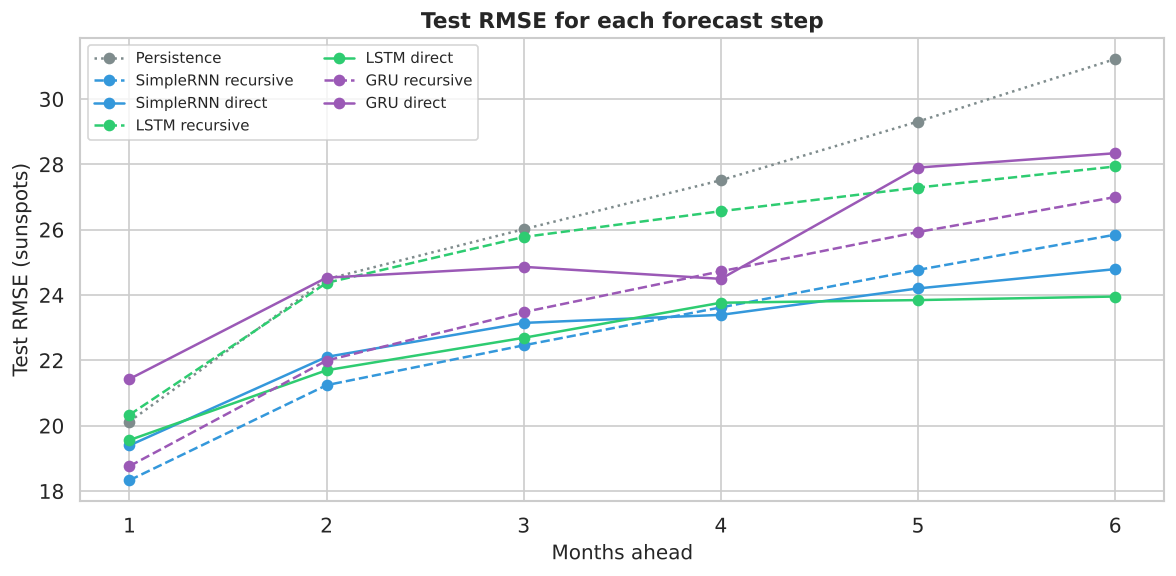

In [57]:
# Test RMSE for each forecast step: the three recurrent cells, dashed = recursive, solid = direct
fig, ax = plt.subplots(figsize=(10, 5))
steps = np.arange(1, FORECAST_HORIZON + 1)
ax.plot(steps, test_results_6['Persistence']['RMSE per step'], marker='o', linestyle=':',
        color=MODEL_COLORS['Persistence'], label='Persistence')
for kind in ['SimpleRNN'] + GATED:
    for approach, linestyle in [('recursive', '--'), ('direct', '-')]:
        ax.plot(steps, test_results_6[f'{kind} {approach}']['RMSE per step'], marker='o', linestyle=linestyle,
                color=MODEL_COLORS[kind], label=f'{kind} {approach}')
ax.set_title('Test RMSE for each forecast step', fontsize=13, fontweight='bold')
ax.set_xlabel('Months ahead')
ax.set_ylabel('Test RMSE (sunspots)')
ax.legend(fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

- The direct LSTM grows the least after the third month and ends as the best method at the sixth step.
- The recursive versions of LSTM and GRU grow the fastest.

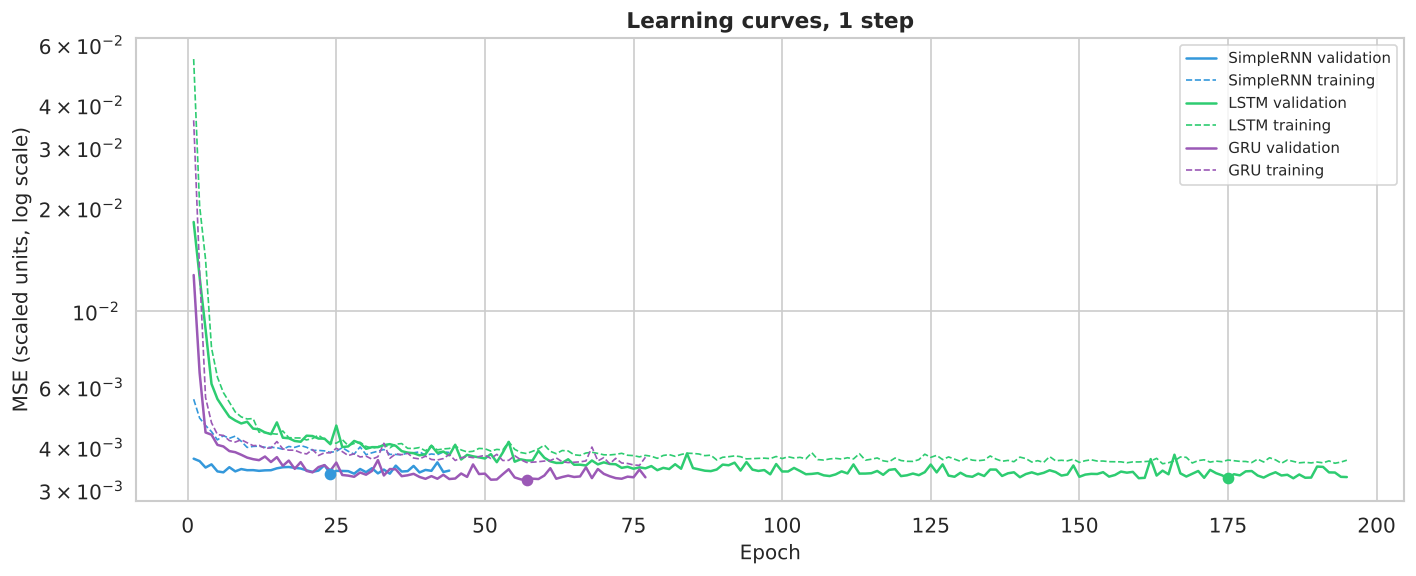

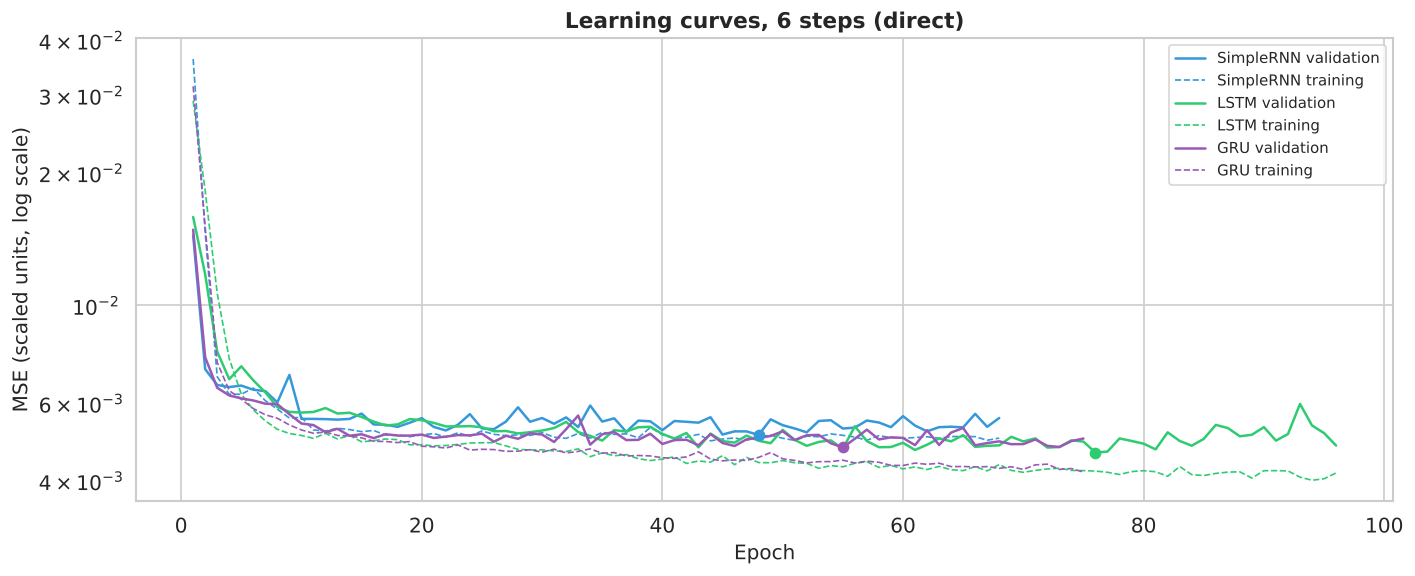

In [58]:
# Learning curves of the chosen 1-step and 6-step models
plot_learning_curves({'SimpleRNN': final_runs_1['SimpleRNN']['history']} |
                     {kind: gated_runs_1[kind]['history'] for kind in GATED}, 'Learning curves, 1 step')
plot_learning_curves({'SimpleRNN': direct_final['SimpleRNN']['history']} |
                     {kind: gated_runs_6[kind]['history'] for kind in GATED}, 'Learning curves, 6 steps (direct)')

- The gated cells need more epochs before early stopping (up to 195 for the one-step LSTM, against 44 for the Simple RNN).
- The training and validation losses stay close for all the models: no overfitting.

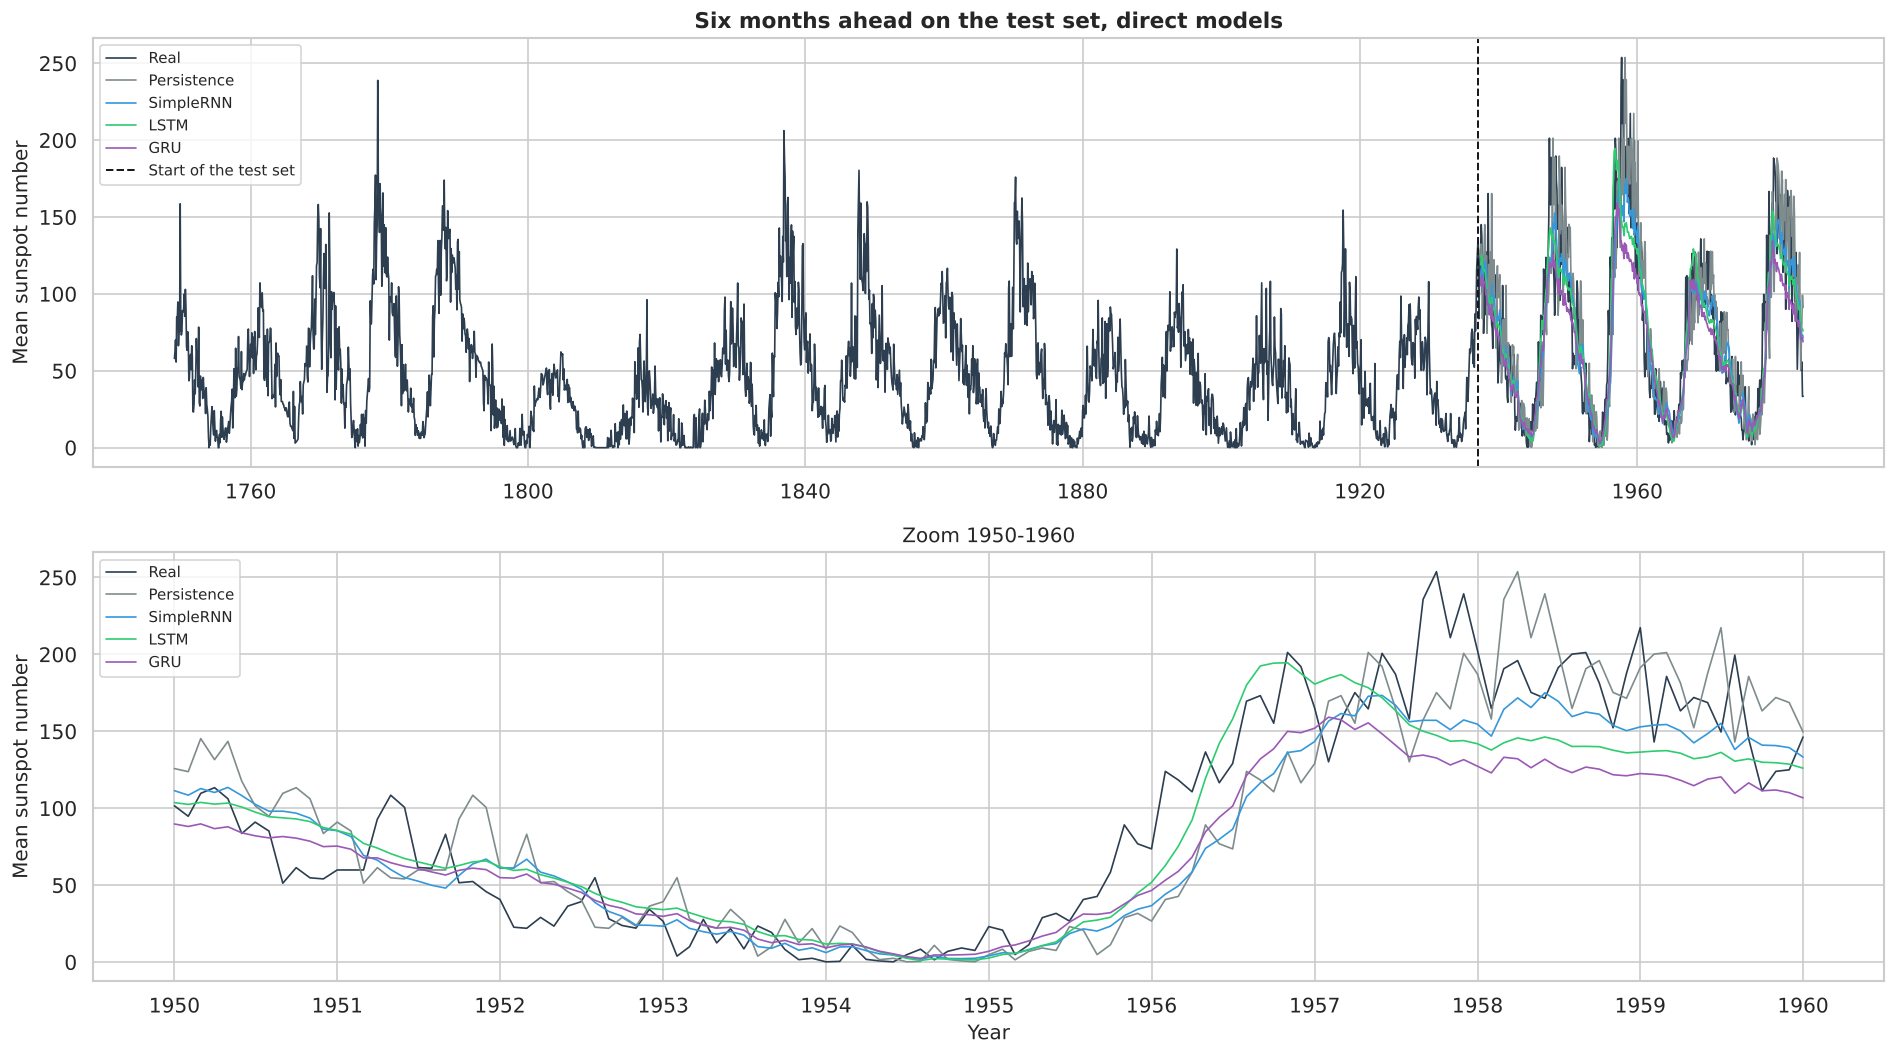

In [59]:
# Six months ahead with the direct models
plot_forecast({'Persistence': test_forecasts_6['Persistence']} |
              {kind: test_forecasts_6[f'{kind} direct'] for kind in ['SimpleRNN'] + GATED},
              'Six months ahead on the test set, direct models', step=FORECAST_HORIZON - 1)

- In the zoom, during the rise of 1956 the LSTM follows the real series more closely, while the Simple RNN and the GRU lag behind it: this is the advantage in the rising phase measured above.
- All three stay below the highest peaks of 1957-1958, and the GRU is the lowest of the three.

#### Summary of 6.5
The plots confirm the tables: the differences between the three cells are small compared with their gap from persistence, and the main advantage of the LSTM is at the end of the horizon.

### 6.6 Hidden states: PCA and UMAP

The head of every recurrent model sees only the **last hidden state** of the window: 64 numbers that summarise all the months it has read. If a model recognises the phase of the cycle, windows in the same phase should have similar states. The 559 test states, each with 64 coordinates, are projected to two dimensions with two methods.

**PCA (Principal Component Analysis)**, linear:
1. centre the data, subtracting the mean of each coordinate;
2. find the direction along which the points vary most (first principal component), then the perpendicular direction with the next largest variance (second component): they are the eigenvectors of the covariance matrix;
3. project every point on these two directions.

The **explained variance** is the share of the total variability kept by the two components: with 95% the plot shows almost all the differences between the states. Limit: PCA only sees linear structures, so points that lie on a curved surface can end up on top of each other.

**UMAP (Uniform Manifold Approximation and Projection)**, non-linear:
1. for every point find its `n_neighbors` nearest neighbours (15 by default) and build a weighted graph of which points are close;
2. place the points in two dimensions and move them so that connected points attract each other and unconnected points repel each other; `min_dist` (0.1 by default) sets how closely the points can be packed;
3. the result keeps the **neighbourhoods**: points that are close in 64 dimensions stay close in two.

Limit: the distances between far groups and the size of the groups have no precise meaning, and the layout depends slightly on the seed (fixed here).

A structure visible in both projections is reliable; one visible in only one of them is weak evidence. The states are standardised first, so that every hidden unit counts the same, and the points are coloured with the three phases of the six-step analysis (rising, stable or decaying in the next six months).

In this section we:
- compute the last hidden state of the three direct six-step models on the test windows;
- project the states with PCA and UMAP, coloured by phase;
- colour the PCA projection by the level of the last month, to see what its main structure represents.

In [60]:
@torch.no_grad()
def last_hidden_states(model, X):
    """Last hidden state of the recurrent layer for every window: (N, hidden), the input of the head."""
    model.eval()
    out, _ = model.rnn(torch.as_tensor(X, device=DEVICE))
    return out[:, -1, :].cpu().numpy()


# Last hidden states of the three direct 6-step models on the test windows
direct_runs_all = {'SimpleRNN': direct_final['SimpleRNN']} | {kind: gated_runs_6[kind] for kind in GATED}
hidden_states = {}
for kind, run in direct_runs_all.items():
    X_test, _, idx = run['data']['test']
    assert np.array_equal(idx, idx_test_6)               # same windows, in the same order, as the phases
    hidden_states[kind] = last_hidden_states(run['model'], X_test)
    print(f'{kind}: {hidden_states[kind].shape[0]} windows, hidden state of {hidden_states[kind].shape[1]} values')

SimpleRNN: 559 windows, hidden state of 64 values
LSTM: 559 windows, hidden state of 64 values
GRU: 559 windows, hidden state of 64 values


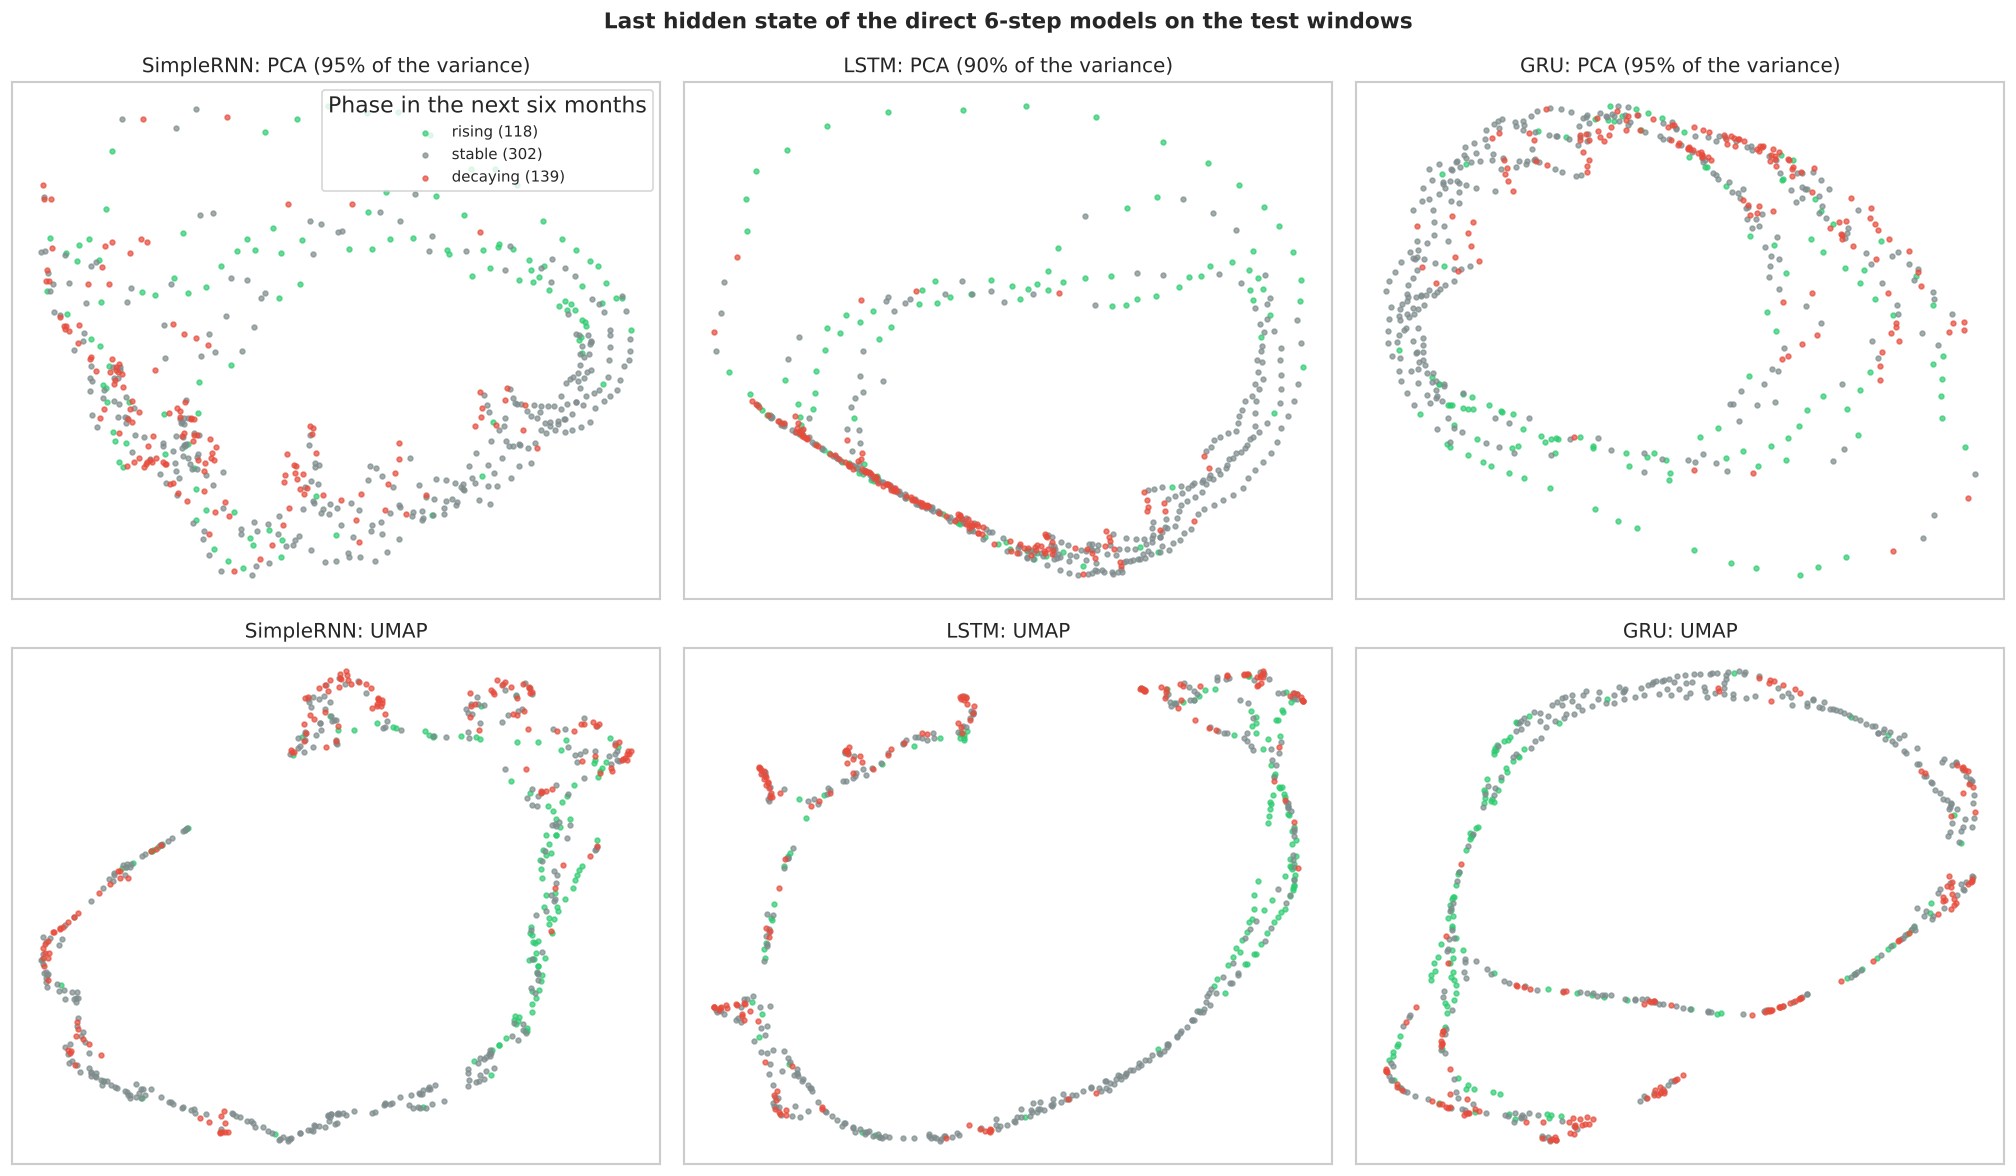

In [61]:
# PCA and UMAP of the hidden states, coloured by the phase of the cycle (same phases as before)
phase_colors = {'rising': MODEL_COLORS['LSTM'], 'stable': MODEL_COLORS['Persistence'], 'decaying': MODEL_COLORS['Dense']}
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
explained = {}
for col, (kind, states) in enumerate(hidden_states.items()):
    scaled_states = StandardScaler().fit_transform(states)          # same scale for every hidden unit
    pca = PCA(n_components=2).fit(scaled_states)
    explained[kind] = pca.explained_variance_ratio_.sum()
    projections = {'PCA': pca.transform(scaled_states),
                   'UMAP': umap.UMAP(random_state=SEED).fit_transform(scaled_states)}
    for row, (method, points) in enumerate(projections.items()):
        ax = axes[row, col]
        for p, color in phase_colors.items():
            mask = phase == p
            ax.scatter(points[mask, 0], points[mask, 1], s=8, alpha=0.7, color=color, label=f'{p} ({mask.sum()})')
        title = f'{kind}: {method}'
        if method == 'PCA':
            title += f' ({explained[kind]:.0%} of the variance)'
        ax.set_title(title, fontsize=12)
        ax.set_xticks([])
        ax.set_yticks([])
axes[0, 0].legend(fontsize=9, title='Phase in the next six months')
fig.suptitle('Last hidden state of the direct 6-step models on the test windows', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

- PCA: two components explain **95%** of the variance for the Simple RNN and the GRU and **90%** for the LSTM, so the plots show most of the differences between the states.
- In all six projections the states form a **ring**: windows that follow each other in time have similar states, and the series goes around the ring once per cycle.
- The phases are **not separated into groups**: rising and decaying windows lie along the same ring.
- Only in the PCA of the LSTM do the rising windows follow a separate branch (the upper arc), away from the decaying ones; UMAP does not confirm this separation.

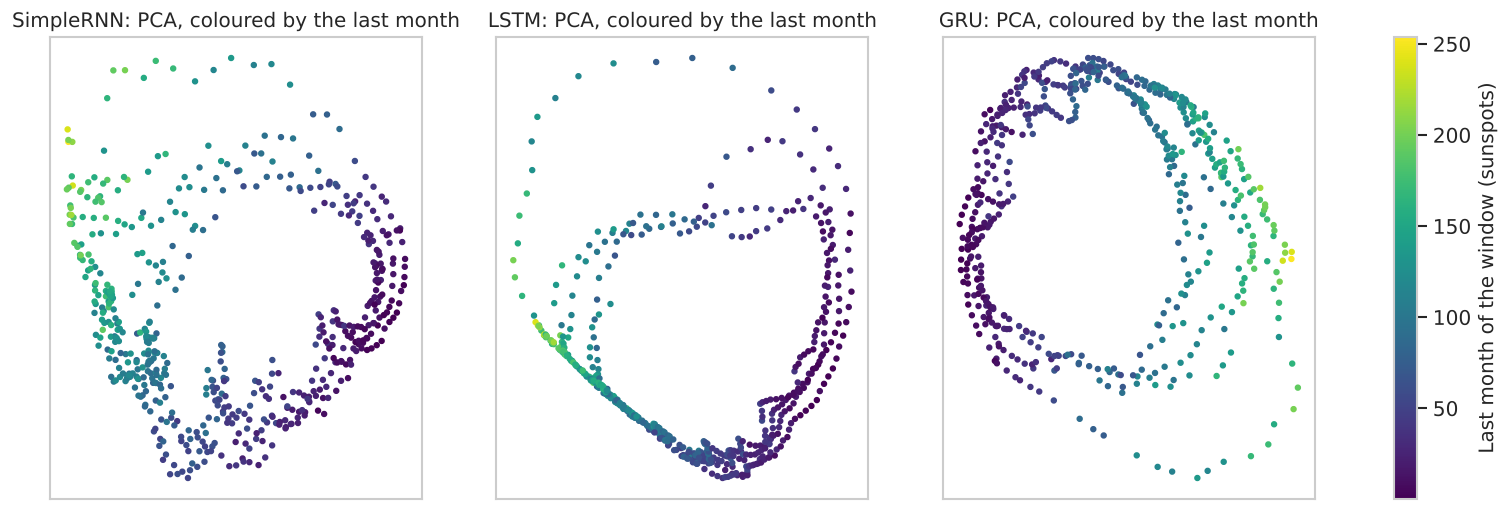

In [62]:
# Same projections coloured by the level of the last month of the window
last_month = to_sunspots(X_test_6[:, -1, :]).ravel()
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (kind, states) in zip(axes, hidden_states.items()):
    points = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(states))
    sc = ax.scatter(points[:, 0], points[:, 1], c=last_month, cmap='viridis', s=8)
    ax.set_title(f'{kind}: PCA, coloured by the last month', fontsize=12)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(sc, ax=axes, label='Last month of the window (sunspots)')
plt.show()

- The colour changes smoothly along the ring, from the quiet months (dark) to the peaks (yellow): the main information in the hidden state is the **current level** of the series, which is what the forecast needs most.
- The phase is a second, weaker piece of information, visible only where the same level is reached on two different branches, as in the LSTM.

#### Summary of 6.6
- The hidden states of the three cells mainly encode the level of the series, arranged as a ring that follows the cycle.
- None of the cells separates the phases clearly. The partial branch of the LSTM is consistent with its smaller error in the rising phase, but the projections alone are weak evidence.
- The projections help to interpret the results; they do not change them.

### 6.7 Parameter count & computational cost

A recurrent layer with F inputs and H hidden units has, for each transformation, H·F input weights, H² recurrent weights and two bias vectors of H values (PyTorch stores two of them):

$$\text{parameters} = k \, (H \cdot F + H^2 + 2H), \qquad k = 1 \text{ (Simple RNN)}, \; 3 \text{ (GRU)}, \; 4 \text{ (LSTM)}$$

Example with F = 1 and H = 64:

| Cell | Transformations k | Parameters |
| :---: | :---: | :---: |
| Simple RNN | 1 | 64 + 4096 + 128 = 4288 |
| GRU | 3 | 3 · 4288 = 12 864 |
| LSTM | 4 | 4 · 4288 = 17 152 |

In this section we:
- compare this formula with the number of parameters counted by PyTorch;
- report the epochs and the training time of the chosen models.

In [63]:
# Parameters of one recurrent layer: formula vs PyTorch
def recurrent_params(cell, hidden, inputs=1):
    """(input weights + recurrent weights + two bias vectors) times the number of transformations."""
    transformations = {'SimpleRNN': 1, 'GRU': 3, 'LSTM': 4}[cell]
    return transformations * (hidden * inputs + hidden ** 2 + 2 * hidden)


# One row for each chosen recurrent model, one and six months ahead
rows = []
for kind, horizon, run in ([('SimpleRNN', 1, final_runs_1['SimpleRNN']), ('SimpleRNN', FORECAST_HORIZON, direct_final['SimpleRNN'])] +
                           [(kind, 1, gated_runs_1[kind]) for kind in GATED] +
                           [(kind, FORECAST_HORIZON, gated_runs_6[kind]) for kind in GATED]):
    hidden = run['model'].head.in_features
    rows.append({'model': kind, 'horizon': horizon, 'hidden': hidden,
                 'recurrent layer (formula)': recurrent_params(kind, hidden),
                 'recurrent layer (PyTorch)': count_params(run['model'].rnn),
                 'whole model': count_params(run['model']),
                 'epochs': len(run['history']['loss']),
                 'training time (s)': run['train_time'],
                 'test RMSE': (test_results_1 if horizon == 1 else test_results_6)[kind if horizon == 1 else f'{kind} direct']['RMSE']})
display(pd.DataFrame(rows).round(2))
print(f'Models trained in this run: {cache_counts["trained"]}, loaded from saved_models: {cache_counts["loaded"]}')

,model,horizon,hidden,recurrent layer (formula),recurrent layer (PyTorch),whole model,epochs,training time (s),test RMSE
0,SimpleRNN,1,64,4288,4288,4353,44,9.62,18.290001
1,SimpleRNN,6,64,4288,4288,4678,68,27.07,22.910000
2,LSTM,1,32,4480,4480,4513,195,68.27,20.299999
3,GRU,1,64,12864,12864,12929,77,63.05,18.740000
4,LSTM,6,64,17152,17152,17542,96,31.62,22.639999
5,GRU,6,64,12864,12864,13254,75,80.80,25.370001


Models trained in this run: 0, loaded from saved_models: 209


- The formula gives exactly the number of parameters counted by PyTorch for the three cells.
- With the same hidden size the GRU has three times and the LSTM four times the parameters of the Simple RNN.
- Training time: 30 to 80 seconds for the gated cells against 10 to 27 for the Simple RNN (times measured when the models were trained, stored with the saved models).

#### Summary of 6.7
- The extra cost of the gated cells pays off only six months ahead, and only for the LSTM.
- One month ahead the Simple RNN and the Dense network give the same or better results at a fraction of the cost.

---
## 7. Conclusions

The final results on the test set, the answers to the questions of the project and the references.

### 7.1 Final comparison on the test set

All the chosen methods on the test set, in sunspots, in two tables (one month and six months ahead). The tables are computed from the results of the previous sections, so they always match the outputs above:
- RMSE, MAE (one step) or RMSE at the sixth step (six steps), and the gain with respect to persistence;
- mean ± standard deviation of the test RMSE over the three seeds;
- number of trainable parameters (for the recursive approach, those of the one-step model).

In [64]:
# Final comparison on the test set: every chosen method, one month and six months ahead
def seed_summary(table, name, column):
    """Mean ± standard deviation over the three seeds, as text."""
    values = table.loc[table.iloc[:, 0] == name, column]
    return f'{values.mean():.2f} ± {values.std():.2f}'


one_step_models = final_runs_1 | gated_runs_1             # chosen 1-step models
direct_models = direct_final | gated_runs_6               # chosen 6-step (direct) models

# One month ahead (Task 3 and Task 5)
rows = []
for name in ['Persistence', 'Dense', 'SimpleRNN', 'LSTM', 'GRU']:
    scores = test_results_1[name]
    rows.append({'method': name,
                 'test RMSE': round(float(scores['RMSE']), 2),
                 'test MAE': round(float(scores['MAE']), 2),
                 'gain vs persistence': f"{1 - scores['RMSE'] / test_results_1['Persistence']['RMSE']:.0%}",
                 'test RMSE, 3 seeds': '-' if name == 'Persistence' else seed_summary(seed_results_all_1, name, 'test RMSE'),
                 'parameters': 0 if name == 'Persistence' else count_params(one_step_models[name]['model'])})
summary_1 = pd.DataFrame(rows).set_index('method')

# Six months ahead (Task 4 and Task 5)
rows = []
for kind in ['Persistence'] + MODELS + GATED:
    for approach in ([''] if kind == 'Persistence' else ['recursive', 'direct']):
        name = f'{kind} {approach}'.strip()
        scores = test_results_6[name]
        model = None if kind == 'Persistence' else (one_step_models if approach == 'recursive' else direct_models)[kind]['model']
        rows.append({'method': name,
                     'test RMSE (6 steps)': round(float(scores['RMSE']), 2),
                     'test RMSE step 6': round(float(scores['RMSE per step'][-1]), 2),
                     'gain vs persistence': f"{1 - scores['RMSE'] / test_results_6['Persistence']['RMSE']:.0%}",
                     'test RMSE, 3 seeds': '-' if kind == 'Persistence' else seed_summary(seed_results_all_6, name, 'test RMSE'),
                     'step 6, 3 seeds': '-' if kind == 'Persistence' else seed_summary(seed_results_all_6, name, 'test RMSE step 6'),
                     'parameters': 0 if model is None else count_params(model)})
summary_6 = pd.DataFrame(rows).set_index('method')

print('One month ahead (test set)')
display(summary_1)
print(f'\nSix months ahead (test set)')
display(summary_6)

One month ahead (test set)


,test RMSE,test MAE,gain vs persistence,"test RMSE, 3 seeds",parameters
method,,,,,
Persistence,20.09,14.84,0%,-,0
Dense,18.23,13.06,9%,18.36 ± 0.24,2081
SimpleRNN,18.29,13.40,9%,18.51 ± 0.21,4353
LSTM,20.30,14.41,-1%,19.52 ± 0.70,4513
GRU,18.74,13.50,7%,18.67 ± 0.10,12929



Six months ahead (test set)


,test RMSE (6 steps),test RMSE step 6,gain vs persistence,"test RMSE, 3 seeds","step 6, 3 seeds",parameters
method,,,,,,
Persistence,26.69,31.23,0%,-,-,0
Dense recursive,22.59,25.24,15%,22.88 ± 1.34,25.83 ± 2.38,2081
Dense direct,22.52,25.08,16%,25.22 ± 2.39,27.17 ± 1.81,2246
SimpleRNN recursive,22.85,25.85,14%,23.57 ± 0.66,26.91 ± 0.96,4353
SimpleRNN direct,22.91,24.79,14%,22.92 ± 0.08,25.05 ± 0.26,4678
LSTM recursive,25.51,27.94,4%,24.31 ± 1.08,26.84 ± 0.99,4513
LSTM direct,22.64,23.96,15%,23.19 ± 0.48,24.81 ± 0.83,17542
GRU recursive,23.81,27.00,11%,23.45 ± 0.39,26.41 ± 0.59,12929
GRU direct,25.37,28.34,5%,23.99 ± 1.23,26.85 ± 1.67,13254


- **One month ahead** all the networks except the LSTM beat persistence by 7-9%; the Dense network reaches the lowest error with the fewest parameters.
- **Six months ahead** the gain is larger: 14-16% over the six steps for the Dense network, the Simple RNN and the direct LSTM, and up to 23% at the sixth step for the direct LSTM (23.96 against 31.23).
- Over three seeds, the most reliable six-step method is the direct Simple RNN (22.92 ± 0.08), while the lowest error at the sixth step belongs to the direct LSTM (24.81 ± 0.83).

### 7.2 Findings

**Data and preparation**
- 2820 consecutive months (1749-1983), with no gaps; the outliers are real solar maxima and are kept.
- The series follows a cycle of about 11 years: the autocorrelation has its minimum at 63 months and a second maximum at 125 months (about 10.4 years).
- The series is split in time; the test period (1937-1983) is the most active one, with its highest value above the training range. Every choice was made on the validation set, and the test set was used only to measure the final errors.

**One month ahead: Simple RNN vs Dense network**
- The Simple RNN works well: test RMSE **18.29** against 20.09 for persistence (about 9% lower).
- The Dense network reaches the same error (**18.23**); over three seeds the difference (18.36 ± 0.24 vs 18.51 ± 0.21) is smaller than the effect of the seed.
- The window length has almost no effect and the predictions stay close to the last month: one month ahead the last value carries most of the information, so the recurrent structure gives no advantage.

**Six months ahead: which approach works better?**
- The gain over persistence is larger than one month ahead, because persistence is a flat line, too low when the cycle rises and too high when it decays.
- The **recursive** approach is the best at the first step, where it is the one-step model, but its errors accumulate along the horizon.
- The **direct** approach is better at the later steps. For the Simple RNN it is the better choice: the lowest error at the sixth step among the Dense and Simple RNN methods (24.79) and the most stable across seeds (22.92 ± 0.08). For the Dense network the two approaches have similar errors, but the direct one depends strongly on the seed.
- All the networks correct the bias of persistence mainly in the decaying phases; the rises remain hard to anticipate.

**LSTM and GRU**
- The gated cells are the only models that profit from longer windows (48-125 months on the validation set), as the theory of the gates predicts.
- One month ahead this does not give a better test error (GRU 18.67 ± 0.10, LSTM 19.52 ± 0.70).
- Six months ahead the direct LSTM is the best method of the project at the sixth step (**23.96**; 24.81 ± 0.83 over three seeds) and the one that anticipates the rises best (mean error -26.8 against -42.3 for persistence), with about four times the parameters of the direct Simple RNN. The GRU does not confirm on the test set its advantage on the validation set.
- The hidden states of the three cells mainly encode the level of the series, arranged as a ring that follows the cycle; none of them separates the phases clearly.

**Other choices tested on the validation set**
| Choice | Result | Adopted |
| :--- | :--- | :--- |
| Square root before the scaling | more regular data, but no gain (3 of 8 better, average -0.01) | no |
| Dropout 0.2 | small or no differences | only where slightly lower: one-step Simple RNN, direct Dense |
| Predicting the change | better for the one-step Dense and Simple RNN; worse six months ahead and for LSTM and GRU | only for the one-step Dense and Simple RNN |
| Longer windows | no effect for the Dense network and the Simple RNN; small gains for LSTM and GRU | longer windows only for LSTM and GRU |

**Overall**
- One month ahead a small Dense network or Simple RNN is enough.
- Six months ahead the direct approach is preferable: with the Simple RNN when stability matters, with the LSTM when the error at the end of the horizon matters most.

**Limits**
- The validation period is short and quiet, so the differences between models on it are small and do not always predict the ranking on the test set (as for the one-step LSTM).
- Three seeds give only a rough estimate of the variability.
- The models use only the past of the series, and all of them stay below the highest peaks of the test set.

### 7.3 References

- Brownlee, J. *Monthly sunspots dataset*, `monthly-sunspots.csv`, github.com/jbrownlee/Datasets.
- Hochreiter, S., & Schmidhuber, J. (1997). *Long Short-Term Memory*. Neural Computation, 9(8).
- Cho, K., et al. (2014). *Learning Phrase Representations using RNN Encoder-Decoder for Statistical Machine Translation*. EMNLP.
- Kingma, D. P., & Ba, J. (2015). *Adam: A Method for Stochastic Optimization*. ICLR.
- Pascanu, R., Mikolov, T., & Bengio, Y. (2013). *On the difficulty of training recurrent neural networks*. ICML.
- Srivastava, N., et al. (2014). *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*. JMLR, 15.
- McInnes, L., Healy, J., & Melville, J. (2018). *UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction*. arXiv:1802.03426.